# Codigo base

In [1]:
source("utils.r")
source("erpt_lp.R")

# Cargar datos
Ferreres: Fundación Norte y Sur para PBIpm, ipc y E. USDA para precios commodities. NBER (1935 a 1956), FMI (1957 a 2012) y BLS (FRED) (2013 a 2023) para impp_usa

In [2]:
# Example of how to call the function
url <- "https://github.com/mbarrena/tesis/raw/refs/heads/main/data/Data%20anual%201935%202025%20Ferreres.xlsx"
temp_file <- tempfile(fileext = ".xlsx")
GET(url, write_disk(temp_file, overwrite = TRUE))

# Read the `data` from the Excel file
df_anual_crudo <- read_excel(temp_file)

Response [https://raw.githubusercontent.com/mbarrena/tesis/refs/heads/main/data/Data%20anual%201935%202025%20Ferreres.xlsx]
  Date: 2026-11-04 01:23
  Status: 200
  Content-Type: application/octet-stream
  Size: 19 kB
<ON DISK>  /var/folders/59/6k0yx0n916gg1mdb04zs42rm0000gn/T//Rtmp2pT8X7/file7f451a56f5bf.xlsxNULL

In [4]:
# Select specific columns and rows from df_trimestral_crudo
df_Arg <- df_anual_crudo |> 
  #dplyr::slice(37:dplyr::n()) |>  # Equivalent to iloc[36:] (1-based index in R)
  dplyr::select(año, ipc, E, PBIpm, impp_usa, Psoja_USA, Pmaíz_USA, Ptrigo_USA) |>  # nolint
  as.data.frame()  # Convert to data frame (if needed)


# Display first 6 rows
print(head(df_Arg))

# Display first 65 rows
print(head(df_Arg, 65))
print(tail(df_Arg, 6))

   año          ipc          E    PBIpm impp_usa Psoja_USA Pmaíz_USA Ptrigo_USA
1 1935 2.260997e-13 3.8022e-13 82259.96 4.405696 0.9775000 0.7735000  0.8595833
2 1936 2.452440e-13 3.5947e-13 82944.38 4.720389 0.9666667 0.7676667  0.9578333
3 1937 2.517236e-13 3.3289e-13 88955.01 5.276209 1.2591667 0.9477500  1.0713333
4 1938 2.500546e-13 3.9157e-13 89229.21 4.765345 0.7941667 0.4900833  0.6611667
5 1939 2.539817e-13 4.3280e-13 92644.74 4.826649 0.7716667 0.4761667  0.6355833
6 1940 2.596759e-13 4.3683e-13 94147.39 5.165863 0.8466667 1.0356667  0.7390833
    año          ipc            E     PBIpm  impp_usa Psoja_USA Pmaíz_USA
1  1935 2.260997e-13 3.802200e-13  82259.96  4.405696 0.9775000 0.7735000
2  1936 2.452440e-13 3.594700e-13  82944.38  4.720389 0.9666667 0.7676667
3  1937 2.517236e-13 3.328900e-13  88955.01  5.276209 1.2591667 0.9477500
4  1938 2.500546e-13 3.915700e-13  89229.21  4.765345 0.7941667 0.4900833
5  1939 2.539817e-13 4.328000e-13  92644.74  4.826649 0.7716667 0.4761

    año        ipc         E  PBIpm  impp_usa Psoja_USA Pmaíz_USA Ptrigo_USA
86 2020   862.9566  122.7550 624591  96.52317  8.984167  3.500833   4.857500
87 2021  1269.4501  170.2986 689810 105.06080 13.041667  5.396667   6.840000
88 2022  2197.7066  252.7147 731342 113.95991 14.850000  6.757500   9.300000
89 2023  5143.6307  628.1667 717806 110.43050 14.066667  5.949167   7.669167
90 2024 16613.7972 1188.3333 707988 111.22576 11.111667  4.264167   5.799167
91 2025 23732.4728 1321.6667 739729        NA 10.171667  4.285833   5.207500


In [5]:
# Copy df_Arg to df_ERPT_Arg1
df_ERPT_Arg1 <- df_Arg

# Display first rows
print(head(df_ERPT_Arg1))

# Apply logarithm to specific columns
df_ERPT_Arg1 <- makeLogColumns(c("ipc", "E", "PBIpm", "impp_usa", "Psoja_USA", "Pmaíz_USA", "Ptrigo_USA"), df_ERPT_Arg1) # nolint: line_length_linter.

# Display transformed dataframe
print(head(df_ERPT_Arg1))
print(tail(df_ERPT_Arg1))

   año          ipc          E    PBIpm impp_usa Psoja_USA Pmaíz_USA Ptrigo_USA
1 1935 2.260997e-13 3.8022e-13 82259.96 4.405696 0.9775000 0.7735000  0.8595833
2 1936 2.452440e-13 3.5947e-13 82944.38 4.720389 0.9666667 0.7676667  0.9578333
3 1937 2.517236e-13 3.3289e-13 88955.01 5.276209 1.2591667 0.9477500  1.0713333
4 1938 2.500546e-13 3.9157e-13 89229.21 4.765345 0.7941667 0.4900833  0.6611667
5 1939 2.539817e-13 4.3280e-13 92644.74 4.826649 0.7716667 0.4761667  0.6355833
6 1940 2.596759e-13 4.3683e-13 94147.39 5.165863 0.8466667 1.0356667  0.7390833
   año       ipc         E    PBIpm impp_usa   Psoja_USA   Pmaíz_USA
1 1935 -29.11780 -28.59803 11.31764 1.482898 -0.02275699 -0.25682961
2 1936 -29.03652 -28.65415 11.32593 1.551891 -0.03390155 -0.26439967
3 1937 -29.01044 -28.73096 11.39589 1.663208  0.23045013 -0.05366452
4 1938 -29.01710 -28.56861 11.39896 1.561370 -0.23046193 -0.71317983
5 1939 -29.00151 -28.46850 11.43653 1.574152 -0.25920260 -0.74198735
6 1940 -28.97934 -28.45923

In [6]:
# Create df_ERPT_Arg as a copy of df_Arg
df_ERPT_Arg <- df_Arg

# Display first rows
print(head(df_ERPT_Arg))

# Apply logarithm transformation
df_ERPT_Arg <- makeLogColumns(c("ipc", "E", "PBIpm", "impp_usa", "Psoja_USA", "Pmaíz_USA", "Ptrigo_USA"), df_ERPT_Arg)

# Display transformed dataframe
print(head(df_ERPT_Arg))

# Apply differencing transformation
df_ERPT_Arg <- makeDiffColumns(c("ipc", "E", "PBIpm", "impp_usa", "Psoja_USA", "Pmaíz_USA", "Ptrigo_USA"), df_ERPT_Arg)

# Display first and last rows
print(head(df_ERPT_Arg))
print(tail(df_ERPT_Arg, 90))

   año          ipc          E    PBIpm impp_usa Psoja_USA Pmaíz_USA Ptrigo_USA
1 1935 2.260997e-13 3.8022e-13 82259.96 4.405696 0.9775000 0.7735000  0.8595833
2 1936 2.452440e-13 3.5947e-13 82944.38 4.720389 0.9666667 0.7676667  0.9578333
3 1937 2.517236e-13 3.3289e-13 88955.01 5.276209 1.2591667 0.9477500  1.0713333
4 1938 2.500546e-13 3.9157e-13 89229.21 4.765345 0.7941667 0.4900833  0.6611667
5 1939 2.539817e-13 4.3280e-13 92644.74 4.826649 0.7716667 0.4761667  0.6355833
6 1940 2.596759e-13 4.3683e-13 94147.39 5.165863 0.8466667 1.0356667  0.7390833


   año       ipc         E    PBIpm impp_usa   Psoja_USA   Pmaíz_USA
1 1935 -29.11780 -28.59803 11.31764 1.482898 -0.02275699 -0.25682961
2 1936 -29.03652 -28.65415 11.32593 1.551891 -0.03390155 -0.26439967
3 1937 -29.01044 -28.73096 11.39589 1.663208  0.23045013 -0.05366452
4 1938 -29.01710 -28.56861 11.39896 1.561370 -0.23046193 -0.71317983
5 1939 -29.00151 -28.46850 11.43653 1.574152 -0.25920260 -0.74198735
6 1940 -28.97934 -28.45923 11.45262 1.642072 -0.16644821  0.03504534
   Ptrigo_USA
1 -0.15130750
2 -0.04308149
3  0.06890398
4 -0.41374933
5 -0.45321207
6 -0.30234460
   año          ipc            E       PBIpm    impp_usa   Psoja_USA
2 1936  0.081277791 -0.056119308 0.008285800  0.06899287 -0.01114456
3 1937  0.026078127 -0.076818619 0.069960376  0.11131677  0.26435168
4 1938 -0.006652343  0.162352194 0.003077797 -0.10183802 -0.46091206
5 1939  0.015582707  0.100111429 0.037563668  0.01278245 -0.02874067
6 1940  0.022172162  0.009268376 0.016089412  0.06791976  0.09275439
7 194

### Recorto Dataframe: 1935 a 2023

In [7]:
# Select specific columns and rows from df_anual_crudo
df_ERPT_Arg_1935_2023 <- df_ERPT_Arg |> 
  dplyr::slice(1: (dplyr::n()-2) ) |>  # Equivalent to iloc[:-2] (1-based index in R)
  dplyr::select(año, ipc, E, PBIpm, "impp_usa", Psoja_USA, Pmaíz_USA, Ptrigo_USA) |>  # nolint
  as.data.frame()  # Convert to data frame (if needed)


# Display first 6 rows
print(head(df_ERPT_Arg_1935_2023))

# Display first 6 rows
print(head(df_ERPT_Arg_1935_2023, 6))
print(tail(df_ERPT_Arg_1935_2023, 6))

   año          ipc            E       PBIpm    impp_usa   Psoja_USA
1 1936  0.081277791 -0.056119308 0.008285800  0.06899287 -0.01114456
2 1937  0.026078127 -0.076818619 0.069960376  0.11131677  0.26435168
3 1938 -0.006652343  0.162352194 0.003077797 -0.10183802 -0.46091206
4 1939  0.015582707  0.100111429 0.037563668  0.01278245 -0.02874067
5 1940  0.022172162  0.009268376 0.016089412  0.06791976  0.09275439
6 1941  0.026120888 -0.030801705 0.050942564  0.06434072  0.36461577
     Pmaíz_USA  Ptrigo_USA
1 -0.007570059  0.10822601
2  0.210735143  0.11198547
3 -0.659515310 -0.48265331
4 -0.028807512 -0.03946274
5  0.777032688  0.15086747
6 -0.477174434  0.12739580
   año          ipc            E       PBIpm    impp_usa   Psoja_USA
1 1936  0.081277791 -0.056119308 0.008285800  0.06899287 -0.01114456
2 1937  0.026078127 -0.076818619 0.069960376  0.11131677  0.26435168
3 1938 -0.006652343  0.162352194 0.003077797 -0.10183802 -0.46091206
4 1939  0.015582707  0.100111429 0.037563668  0.0127

    año       ipc         E       PBIpm    impp_usa   Psoja_USA   Pmaíz_USA
83 2018 0.2937482 0.5034727 -0.02652260  0.03081877 -0.02588909  0.03198124
84 2019 0.4240074 0.5982160 -0.02021149 -0.01279785 -0.08234478  0.07897016
85 2020 0.3398773 0.8660078 -0.10425586 -0.02528036  0.06396360 -0.06964330
86 2021 0.3859747 0.3273630  0.09931916  0.08475612  0.37268559  0.43278044
87 2022 0.5488306 0.3947080  0.05846501  0.08130752  0.12985051  0.22487152
88 2023 0.8503448 0.9105442 -0.01868187 -0.03146037 -0.05419193 -0.12740185
    Ptrigo_USA
83  0.14779803
84 -0.08096125
85  0.02378378
86  0.34226383
87  0.30722667
88 -0.19280644


### Recorto dataframe: 1935 a 1974

In [8]:
# Select specific columns and rows from df_anual_crudo
df_ERPT_Arg_1935_1974 <- df_ERPT_Arg |> 
  dplyr::slice(1:39 ) |>  # Equivalent to iloc[:-2] (1-based index in R)
  dplyr::select(año, ipc, E, PBIpm, impp_usa, Psoja_USA, Pmaíz_USA, Ptrigo_USA) |>  # nolint
  as.data.frame()  # Convert to data frame (if needed)


# Display first 6 rows
print(head(df_ERPT_Arg_1935_1974))

# Display first 6 rows
print(head(df_ERPT_Arg_1935_1974, 6))
print(tail(df_ERPT_Arg_1935_1974, 6))

   año          ipc            E       PBIpm    impp_usa   Psoja_USA
1 1936  0.081277791 -0.056119308 0.008285800  0.06899287 -0.01114456
2 1937  0.026078127 -0.076818619 0.069960376  0.11131677  0.26435168
3 1938 -0.006652343  0.162352194 0.003077797 -0.10183802 -0.46091206
4 1939  0.015582707  0.100111429 0.037563668  0.01278245 -0.02874067
5 1940  0.022172162  0.009268376 0.016089412  0.06791976  0.09275439
6 1941  0.026120888 -0.030801705 0.050942564  0.06434072  0.36461577
     Pmaíz_USA  Ptrigo_USA
1 -0.007570059  0.10822601
2  0.210735143  0.11198547
3 -0.659515310 -0.48265331
4 -0.028807512 -0.03946274
5  0.777032688  0.15086747
6 -0.477174434  0.12739580
   año          ipc            E       PBIpm    impp_usa   Psoja_USA
1 1936  0.081277791 -0.056119308 0.008285800  0.06899287 -0.01114456
2 1937  0.026078127 -0.076818619 0.069960376  0.11131677  0.26435168
3 1938 -0.006652343  0.162352194 0.003077797 -0.10183802 -0.46091206
4 1939  0.015582707  0.100111429 0.037563668  0.0127

### Recorto dataframe: 1935 a 1975

In [9]:
# Select specific columns and rows from df_anual_crudo
df_ERPT_Arg_1935_1975 <- df_ERPT_Arg |> 
  dplyr::slice(1:40 ) |>  # Equivalent to iloc[:-2] (1-based index in R)
  dplyr::select(año, ipc, E, PBIpm, impp_usa, Psoja_USA, Pmaíz_USA, Ptrigo_USA) |>  # nolint
  as.data.frame()  # Convert to data frame (if needed)


# Display first 6 rows
print(head(df_ERPT_Arg_1935_1975))

# Display first 6 rows
print(head(df_ERPT_Arg_1935_1975, 6))
print(tail(df_ERPT_Arg_1935_1975, 6))

   año          ipc            E       PBIpm    impp_usa   Psoja_USA
1 1936  0.081277791 -0.056119308 0.008285800  0.06899287 -0.01114456
2 1937  0.026078127 -0.076818619 0.069960376  0.11131677  0.26435168
3 1938 -0.006652343  0.162352194 0.003077797 -0.10183802 -0.46091206
4 1939  0.015582707  0.100111429 0.037563668  0.01278245 -0.02874067
5 1940  0.022172162  0.009268376 0.016089412  0.06791976  0.09275439
6 1941  0.026120888 -0.030801705 0.050942564  0.06434072  0.36461577
     Pmaíz_USA  Ptrigo_USA
1 -0.007570059  0.10822601
2  0.210735143  0.11198547
3 -0.659515310 -0.48265331
4 -0.028807512 -0.03946274
5  0.777032688  0.15086747
6 -0.477174434  0.12739580


   año          ipc            E       PBIpm    impp_usa   Psoja_USA
1 1936  0.081277791 -0.056119308 0.008285800  0.06899287 -0.01114456
2 1937  0.026078127 -0.076818619 0.069960376  0.11131677  0.26435168
3 1938 -0.006652343  0.162352194 0.003077797 -0.10183802 -0.46091206
4 1939  0.015582707  0.100111429 0.037563668  0.01278245 -0.02874067
5 1940  0.022172162  0.009268376 0.016089412  0.06791976  0.09275439
6 1941  0.026120888 -0.030801705 0.050942564  0.06434072  0.36461577
     Pmaíz_USA  Ptrigo_USA
1 -0.007570059  0.10822601
2  0.210735143  0.11198547
3 -0.659515310 -0.48265331
4 -0.028807512 -0.03946274
5  0.777032688  0.15086747
6 -0.477174434  0.12739580
    año       ipc           E        PBIpm   impp_usa   Psoja_USA   Pmaíz_USA
35 1970 0.1273162  0.09486991  0.052433439 0.06612261  0.06828364  0.08965436
36 1971 0.2980592  0.46405394  0.036929993 0.05041766  0.12229419  0.02691343
37 1972 0.4603004  0.62951162  0.020556971 0.07017832  0.11529120 -0.08244470
38 1973 0.471895

### Recorto dataframe: 1935 a 1982

In [10]:
# Select specific columns and rows from df_anual_crudo
df_ERPT_Arg_1935_1982 <- df_ERPT_Arg |> 
  dplyr::slice(1:47 ) |>  # Equivalent to iloc[:-2] (1-based index in R)
  dplyr::select(año, ipc, E, PBIpm, impp_usa, Psoja_USA, Pmaíz_USA, Ptrigo_USA) |>  # nolint
  as.data.frame()  # Convert to data frame (if needed)


# Display first 6 rows
print(head(df_ERPT_Arg_1935_1982))

# Display first 6 rows
print(head(df_ERPT_Arg_1935_1982, 6))
print(tail(df_ERPT_Arg_1935_1982, 6))

   año          ipc            E       PBIpm    impp_usa   Psoja_USA
1 1936  0.081277791 -0.056119308 0.008285800  0.06899287 -0.01114456
2 1937  0.026078127 -0.076818619 0.069960376  0.11131677  0.26435168
3 1938 -0.006652343  0.162352194 0.003077797 -0.10183802 -0.46091206
4 1939  0.015582707  0.100111429 0.037563668  0.01278245 -0.02874067
5 1940  0.022172162  0.009268376 0.016089412  0.06791976  0.09275439
6 1941  0.026120888 -0.030801705 0.050942564  0.06434072  0.36461577
     Pmaíz_USA  Ptrigo_USA
1 -0.007570059  0.10822601
2  0.210735143  0.11198547
3 -0.659515310 -0.48265331
4 -0.028807512 -0.03946274
5  0.777032688  0.15086747
6 -0.477174434  0.12739580
   año          ipc            E       PBIpm    impp_usa   Psoja_USA
1 1936  0.081277791 -0.056119308 0.008285800  0.06899287 -0.01114456
2 1937  0.026078127 -0.076818619 0.069960376  0.11131677  0.26435168
3 1938 -0.006652343  0.162352194 0.003077797 -0.10183802 -0.46091206
4 1939  0.015582707  0.100111429 0.037563668  0.0127

### Recorto dataframe: 1935 a 1987

In [11]:
# Select specific columns and rows from df_anual_crudo
df_ERPT_Arg_1935_1987 <- df_ERPT_Arg |> 
  dplyr::slice(1:52 ) |>  # Equivalent to iloc[:-2] (1-based index in R)
  dplyr::select(año, ipc, E, PBIpm, impp_usa, Psoja_USA, Pmaíz_USA, Ptrigo_USA) |>  # nolint
  as.data.frame()  # Convert to data frame (if needed)


# Display first 6 rows
print(head(df_ERPT_Arg_1935_1987))

# Display first 6 rows
print(head(df_ERPT_Arg_1935_1987, 6))
print(tail(df_ERPT_Arg_1935_1987, 6))

   año          ipc            E       PBIpm    impp_usa   Psoja_USA
1 1936  0.081277791 -0.056119308 0.008285800  0.06899287 -0.01114456
2 1937  0.026078127 -0.076818619 0.069960376  0.11131677  0.26435168
3 1938 -0.006652343  0.162352194 0.003077797 -0.10183802 -0.46091206
4 1939  0.015582707  0.100111429 0.037563668  0.01278245 -0.02874067
5 1940  0.022172162  0.009268376 0.016089412  0.06791976  0.09275439
6 1941  0.026120888 -0.030801705 0.050942564  0.06434072  0.36461577
     Pmaíz_USA  Ptrigo_USA
1 -0.007570059  0.10822601
2  0.210735143  0.11198547
3 -0.659515310 -0.48265331
4 -0.028807512 -0.03946274
5  0.777032688  0.15086747
6 -0.477174434  0.12739580
   año          ipc            E       PBIpm    impp_usa   Psoja_USA
1 1936  0.081277791 -0.056119308 0.008285800  0.06899287 -0.01114456
2 1937  0.026078127 -0.076818619 0.069960376  0.11131677  0.26435168
3 1938 -0.006652343  0.162352194 0.003077797 -0.10183802 -0.46091206
4 1939  0.015582707  0.100111429 0.037563668  0.0127

### Recorto dataframe: 1935 a 1990

In [12]:
# Select specific columns and rows from df_anual_crudo
df_ERPT_Arg_1935_1990 <- df_ERPT_Arg |> 
  dplyr::slice(1:55 ) |>  # Equivalent to iloc[:-2] (1-based index in R)
  dplyr::select(año, ipc, E, PBIpm, impp_usa, Psoja_USA, Pmaíz_USA, Ptrigo_USA) |>  # nolint
  as.data.frame()  # Convert to data frame (if needed)


# Display first 6 rows
print(head(df_ERPT_Arg_1935_1990))

# Display first 6 rows
print(head(df_ERPT_Arg_1935_1990, 6))
print(tail(df_ERPT_Arg_1935_1990, 6))

   año          ipc            E       PBIpm    impp_usa   Psoja_USA
1 1936  0.081277791 -0.056119308 0.008285800  0.06899287 -0.01114456
2 1937  0.026078127 -0.076818619 0.069960376  0.11131677  0.26435168
3 1938 -0.006652343  0.162352194 0.003077797 -0.10183802 -0.46091206
4 1939  0.015582707  0.100111429 0.037563668  0.01278245 -0.02874067
5 1940  0.022172162  0.009268376 0.016089412  0.06791976  0.09275439
6 1941  0.026120888 -0.030801705 0.050942564  0.06434072  0.36461577
     Pmaíz_USA  Ptrigo_USA
1 -0.007570059  0.10822601
2  0.210735143  0.11198547
3 -0.659515310 -0.48265331
4 -0.028807512 -0.03946274
5  0.777032688  0.15086747
6 -0.477174434  0.12739580
   año          ipc            E       PBIpm    impp_usa   Psoja_USA
1 1936  0.081277791 -0.056119308 0.008285800  0.06899287 -0.01114456
2 1937  0.026078127 -0.076818619 0.069960376  0.11131677  0.26435168
3 1938 -0.006652343  0.162352194 0.003077797 -0.10183802 -0.46091206
4 1939  0.015582707  0.100111429 0.037563668  0.0127

### Recorto Dataframe: 1950 a 2023

In [13]:
# Select specific columns and rows from df_anual_crudo
df_ERPT_Arg_1950_2023 <- df_ERPT_Arg |> 
  dplyr::slice(15: (dplyr::n()-2) ) |>  # Equivalent to iloc[:-2] (1-based index in R)
  dplyr::select(año, ipc, E, PBIpm, impp_usa, Psoja_USA, Pmaíz_USA, Ptrigo_USA) |>  # nolint
  as.data.frame()  # Convert to data frame (if needed)


# Display first 6 rows
print(head(df_ERPT_Arg_1950_2023))

# Display first 6 rows
print(head(df_ERPT_Arg_1950_2023, 6))
print(tail(df_ERPT_Arg_1950_2023, 6))

   año        ipc           E       PBIpm     impp_usa   Psoja_USA    Pmaíz_USA
1 1950 0.22743376  0.31152035  0.01206459  0.082406775  0.12350637  0.129514068
2 1951 0.31282829  0.39519786  0.03813796  0.226208507  0.16715891  0.198676336
3 1952 0.32648953 -0.03427928 -0.05164150 -0.054171851 -0.02362659  0.013258736
4 1953 0.03925671 -0.01670369  0.05164150 -0.041609249 -0.07697285 -0.131362665
5 1954 0.03777355  0.11462597  0.04045232  0.020513540  0.15063798  0.009200755
6 1955 0.11616312  0.18659437  0.06825331 -0.002032521 -0.28194043 -0.110653389
    Ptrigo_USA
1  0.032930065
2  0.067505298
3 -0.001968117
4 -0.061339022
5  0.028903746
6 -0.011461444
   año        ipc           E       PBIpm     impp_usa   Psoja_USA    Pmaíz_USA
1 1950 0.22743376  0.31152035  0.01206459  0.082406775  0.12350637  0.129514068
2 1951 0.31282829  0.39519786  0.03813796  0.226208507  0.16715891  0.198676336
3 1952 0.32648953 -0.03427928 -0.05164150 -0.054171851 -0.02362659  0.013258736
4 1953 0.039256

# Regresiones

### 1935-2023. Todas endógenas - Selected orders: 1 lag

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,NA,FALSE,FALSE,0,1,88,"impp_usa, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-0.2492428,-0.2492428,-0.2492428
2,impp_usa,E,1,1.3703217,0.3677020,2.3729414
3,impp_usa,E,2,1.9541817,0.7420221,3.1663414
4,impp_usa,E,3,0.7109552,-0.8073202,2.2292306
5,impp_usa,E,4,0.4092866,-1.2889555,2.1075288


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.00000000,0.0000000
37,ipc,E,1,-0.05643301,-0.30206728,0.1892013
38,ipc,E,2,-0.05225258,-0.32192185,0.2174167
39,ipc,E,3,0.09699308,-0.30949638,0.5034825
40,ipc,E,4,0.42408763,-0.09188411,0.9400594


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.0000000,0.00000000
52,PBIpm,E,1,0.3886647,-0.6075484,1.38487788
53,PBIpm,E,2,0.2902574,-0.9564801,1.53699491
54,PBIpm,E,3,-0.5814232,-2.0212503,0.85840402
55,PBIpm,E,4,-1.3735896,-2.6825218,-0.06465735


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
56,PBIpm,ipc,0,0.0000000,0.0000000,0.0000000
57,PBIpm,ipc,1,1.3342813,0.5812846,2.0872780
58,PBIpm,ipc,2,0.8142062,-0.2653890,1.8938014
59,PBIpm,ipc,3,-0.0881462,-1.5754770,1.3991846
60,PBIpm,ipc,4,-0.4798958,-1.5917199,0.6319283


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,E,PBIpm,0,-0.051276420,-0.051276420,-0.05127642
27,E,PBIpm,1,-0.015955611,-0.043078364,0.01116714
28,E,PBIpm,2,0.011673108,-0.009896387,0.03324260
29,E,PBIpm,3,0.001708160,-0.033769215,0.03718553
30,E,PBIpm,4,0.003446453,-0.019211943,0.02610485


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,impp_usa,PBIpm,0,0.22784896,0.22784896,0.22784896
12,impp_usa,PBIpm,1,-0.07695805,-0.17624099,0.02232488
13,impp_usa,PBIpm,2,-0.07877502,-0.16916217,0.01161213
14,impp_usa,PBIpm,3,0.05753865,-0.02453899,0.13961629
15,impp_usa,PBIpm,4,0.06577869,-0.05617327,0.18773065


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
41,ipc,PBIpm,0,-0.004597007,-0.004597007,-0.004597007
42,ipc,PBIpm,1,0.026226549,0.006490602,0.045962497
43,ipc,PBIpm,2,-0.006154636,-0.023584352,0.011275080
44,ipc,PBIpm,3,0.002452085,-0.023166769,0.028070938
45,ipc,PBIpm,4,-0.021620145,-0.041074538,-0.002165752


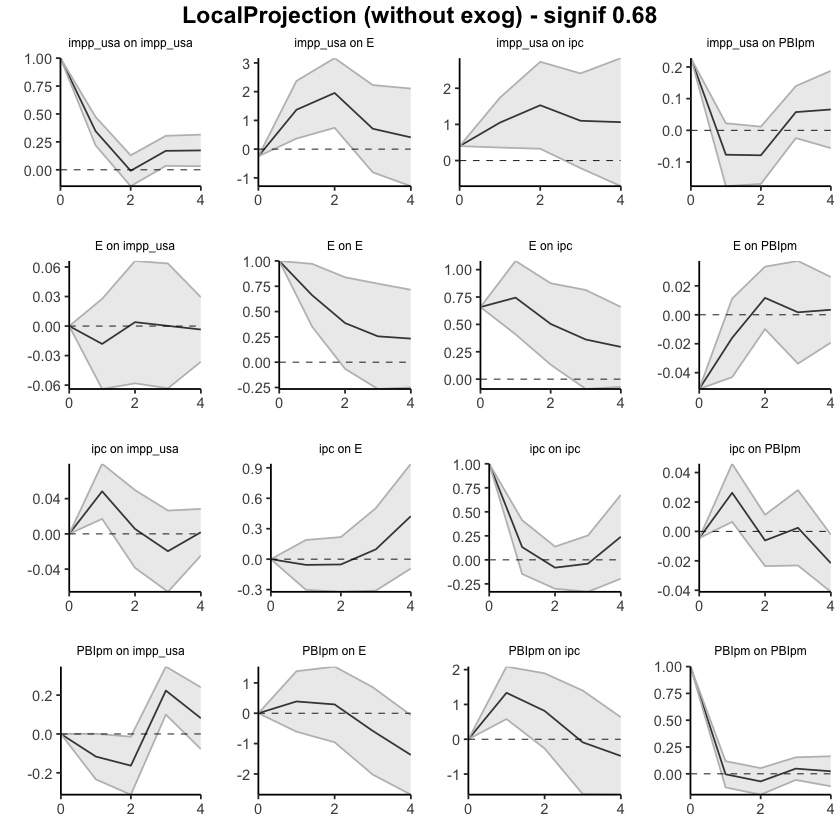

In [14]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("impp_usa", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<lgl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,NA,FALSE,FALSE,0,1,88,"impp_usa, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-0.2492428,-0.24924279,-0.2492428
2,impp_usa,E,1,1.1210789,0.11845923,2.1236986
3,impp_usa,E,2,3.0752607,0.86048133,5.2900400
4,impp_usa,E,3,3.7862159,0.05316117,7.5192706
5,impp_usa,E,4,4.1955025,-1.23579434,9.6267994


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.0000000
37,ipc,E,1,-0.05643301,-0.3020673,0.1892013
38,ipc,E,2,-0.10868559,-0.6239891,0.4066179
39,ipc,E,3,-0.01169251,-0.9334855,0.9101005
40,ipc,E,4,0.41239512,-1.0253696,1.8501599


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.00000000,0.0000000,0.000000
52,PBIpm,E,1,0.38866474,-0.6075484,1.384878
53,PBIpm,E,2,0.67892215,-1.5640285,2.921873
54,PBIpm,E,3,0.09749899,-3.5852788,3.780277
55,PBIpm,E,4,-1.27609061,-6.2678007,3.715619


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
56,PBIpm,ipc,0,0.000000,0.0000000,0.000000
57,PBIpm,ipc,1,1.334281,0.5812846,2.087278
58,PBIpm,ipc,2,2.148487,0.3158956,3.981079
59,PBIpm,ipc,3,2.060341,-1.2595814,5.380264
60,PBIpm,ipc,4,1.580446,-2.8513012,6.012192


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,E,PBIpm,0,-0.05127642,-0.05127642,-0.051276420
27,E,PBIpm,1,-0.06723203,-0.09435478,-0.040109278
28,E,PBIpm,2,-0.05555892,-0.10425117,-0.006866675
29,E,PBIpm,3,-0.05385076,-0.13802039,0.030318859
30,E,PBIpm,4,-0.05040431,-0.15723233,0.056423709


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,impp_usa,PBIpm,0,0.22784896,0.22784896,0.2278490
12,impp_usa,PBIpm,1,0.15089091,0.05160797,0.2501738
13,impp_usa,PBIpm,2,0.07211589,-0.11755420,0.2617860
14,impp_usa,PBIpm,3,0.12965453,-0.14209319,0.4014023
15,impp_usa,PBIpm,4,0.19543323,-0.19826646,0.5891329


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
41,ipc,PBIpm,0,-0.004597007,-0.004597007,-0.004597007
42,ipc,PBIpm,1,0.021629542,0.001893594,0.041365490
43,ipc,PBIpm,2,0.015474906,-0.021690758,0.052640570
44,ipc,PBIpm,3,0.017926991,-0.044857526,0.080711507
45,ipc,PBIpm,4,-0.003693154,-0.085932064,0.078545755


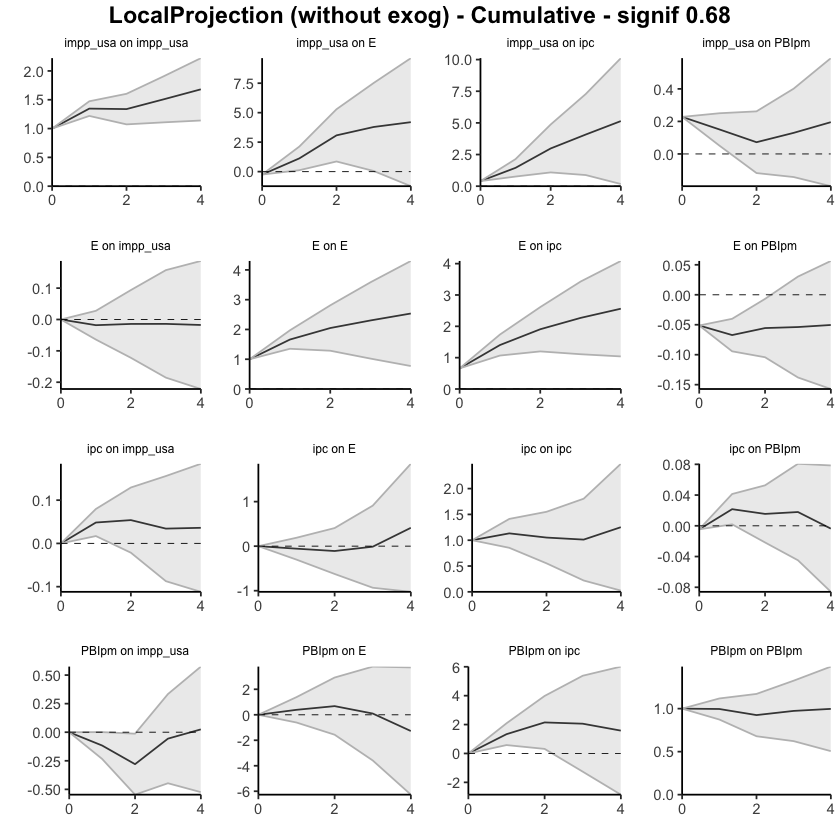

In [15]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("impp_usa", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, cumulative=TRUE)

#### Todas endógenas - 1 lag

Bootstrap por bloques circular: 500 réplicas, bloques de 10 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.6581         0.6581       1.0000
         1              1.4025         0.8442       1.6614
         2              1.9066         0.9310       2.0479
         3              2.2686         0.9849       2.3033
         4              2.5628         1.0105       2.5361
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.6581             0.6581
                  0.7443             0.1860
                  0.5041             0.0868
                  0.3620             0.0540
                  0.2942             0.0256


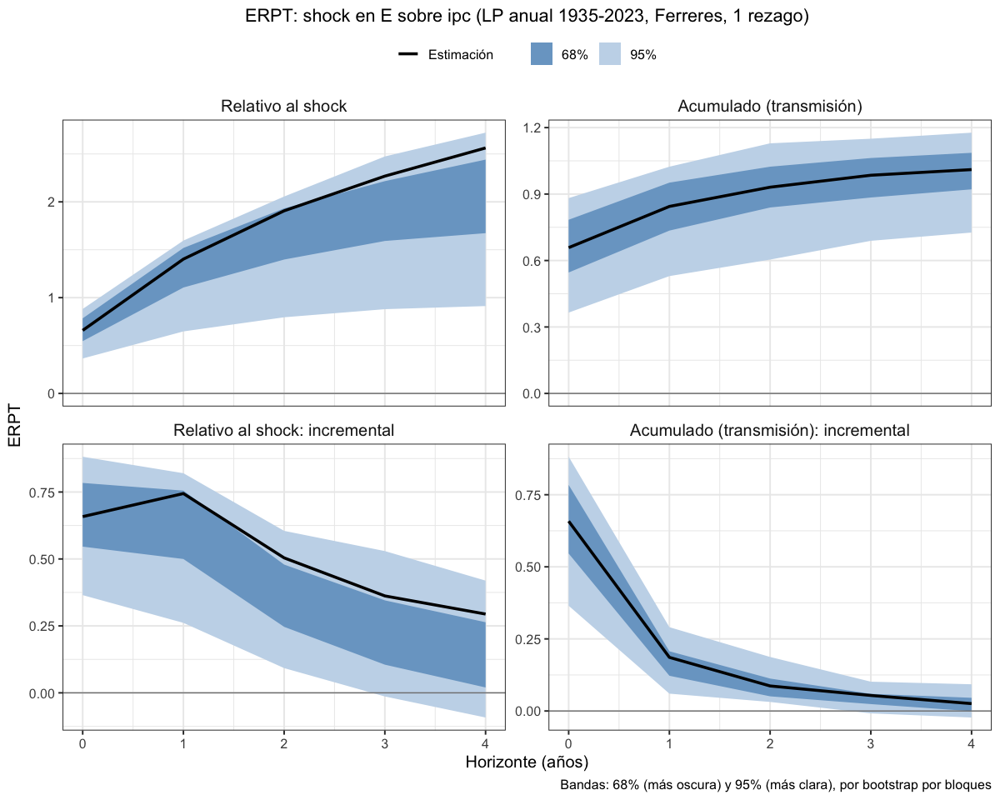

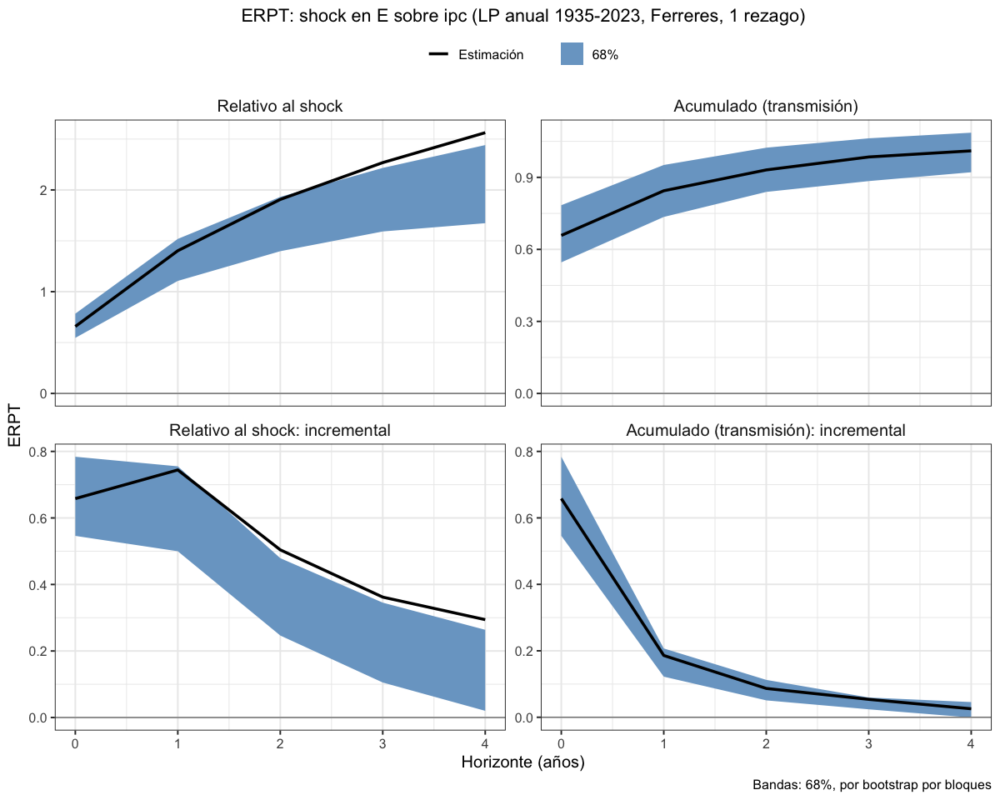

In [16]:
# Anual 1935–2023, Ferreres. Todas endógenas, 1 rezago
lp_erpt_anual_ferr_endog_p1 <- erpt_lp(df_ERPT_Arg_1935_2023, endog = c("impp_usa", "E", "ipc", "PBIpm"),
                                       fixed_lags = 1, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_ferr_endog_p1, "lp_erpt_anual_ferr_endog_p1.rds")
titulo_ferr <- "ERPT: shock en E sobre ipc (LP anual 1935-2023, Ferreres, 1 rezago)"
graficar_erpt_lp(lp_erpt_anual_ferr_endog_p1, titulo = titulo_ferr,
                 archivo = "lp_erpt_anual_ferr_endog_p1")
graficar_erpt_lp(lp_erpt_anual_ferr_endog_p1, titulo = titulo_ferr, niveles = 0.68,
                 archivo = "lp_erpt_anual_ferr_endog_p1_68")

### 1935-2023. 1 exógena y el resto endógenas - Selected orders: 1 lag

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,88,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.0000000
12,ipc,E,1,-0.04802822,-0.3152054,0.2191490
13,ipc,E,2,-0.04597582,-0.3426055,0.2506539
14,ipc,E,3,0.08441992,-0.3532055,0.5220454
15,ipc,E,4,0.39438403,-0.1498931,0.9386612


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.00000000
22,PBIpm,E,1,0.3886647,-0.6075484,1.38487788
23,PBIpm,E,2,0.2902574,-0.9564801,1.53699491
24,PBIpm,E,3,-0.5814232,-2.0212503,0.85840402
25,PBIpm,E,4,-1.3735896,-2.6825218,-0.06465735


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6548991,0.65489912,0.6548991
2,E,ipc,1,0.7422235,0.40901946,1.0754276
3,E,ipc,2,0.5033402,0.13372195,0.8729585
4,E,ipc,3,0.3622459,-0.08701928,0.8115112
5,E,ipc,4,0.2940620,-0.06746910,0.6555931


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.0000000
27,PBIpm,ipc,1,1.3342813,0.5812846,2.0872780
28,PBIpm,ipc,2,0.8142062,-0.2653890,1.8938014
29,PBIpm,ipc,3,-0.0881462,-1.5754770,1.3991846
30,PBIpm,ipc,4,-0.4798958,-1.5917199,0.6319283


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.052513390,-0.052513390,-0.05251339
7,E,PBIpm,1,-0.016035565,-0.042941015,0.01086988
8,E,PBIpm,2,0.011781656,-0.009576519,0.03313983
9,E,PBIpm,3,0.001639523,-0.033622608,0.03690165
10,E,PBIpm,4,0.003487040,-0.018932933,0.02590701


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,0.017027788,0.017027788,0.017027788
17,ipc,PBIpm,1,0.026136662,0.003754032,0.048519291
18,ipc,PBIpm,2,-0.007684453,-0.027786839,0.012417932
19,ipc,PBIpm,3,0.003500163,-0.024399832,0.031400159
20,ipc,PBIpm,4,-0.021108595,-0.043590280,0.001373091


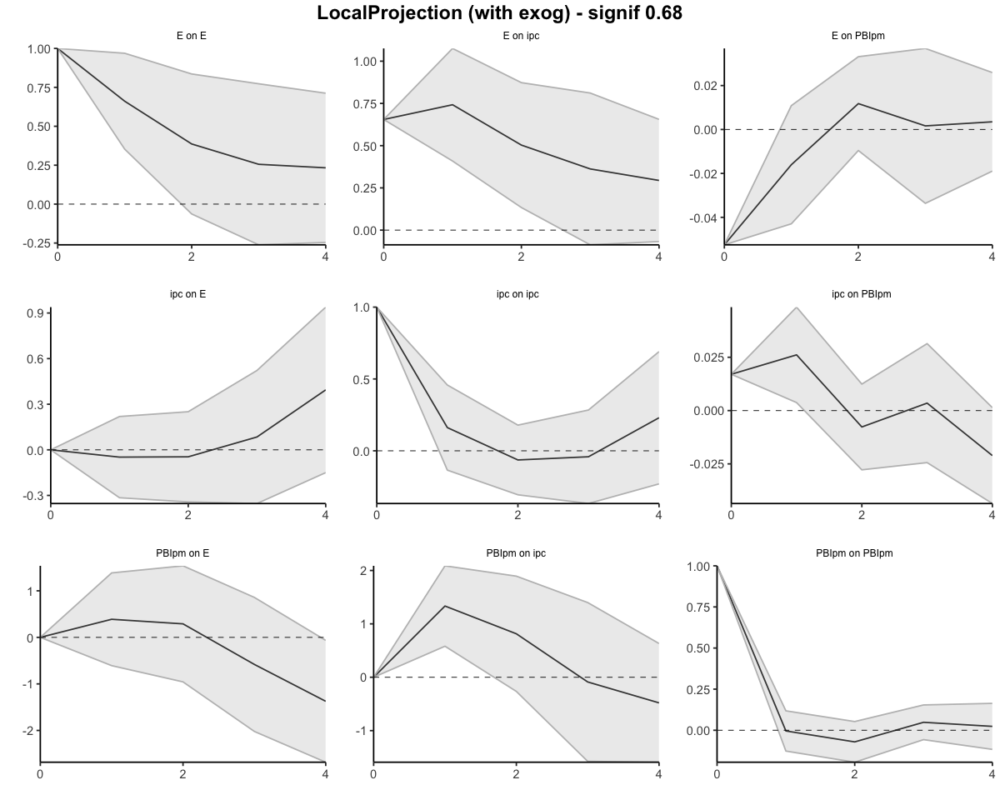

In [18]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("E", "ipc", "PBIpm"), exog=c("impp_usa"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,88,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.000000000,0.0000000,0.0000000
12,ipc,E,1,-0.048028218,-0.3152054,0.2191490
13,ipc,E,2,-0.094004038,-0.6578109,0.4698029
14,ipc,E,3,-0.009584115,-1.0110164,0.9918482
15,ipc,E,4,0.384799919,-1.1609095,1.9305094


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.00000000,0.0000000,0.000000
22,PBIpm,E,1,0.38866474,-0.6075484,1.384878
23,PBIpm,E,2,0.67892215,-1.5640285,2.921873
24,PBIpm,E,3,0.09749899,-3.5852788,3.780277
25,PBIpm,E,4,-1.27609061,-6.2678007,3.715619


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6548991,0.6548991,0.6548991
2,E,ipc,1,1.3971227,1.0639186,1.7303267
3,E,ipc,2,1.9004629,1.1976405,2.6032852
4,E,ipc,3,2.2627088,1.1106212,3.4147964
5,E,ipc,4,2.5567708,1.0431521,4.0703895


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.334281,0.5812846,2.087278
28,PBIpm,ipc,2,2.148487,0.3158956,3.981079
29,PBIpm,ipc,3,2.060341,-1.2595814,5.380264
30,PBIpm,ipc,4,1.580446,-2.8513012,6.012192


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.05251339,-0.05251339,-0.052513390
7,E,PBIpm,1,-0.06854895,-0.09545440,-0.041643505
8,E,PBIpm,2,-0.05676730,-0.10503092,-0.008503674
9,E,PBIpm,3,-0.05512778,-0.13865353,0.028397979
10,E,PBIpm,4,-0.05164074,-0.15758646,0.054304992


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,0.01702779,0.017027788,0.01702779
17,ipc,PBIpm,1,0.04316445,0.020781820,0.06554708
18,ipc,PBIpm,2,0.03548000,-0.007005019,0.07796501
19,ipc,PBIpm,3,0.03898016,-0.031404851,0.10936517
20,ipc,PBIpm,4,0.01787157,-0.074995132,0.11073826


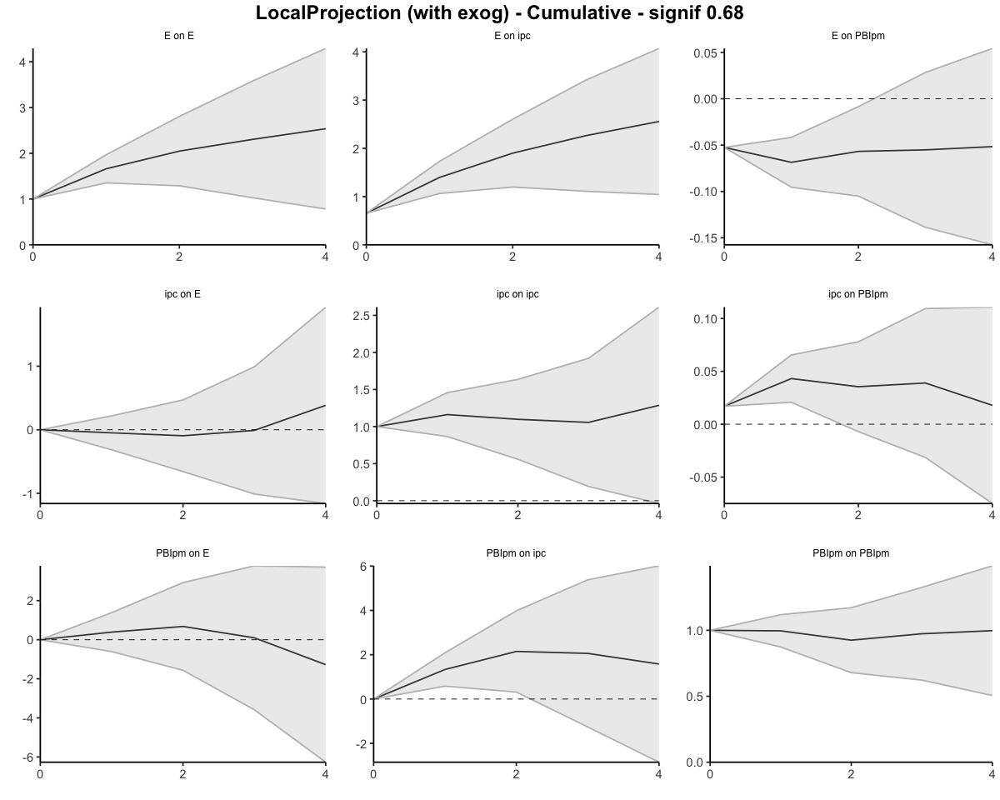

In [19]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("E", "ipc", "PBIpm"), exog=c("impp_usa"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

#### impp_usa exógena y el resto endógenas - 1 lag

Bootstrap por bloques circular: 500 réplicas, bloques de 10 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos, exógenas: impp_usa )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.6549         0.6549       1.0000
         1              1.3971         0.8411       1.6611
         2              1.9005         0.9282       2.0474
         3              2.2627         0.9824       2.3032
         4              2.5568         1.0080       2.5364
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.6549             0.6549
                  0.7422             0.1862
                  0.5033             0.0871
                  0.3622             0.0542
                  0.2941             0.0256


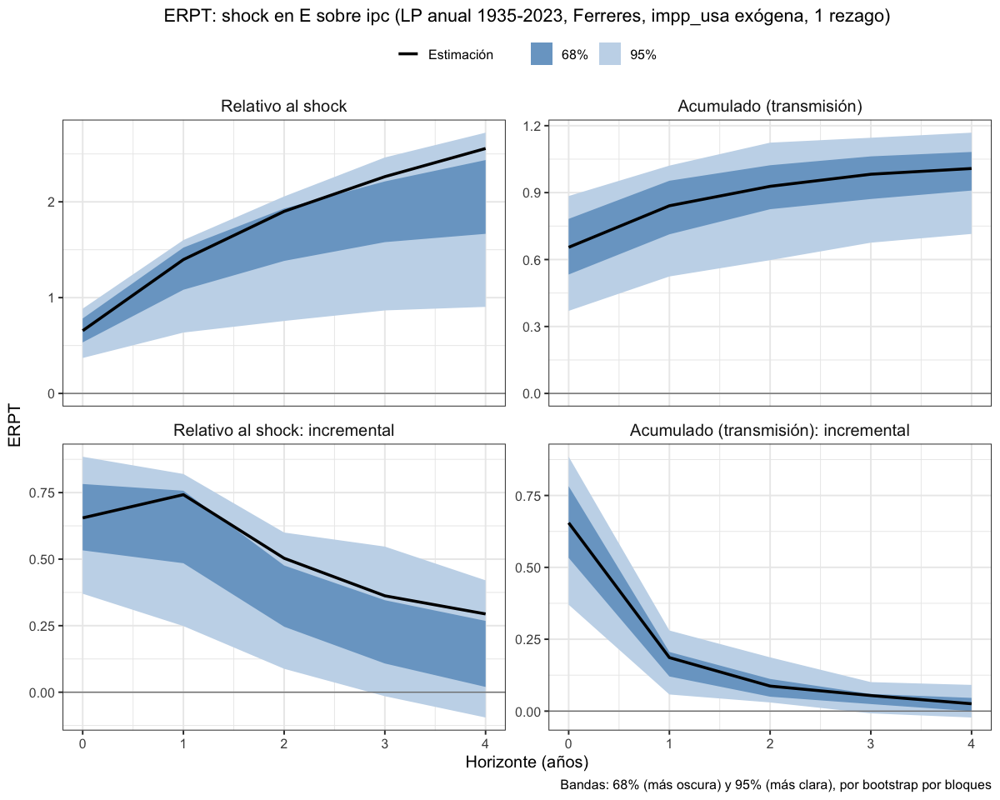

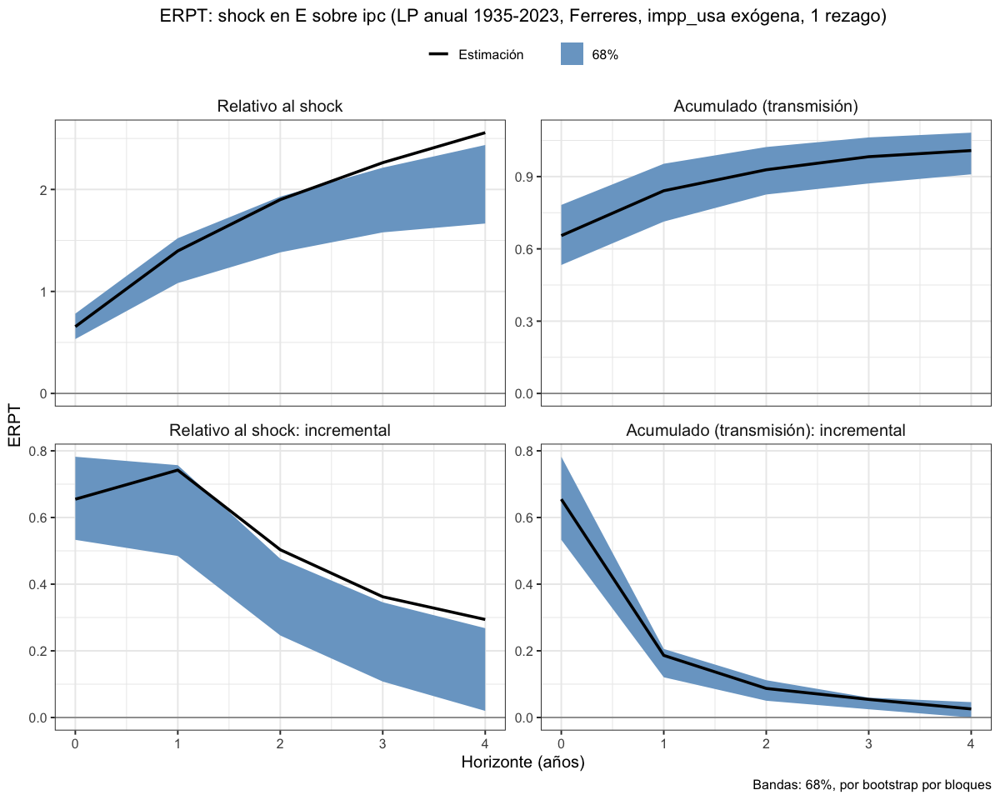

In [17]:
# Anual 1935–2023, Ferreres. impp_usa exógena y el resto endógenas, 1 rezago
lp_erpt_anual_ferr_exog_p1 <- erpt_lp(df_ERPT_Arg_1935_2023, endog = c("E", "ipc", "PBIpm"), exog = c("impp_usa"),
                                       fixed_lags = 1, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_ferr_exog_p1, "lp_erpt_anual_ferr_exog_p1.rds")
titulo_ferr_exog <- "ERPT: shock en E sobre ipc (LP anual 1935-2023, Ferreres, impp_usa exógena, 1 rezago)"
graficar_erpt_lp(lp_erpt_anual_ferr_exog_p1, titulo = titulo_ferr_exog,
                 archivo = "lp_erpt_anual_ferr_exog_p1")
graficar_erpt_lp(lp_erpt_anual_ferr_exog_p1, titulo = titulo_ferr_exog, niveles = 0.68,
                 archivo = "lp_erpt_anual_ferr_exog_p1_68")

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,88,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.00000000
12,ipc,E,1,0.1591039,-0.1467308,0.46493867
13,ipc,E,2,-0.2952495,-0.6799552,0.08945623
14,ipc,E,3,-0.7700599,-1.4179692,-0.12215060
15,ipc,E,4,-0.2221027,-0.7116387,0.26743333


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.0000000
22,PBIpm,E,1,0.7063868,-0.2048505,1.6176240
23,PBIpm,E,2,-0.1756122,-1.0267716,0.6755472
24,PBIpm,E,3,-1.7392529,-2.8269362,-0.6515696
25,PBIpm,E,4,-2.3583762,-4.0668090,-0.6499433


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6467939,0.64679390,0.6467939
2,E,ipc,1,0.8057109,0.55434487,1.0570769
3,E,ipc,2,0.4502969,-0.06894919,0.9695430
4,E,ipc,3,0.1963427,-0.56906273,0.9617482
5,E,ipc,4,0.1624836,-0.52184852,0.8468158


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.0000000
27,PBIpm,ipc,1,1.8486182,1.0902665,2.6069699
28,PBIpm,ipc,2,0.4879443,-0.2843019,1.2601906
29,PBIpm,ipc,3,-1.1427170,-2.0939540,-0.1914800
30,PBIpm,ipc,4,-1.6148424,-2.8562966,-0.3733883


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.051190762,-0.05119076,-0.051190762
7,E,PBIpm,1,-0.025027299,-0.05535125,0.005296652
8,E,PBIpm,2,0.010150560,-0.01876892,0.039070045
9,E,PBIpm,3,0.004353541,-0.04355278,0.052259864
10,E,PBIpm,4,0.002087921,-0.02526503,0.029440872


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,0.036829593,0.036829593,0.03682959
17,ipc,PBIpm,1,-0.012686662,-0.042289901,0.01691658
18,ipc,PBIpm,2,-0.011089337,-0.040654990,0.01847631
19,ipc,PBIpm,3,0.041600894,-0.003754392,0.08695618
20,ipc,PBIpm,4,0.001935354,-0.030786178,0.03465689


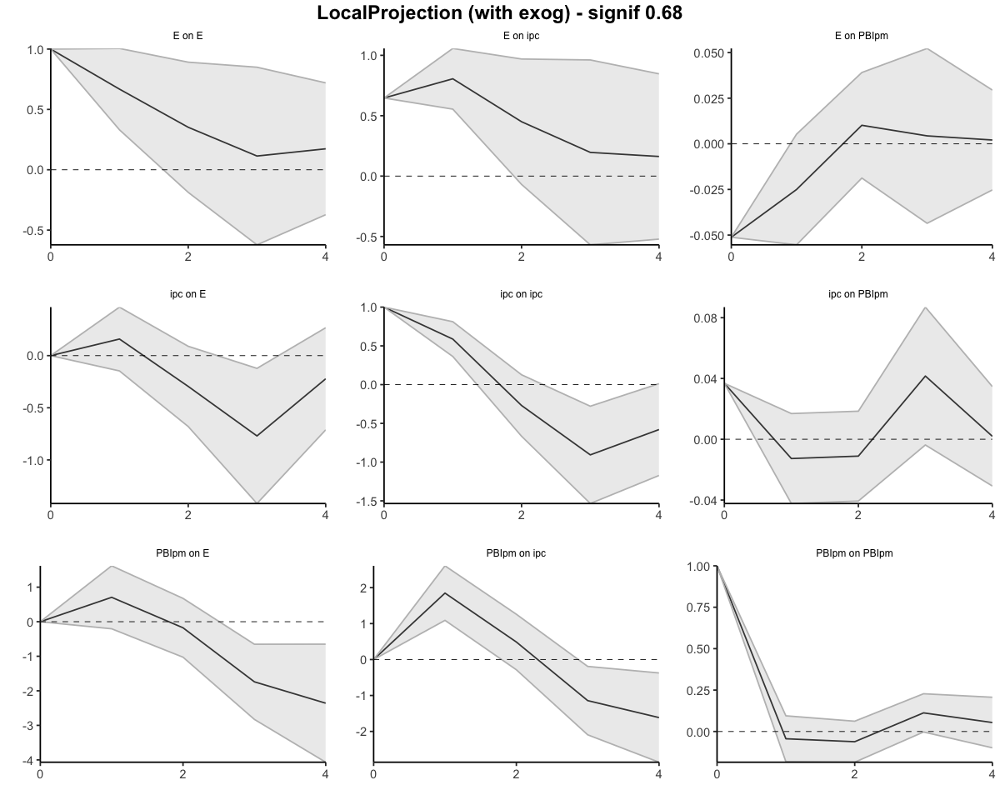

In [20]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("E", "ipc", "PBIpm"), exog=c("impp_usa"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,88,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.0000000
12,ipc,E,1,0.1591039,-0.1467308,0.4649387
13,ipc,E,2,-0.1361456,-0.8266860,0.5543949
14,ipc,E,3,-0.9062055,-2.2446552,0.4322443
15,ipc,E,4,-1.1283081,-2.9562939,0.6996776


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.0000000
22,PBIpm,E,1,0.7063868,-0.2048505,1.6176240
23,PBIpm,E,2,0.5307746,-1.2316221,2.2931712
24,PBIpm,E,3,-1.2084783,-4.0585583,1.6416017
25,PBIpm,E,4,-3.5668545,-8.1253673,0.9916583


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6467939,0.64679390,0.6467939
2,E,ipc,1,1.4525048,1.20113877,1.7038708
3,E,ipc,2,1.9028017,1.13218957,2.6734138
4,E,ipc,3,2.0991444,0.56312684,3.6351620
5,E,ipc,4,2.2616281,0.04127832,4.4819778


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.8486182,1.0902665,2.606970
28,PBIpm,ipc,2,2.3365625,0.8059646,3.867160
29,PBIpm,ipc,3,1.1938456,-1.2879894,3.675681
30,PBIpm,ipc,4,-0.4209968,-4.1442859,3.302292


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.05119076,-0.05119076,-0.051190762
7,E,PBIpm,1,-0.07621806,-0.10654201,-0.045894110
8,E,PBIpm,2,-0.06606750,-0.12531094,-0.006824065
9,E,PBIpm,3,-0.06171396,-0.16886372,0.045435800
10,E,PBIpm,4,-0.05962604,-0.19412875,0.074876672


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,0.03682959,0.036829593,0.03682959
17,ipc,PBIpm,1,0.02414293,-0.005460307,0.05374617
18,ipc,PBIpm,2,0.01305359,-0.046115297,0.07222249
19,ipc,PBIpm,3,0.05465449,-0.049869689,0.15917867
20,ipc,PBIpm,4,0.05658984,-0.080655866,0.19383555


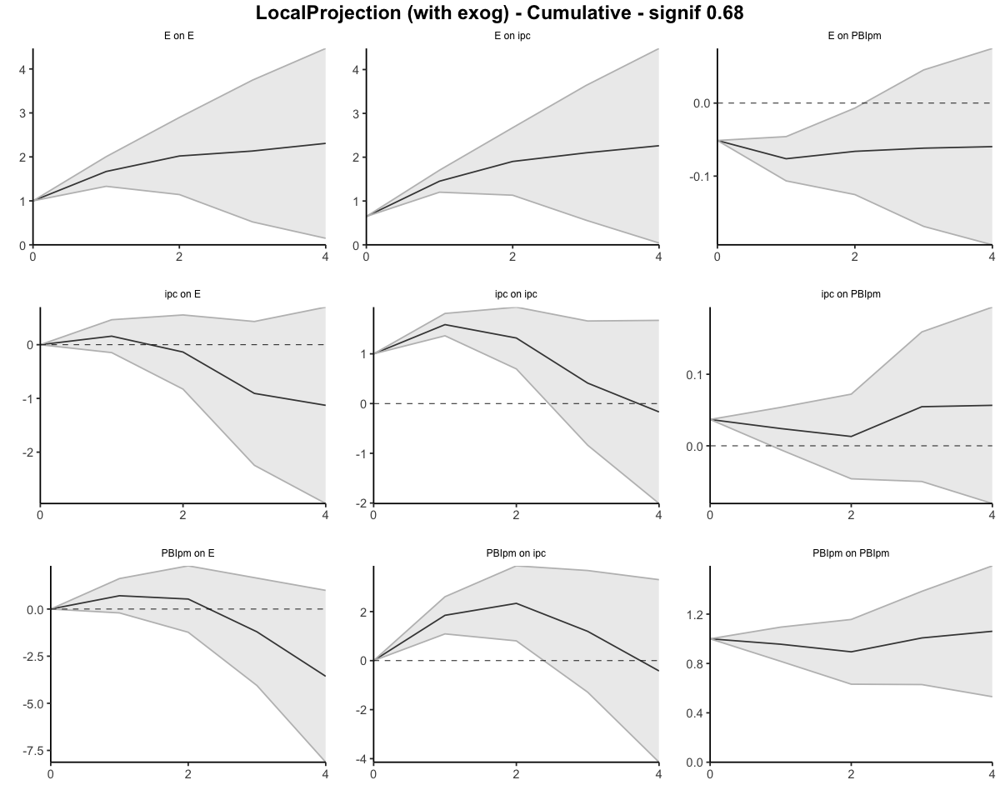

In [21]:
res <- run_lp_model(df_ERPT_Arg_1935_2023, endog=c("E", "ipc", "PBIpm"), exog=c("impp_usa"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

#### impp_usa exógena y el resto endógenas - 2 lags

Bootstrap por bloques circular: 500 réplicas, bloques de 12 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 2 rezagos, exógenas: impp_usa )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.6468         0.6468       1.0000
         1              1.4525         0.8707       1.6681
         2              1.9028         0.9419       2.0202
         3              2.0991         0.9837       2.1340
         4              2.2616         0.9800       2.3077
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.6468             0.6468
                  0.8057             0.2239
                  0.4503             0.0711
                  0.1963             0.0418
                  0.1625            -0.0036


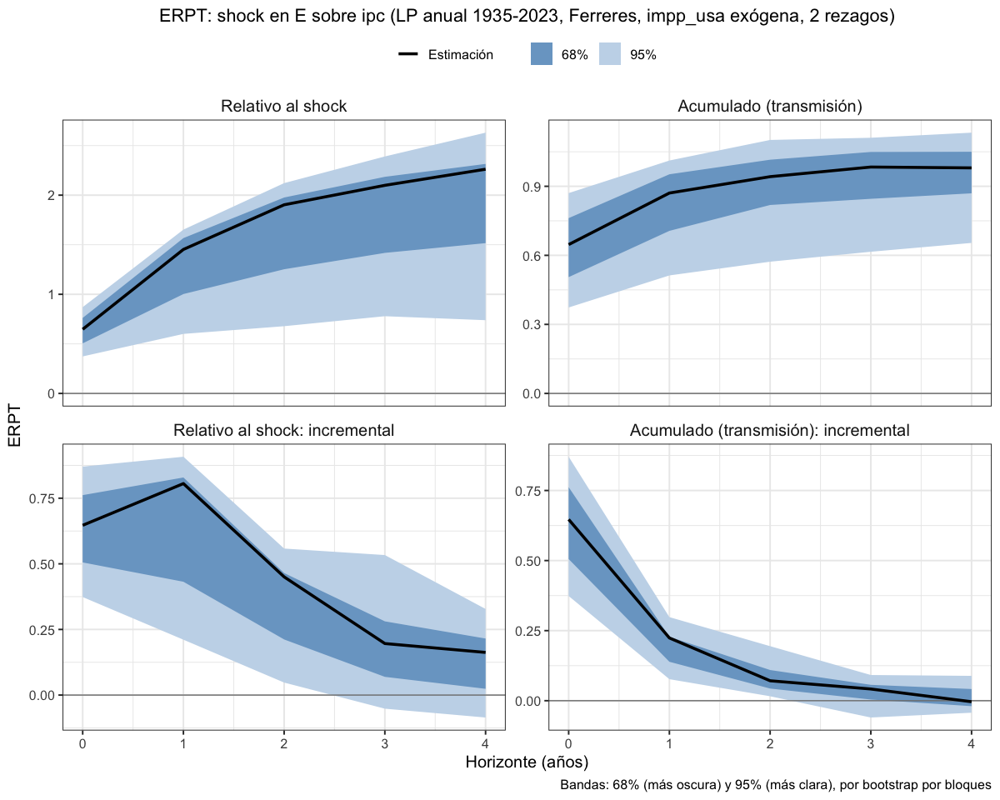

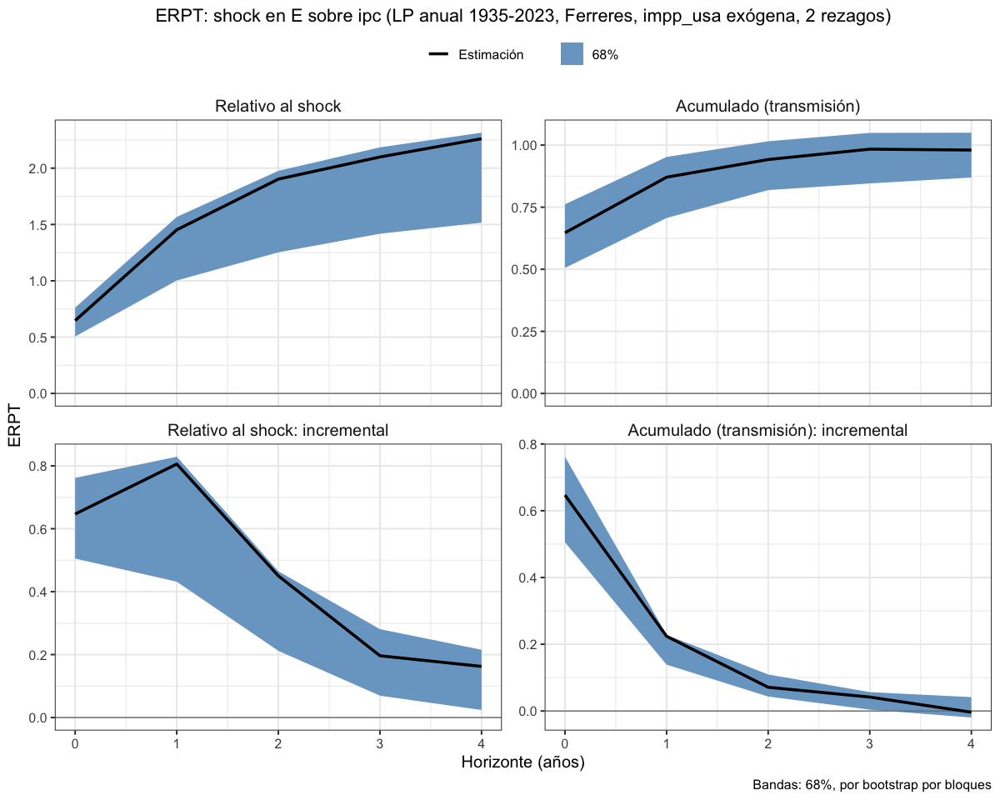

In [22]:
# Anual 1935–2023, Ferreres. impp_usa exógena y el resto endógenas, 2 rezagos
lp_erpt_anual_ferr_exog_p2 <- erpt_lp(df_ERPT_Arg_1935_2023, endog = c("E", "ipc", "PBIpm"), exog = c("impp_usa"),
                                       fixed_lags = 2, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_ferr_exog_p2, "lp_erpt_anual_ferr_exog_p2.rds")
titulo_ferr_exog_p2 <- "ERPT: shock en E sobre ipc (LP anual 1935-2023, Ferreres, impp_usa exógena, 2 rezagos)"
graficar_erpt_lp(lp_erpt_anual_ferr_exog_p2, titulo = titulo_ferr_exog_p2,
                 archivo = "lp_erpt_anual_ferr_exog_p2")
graficar_erpt_lp(lp_erpt_anual_ferr_exog_p2, titulo = titulo_ferr_exog_p2, niveles = 0.68,
                 archivo = "lp_erpt_anual_ferr_exog_p2_68")

### 1935-1974. Todas endógenas - Selected orders: 0 y 1 lag (0 lag no tiene sentido en modelos autorregresivos)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"impp_usa, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,0.133053076,0.1330531,0.1330531
2,impp_usa,E,1,0.157459951,-0.2618448,0.5767647
3,impp_usa,E,2,0.132441186,-0.5279313,0.7928136
4,impp_usa,E,3,0.170997062,-0.4775198,0.8195139
5,impp_usa,E,4,0.005196668,-0.4034844,0.4138777


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.00000000
37,ipc,E,1,-0.05616471,-0.2159243,0.10359488
38,ipc,E,2,-0.07527632,-0.1870308,0.03647818
39,ipc,E,3,0.32819497,0.2382498,0.41814011
40,ipc,E,4,0.33528310,0.2209823,0.44958387


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.000000,0.0000000,0.000000
52,PBIpm,E,1,1.650044,1.1692756,2.130813
53,PBIpm,E,2,1.502354,0.5404857,2.464222
54,PBIpm,E,3,1.099887,0.3348966,1.864878
55,PBIpm,E,4,1.009668,0.1896315,1.829705


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
56,PBIpm,ipc,0,0.0000000,0.0000000,0.000000
57,PBIpm,ipc,1,1.3714788,0.8066856,1.936272
58,PBIpm,ipc,2,1.4602520,1.0257217,1.894782
59,PBIpm,ipc,3,0.7818732,0.2759420,1.287804
60,PBIpm,ipc,4,1.1221730,0.3204060,1.923940


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,E,PBIpm,0,-0.02020180,-0.02020180,-0.020201796
27,E,PBIpm,1,-0.07591193,-0.10436037,-0.047463483
28,E,PBIpm,2,0.02220383,-0.03046736,0.074875022
29,E,PBIpm,3,-0.03820908,-0.09750824,0.021090081
30,E,PBIpm,4,-0.05100865,-0.10470767,0.002690363


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,impp_usa,PBIpm,0,0.13210159,0.13210159,0.13210159
12,impp_usa,PBIpm,1,-0.06659177,-0.20515325,0.07196971
13,impp_usa,PBIpm,2,-0.05876082,-0.15783424,0.04031261
14,impp_usa,PBIpm,3,-0.08606086,-0.19321206,0.02109033
15,impp_usa,PBIpm,4,0.09318828,-0.03860701,0.22498356


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
41,ipc,PBIpm,0,-0.15680917,-0.15680917,-0.156809174
42,ipc,PBIpm,1,0.08901578,0.09219675,0.085834808
43,ipc,PBIpm,2,0.03891907,0.02100824,0.056829901
44,ipc,PBIpm,3,-0.02753993,-0.07972669,0.024646822
45,ipc,PBIpm,4,-0.01096216,-0.02383343,0.001909105


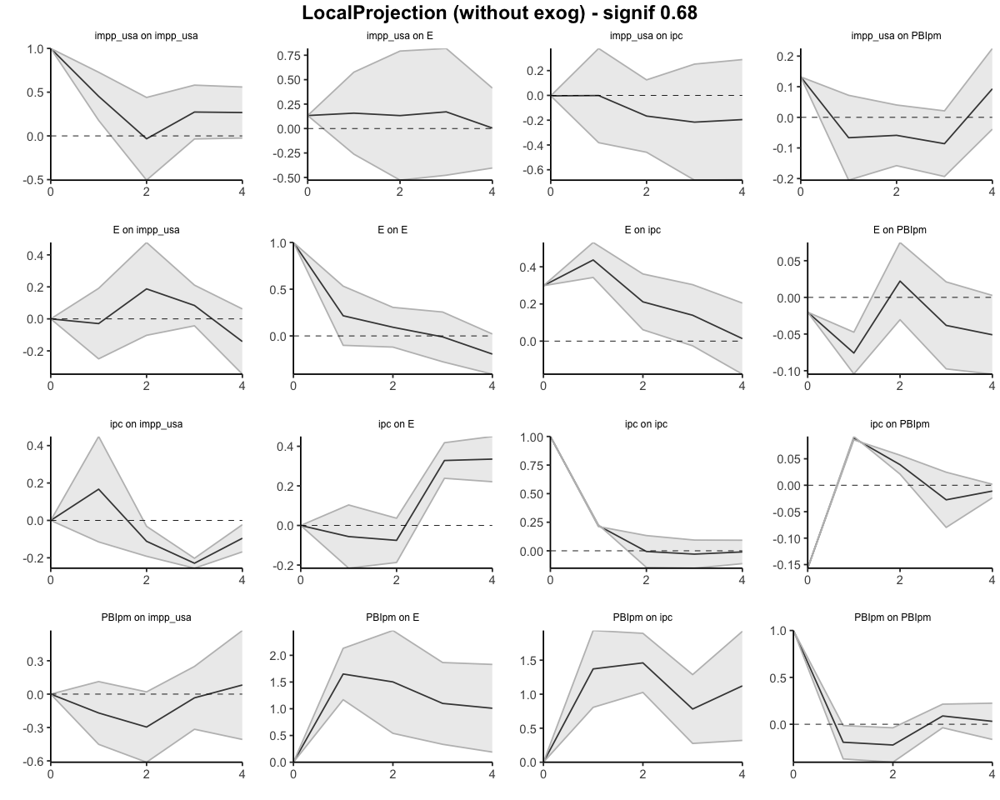

In [23]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("impp_usa", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"impp_usa, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,0.1330531,0.1330531,0.1330531
2,impp_usa,E,1,0.2905130,-0.1287918,0.7098178
3,impp_usa,E,2,0.4229542,-0.6567230,1.5026315
4,impp_usa,E,3,0.5939513,-1.1342428,2.3221453
5,impp_usa,E,4,0.5991479,-1.5377272,2.7360230


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.00000000,0.0000000
37,ipc,E,1,-0.05616471,-0.21592430,0.1035949
38,ipc,E,2,-0.13144103,-0.40295512,0.1400731
39,ipc,E,3,0.19675393,-0.16470530,0.5582132
40,ipc,E,4,0.53203703,0.05627703,1.0077970


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.000000,0.000000,0.000000
52,PBIpm,E,1,1.650044,1.169276,2.130813
53,PBIpm,E,2,3.152398,1.709761,4.595035
54,PBIpm,E,3,4.252285,2.044658,6.459913
55,PBIpm,E,4,5.261953,2.234289,8.289617


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
56,PBIpm,ipc,0,0.000000,0.0000000,0.000000
57,PBIpm,ipc,1,1.371479,0.8066856,1.936272
58,PBIpm,ipc,2,2.831731,1.8324072,3.831054
59,PBIpm,ipc,3,3.613604,2.1083492,5.118859
60,PBIpm,ipc,4,4.735777,2.4287552,7.042799


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,E,PBIpm,0,-0.02020180,-0.0202018,-0.020201796
27,E,PBIpm,1,-0.09611372,-0.1245622,-0.067665280
28,E,PBIpm,2,-0.07390989,-0.1550295,0.007209742
29,E,PBIpm,3,-0.11211897,-0.2525378,0.028299823
30,E,PBIpm,4,-0.16312762,-0.3572454,0.030990186


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,impp_usa,PBIpm,0,0.132101590,0.13210159,0.1321016
12,impp_usa,PBIpm,1,0.065509823,-0.07305166,0.2040713
13,impp_usa,PBIpm,2,0.006749008,-0.23088590,0.2443839
14,impp_usa,PBIpm,3,-0.079311856,-0.42409795,0.2654742
15,impp_usa,PBIpm,4,0.013876419,-0.46270496,0.4904578


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
41,ipc,PBIpm,0,-0.15680917,-0.15680917,-0.15680917
42,ipc,PBIpm,1,-0.06779339,-0.06461242,-0.07097437
43,ipc,PBIpm,2,-0.02887432,-0.04360418,-0.01414447
44,ipc,PBIpm,3,-0.05641425,-0.12333086,0.01050236
45,ipc,PBIpm,4,-0.06737642,-0.14716430,0.01241146


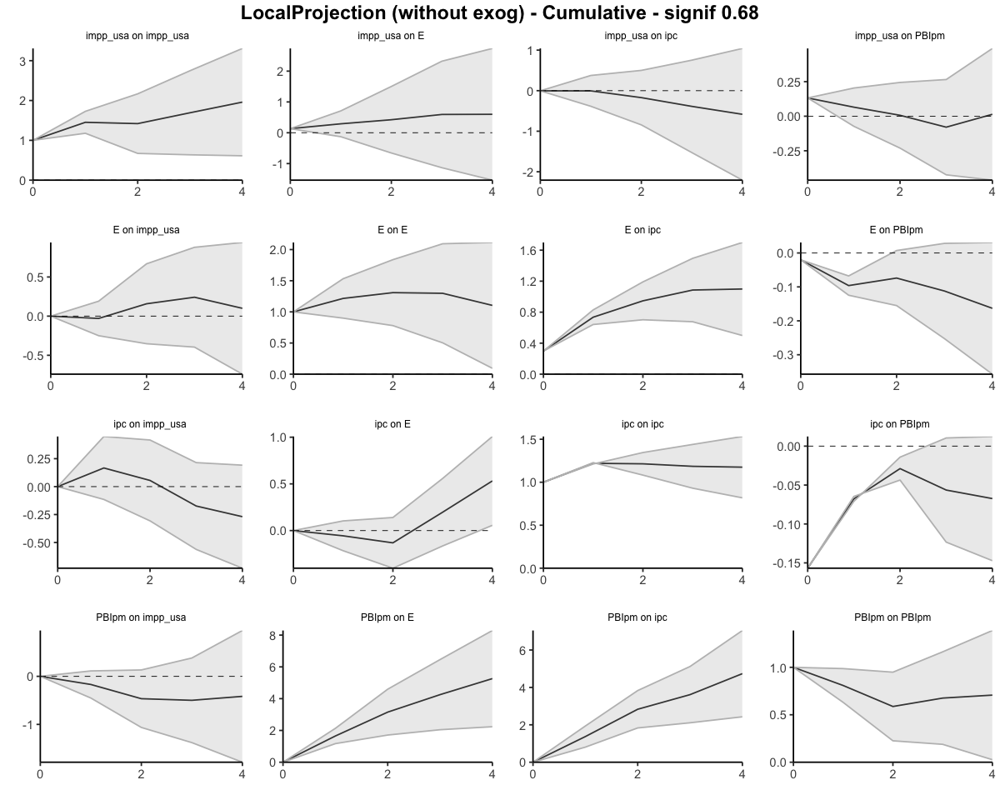

In [24]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("impp_usa", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

#### Todas endógenas - 1 lag

Bootstrap por bloques circular: 500 réplicas, bloques de 10 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.2983         0.2983       1.0000
         1              0.7350         0.6045       1.2158
         2              0.9463         0.7231       1.3087
         3              1.0856         0.8362       1.2983
         4              1.0990         0.9955       1.1040
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.2983             0.2983
                  0.4367             0.3063
                  0.2113             0.1186
                  0.1392             0.1131
                  0.0135             0.1594


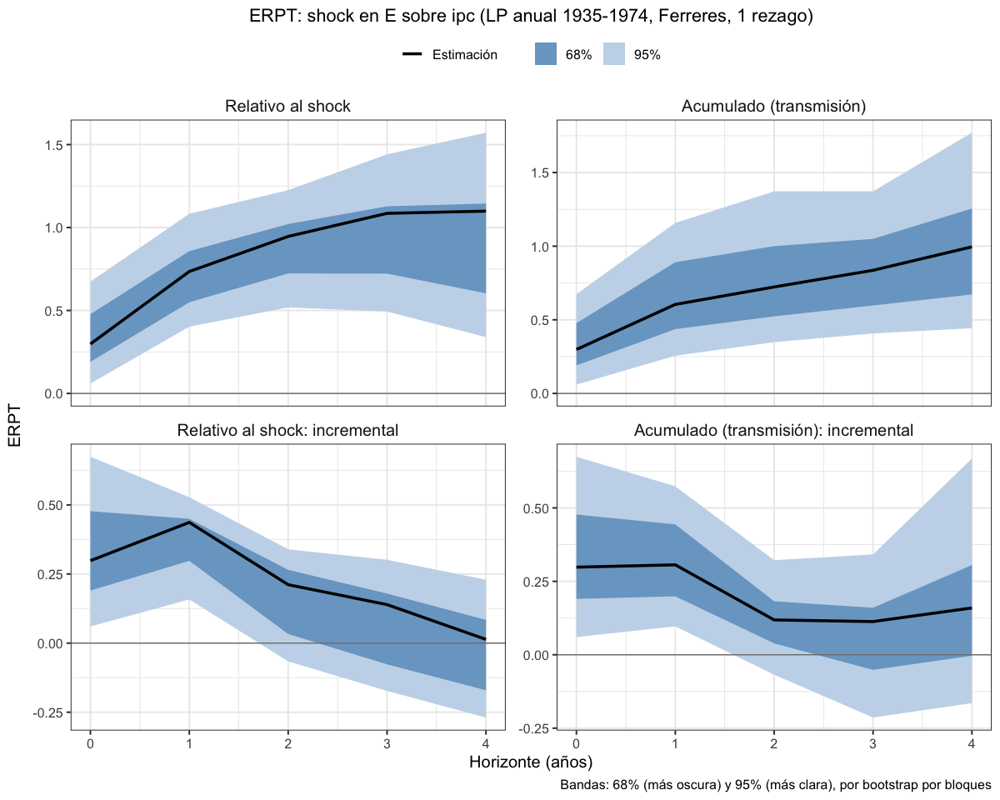

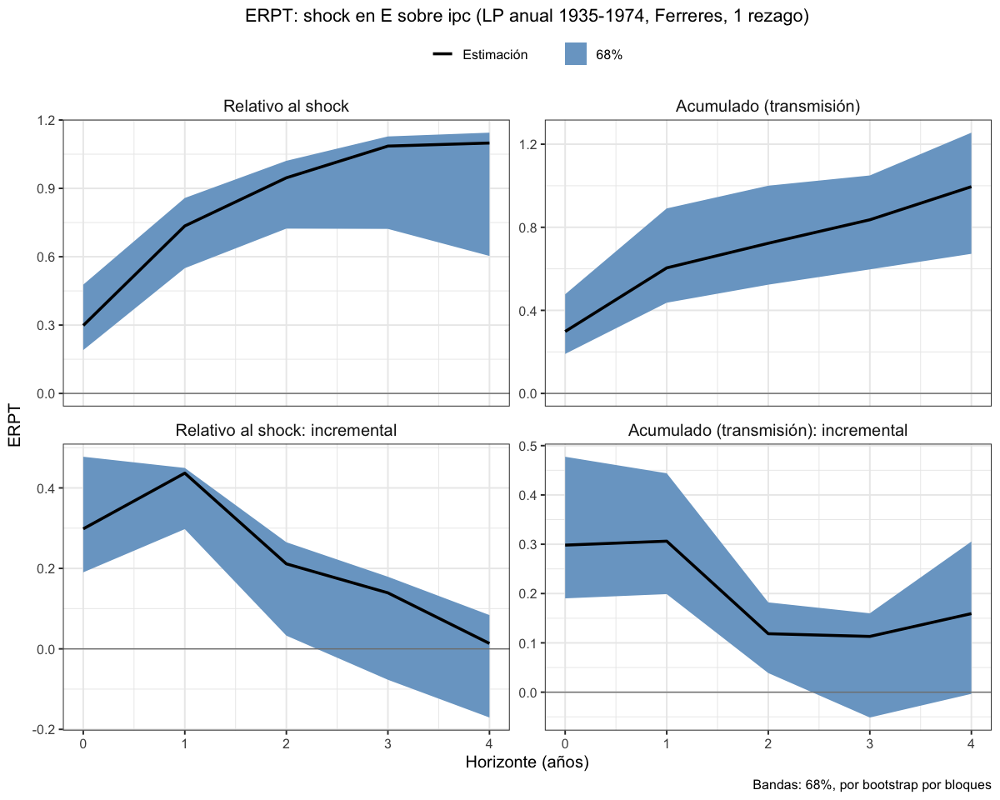

In [25]:
# Anual 1935–1974, Ferreres. Todas endógenas, 1 rezago
lp_erpt_anual_ferr_35_74_endog_p1 <- erpt_lp(df_ERPT_Arg_1935_1974, endog = c("impp_usa", "E", "ipc", "PBIpm"),
                                             fixed_lags = 1, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_ferr_35_74_endog_p1, "lp_erpt_anual_ferr_35_74_endog_p1.rds")
titulo_ferr_35_74 <- "ERPT: shock en E sobre ipc (LP anual 1935-1974, Ferreres, 1 rezago)"
graficar_erpt_lp(lp_erpt_anual_ferr_35_74_endog_p1, titulo = titulo_ferr_35_74,
                 archivo = "lp_erpt_anual_ferr_35_74_endog_p1")
graficar_erpt_lp(lp_erpt_anual_ferr_35_74_endog_p1, titulo = titulo_ferr_35_74, niveles = 0.68,
                 archivo = "lp_erpt_anual_ferr_35_74_endog_p1_68")

### 1935-1974. 1 exógena y el resto endógenas - Selected orders: 0 y 1 lag (0 lag no tiene sentido en modelos autorregresivos)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.00000000
12,ipc,E,1,-0.06305826,-0.2208093,0.09469278
13,ipc,E,2,-0.08155285,-0.1892889,0.02618316
14,ipc,E,3,0.32359986,0.2368507,0.41034903
15,ipc,E,4,0.33106491,0.2201901,0.44193974


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.000000,0.0000000,0.000000
22,PBIpm,E,1,1.650044,1.1692756,2.130813
23,PBIpm,E,2,1.502354,0.5404857,2.464222
24,PBIpm,E,3,1.099887,0.3348966,1.864878
25,PBIpm,E,4,1.009668,0.1896315,1.829705


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.29702454,0.29702454,0.2970245
2,E,ipc,1,0.44145513,0.34515375,0.5377565
3,E,ipc,2,0.21666047,0.06515291,0.3681680
4,E,ipc,3,0.14212435,-0.02415833,0.3084070
5,E,ipc,4,0.01755552,-0.17661595,0.2117270


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.3714788,0.8066856,1.936272
28,PBIpm,ipc,2,1.4602520,1.0257217,1.894782
29,PBIpm,ipc,3,0.7818732,0.2759420,1.287804
30,PBIpm,ipc,4,1.1221730,0.3204060,1.923940


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.01637071,-0.01637071,-0.016370710
7,E,PBIpm,1,-0.07671844,-0.10581858,-0.047618291
8,E,PBIpm,2,0.02135111,-0.03196567,0.074667887
9,E,PBIpm,3,-0.03785302,-0.09754523,0.021839198
10,E,PBIpm,4,-0.05088103,-0.10526834,0.003506281


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.16098697,-0.16098697,-0.1609869687
17,ipc,PBIpm,1,0.08981613,0.09374098,0.0858912809
18,ipc,PBIpm,2,0.03984329,0.02269913,0.0569874522
19,ipc,PBIpm,3,-0.02790989,-0.07957153,0.0237517496
20,ipc,PBIpm,4,-0.01109323,-0.02315591,0.0009694541


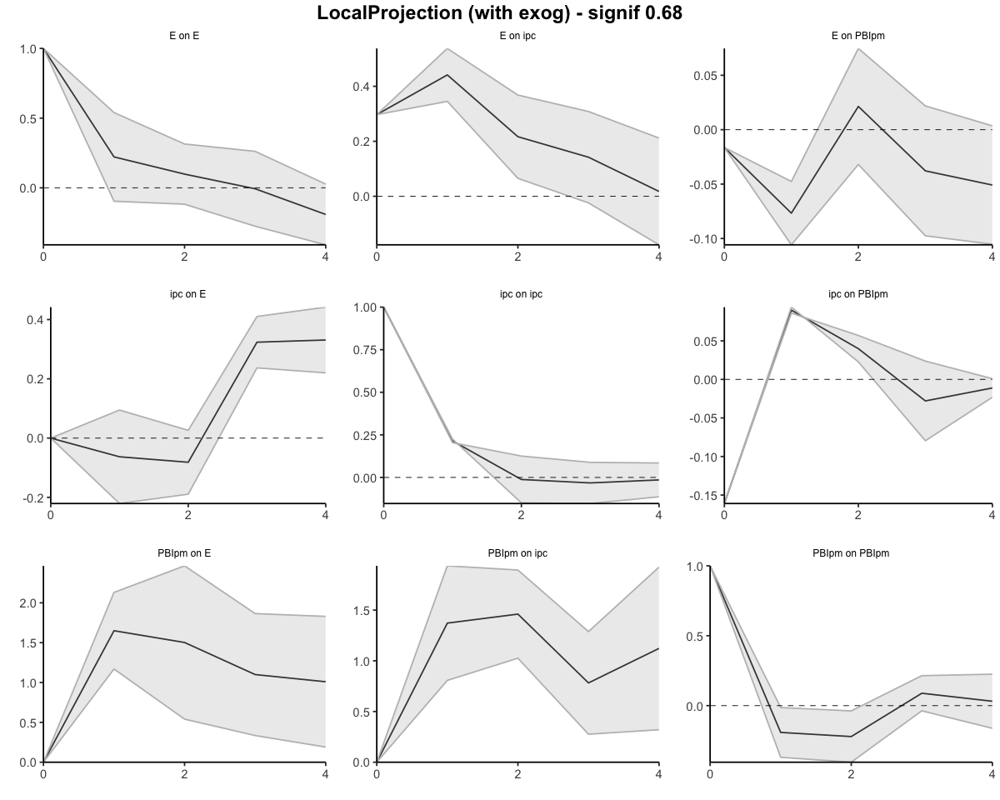

In [28]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("E", "ipc", "PBIpm"), exog=c("impp_usa"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,39,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.00000000,0.00000000
12,ipc,E,1,-0.06305826,-0.22080930,0.09469278
13,ipc,E,2,-0.14461110,-0.41009815,0.12087595
14,ipc,E,3,0.17898876,-0.17324746,0.53122498
15,ipc,E,4,0.51005367,0.04694262,0.97316472


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.000000,0.000000,0.000000
22,PBIpm,E,1,1.650044,1.169276,2.130813
23,PBIpm,E,2,3.152398,1.709761,4.595035
24,PBIpm,E,3,4.252285,2.044658,6.459913
25,PBIpm,E,4,5.261953,2.234289,8.289617


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.2970245,0.2970245,0.2970245
2,E,ipc,1,0.7384797,0.6421783,0.8347811
3,E,ipc,2,0.9551401,0.7073312,1.2029491
4,E,ipc,3,1.0972645,0.6831729,1.5113561
5,E,ipc,4,1.1148200,0.5065569,1.7230831


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.371479,0.8066856,1.936272
28,PBIpm,ipc,2,2.831731,1.8324072,3.831054
29,PBIpm,ipc,3,3.613604,2.1083492,5.118859
30,PBIpm,ipc,4,4.735777,2.4287552,7.042799


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.01637071,-0.01637071,-0.01637071
7,E,PBIpm,1,-0.09308915,-0.12218929,-0.06398900
8,E,PBIpm,2,-0.07173804,-0.15415496,0.01067889
9,E,PBIpm,3,-0.10959105,-0.25170019,0.03251808
10,E,PBIpm,4,-0.16047209,-0.35696854,0.03602437


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.16098697,-0.16098697,-0.160986969
17,ipc,PBIpm,1,-0.07117084,-0.06724599,-0.075095688
18,ipc,PBIpm,2,-0.03132755,-0.04454686,-0.018108236
19,ipc,PBIpm,3,-0.05923744,-0.12411839,0.005643514
20,ipc,PBIpm,4,-0.07033067,-0.14727430,0.006612968


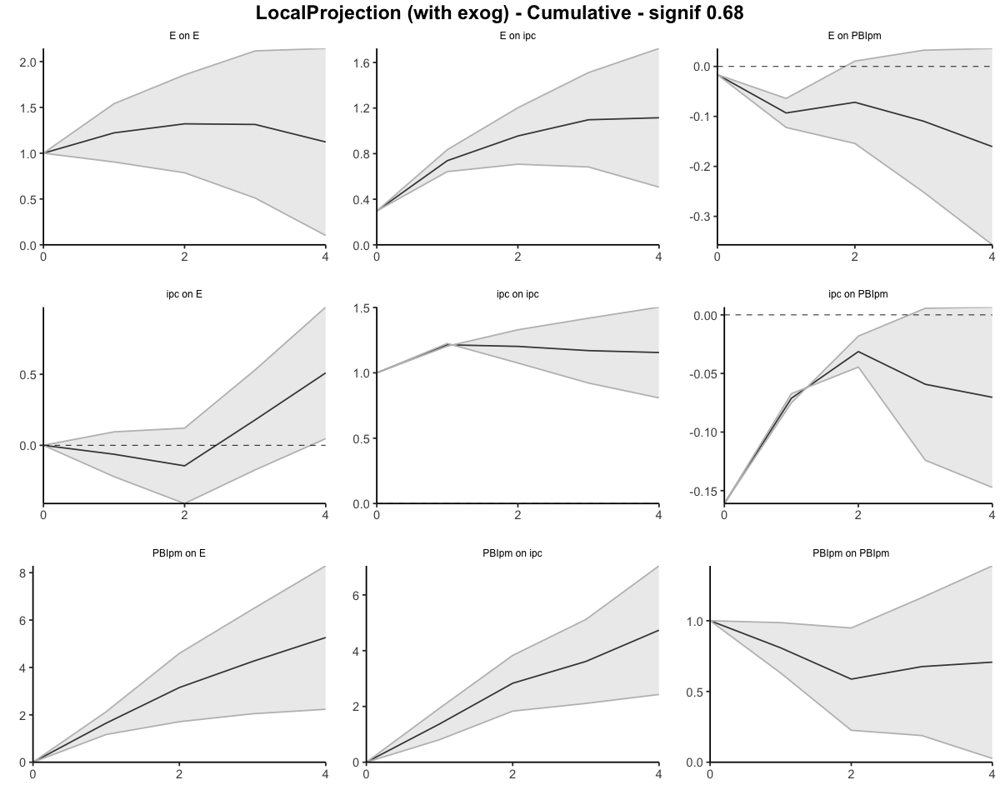

In [27]:
res <- run_lp_model(df_ERPT_Arg_1935_1974, endog=c("E", "ipc", "PBIpm"), exog=c("impp_usa"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

#### impp_usa exógena y el resto endógenas - 1 lag

Bootstrap por bloques circular: 500 réplicas, bloques de 10 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos, exógenas: impp_usa )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.2970         0.2970       1.0000
         1              0.7385         0.6044       1.2219
         2              0.9551         0.7234       1.3204
         3              1.0973         0.8354       1.3135
         4              1.1148         0.9932       1.1225
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.2970             0.2970
                  0.4415             0.3073
                  0.2167             0.1190
                  0.1421             0.1120
                  0.0176             0.1578


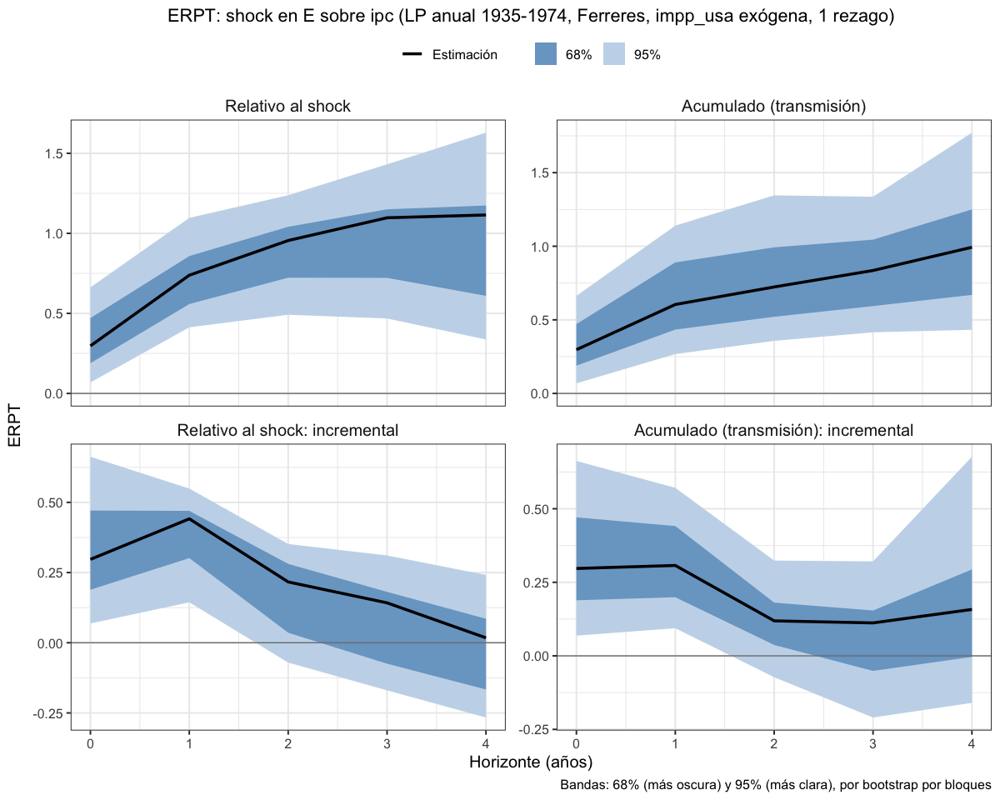

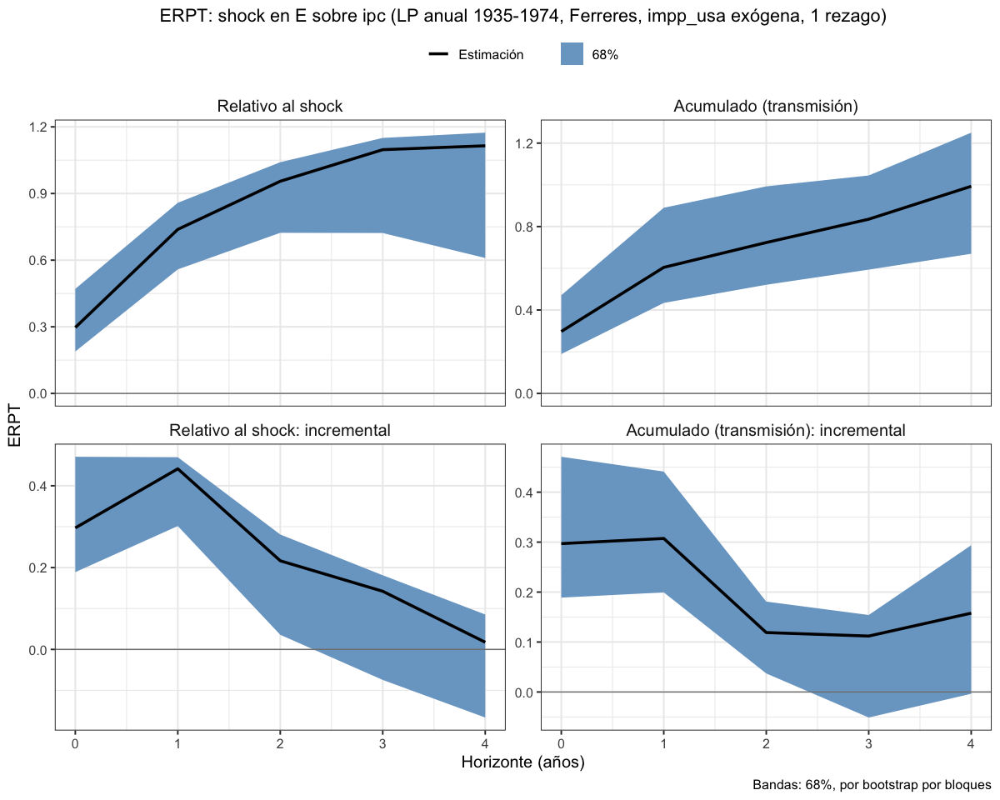

In [26]:
# Anual 1935–1974, Ferreres. impp_usa exógena y el resto endógenas, 1 rezago
lp_erpt_anual_ferr_35_74_exog_p1 <- erpt_lp(df_ERPT_Arg_1935_1974, endog = c("E", "ipc", "PBIpm"), exog = c("impp_usa"),
                                            fixed_lags = 1, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_ferr_35_74_exog_p1, "lp_erpt_anual_ferr_35_74_exog_p1.rds")
titulo_ferr_35_74_exog <- "ERPT: shock en E sobre ipc (LP anual 1935-1974, Ferreres, impp_usa exógena, 1 rezago)"
graficar_erpt_lp(lp_erpt_anual_ferr_35_74_exog_p1, titulo = titulo_ferr_35_74_exog,
                 archivo = "lp_erpt_anual_ferr_35_74_exog_p1")
graficar_erpt_lp(lp_erpt_anual_ferr_35_74_exog_p1, titulo = titulo_ferr_35_74_exog, niveles = 0.68,
                 archivo = "lp_erpt_anual_ferr_35_74_exog_p1_68")

### 1935-1975. Todas endógenas - Selected orders: 0 y 1 lag (0 lag no tiene sentido en modelos autorregresivos)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"impp_usa, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-0.2174645,-0.2174645,-0.2174645
2,impp_usa,E,1,1.5214396,0.6055038,2.4373754
3,impp_usa,E,2,0.8622601,-0.1855000,1.9100202
4,impp_usa,E,3,0.3492741,-0.5045147,1.2030629
5,impp_usa,E,4,0.1228694,-0.1348814,0.3806202


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.00000000,0.00000000
37,ipc,E,1,-0.09967065,-0.25413411,0.05479282
38,ipc,E,2,0.75649297,0.28431145,1.22867449
39,ipc,E,3,0.52561908,0.14595167,0.90528649
40,ipc,E,4,0.31864753,0.06138762,0.57590745


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.00000000,0.000000
52,PBIpm,E,1,0.9904187,0.20893330,1.771904
53,PBIpm,E,2,1.9812073,0.97434434,2.988070
54,PBIpm,E,3,1.2249689,0.21084777,2.239090
55,PBIpm,E,4,1.2443057,0.06795254,2.420659


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
56,PBIpm,ipc,0,0.0000000,0.0000000,0.000000
57,PBIpm,ipc,1,0.9660291,0.2729221,1.659136
58,PBIpm,ipc,2,1.7660185,0.9754600,2.556577
59,PBIpm,ipc,3,0.8559550,0.2254564,1.486454
60,PBIpm,ipc,4,1.2587604,0.1768588,2.340662


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,E,PBIpm,0,-0.008829876,-0.008829876,-0.008829876
27,E,PBIpm,1,-0.070833957,-0.106367066,-0.035300848
28,E,PBIpm,2,0.023790140,-0.031331852,0.078912132
29,E,PBIpm,3,-0.045384461,-0.112039046,0.021270124
30,E,PBIpm,4,-0.059467697,-0.117161714,-0.001773679


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,impp_usa,PBIpm,0,0.13049490,0.130494896,0.130494896
12,impp_usa,PBIpm,1,-0.05534885,-0.136140967,0.025443267
13,impp_usa,PBIpm,2,-0.08534344,-0.161285582,-0.009401302
14,impp_usa,PBIpm,3,-0.07514693,-0.155585311,0.005291447
15,impp_usa,PBIpm,4,0.10937974,0.002697345,0.216062144


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
41,ipc,PBIpm,0,-0.125057441,-0.125057441,-0.125057441
42,ipc,PBIpm,1,0.083624717,0.079504339,0.087745095
43,ipc,PBIpm,2,0.011853969,-0.004863952,0.028571890
44,ipc,PBIpm,3,-0.026901307,-0.078493990,0.024691377
45,ipc,PBIpm,4,-0.009064405,-0.026718135,0.008589325


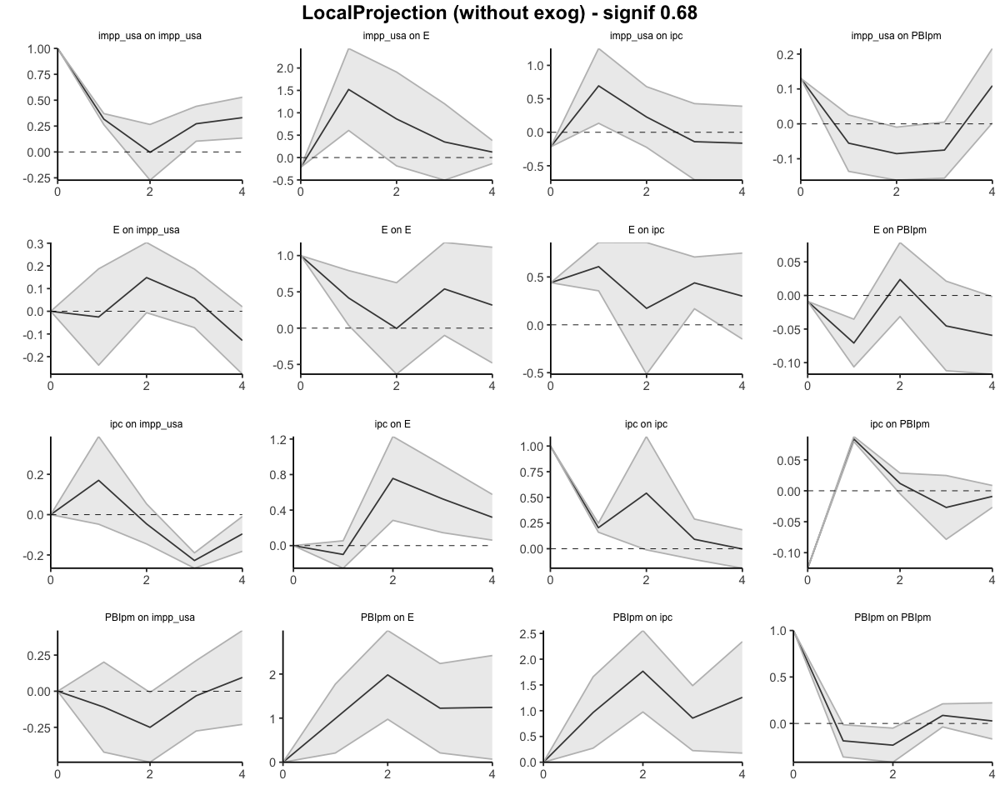

In [29]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("impp_usa", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"impp_usa, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-0.2174645,-0.2174645,-0.2174645
2,impp_usa,E,1,1.3039751,0.3880393,2.2199108
3,impp_usa,E,2,2.1662352,0.2025393,4.1299310
4,impp_usa,E,3,2.5155092,-0.3019754,5.3329938
5,impp_usa,E,4,2.6383786,-0.4368568,5.7136140


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.00000000,0.00000000
37,ipc,E,1,-0.09967065,-0.25413411,0.05479282
38,ipc,E,2,0.65682232,0.03017733,1.28346731
39,ipc,E,3,1.18244140,0.17612900,2.18875380
40,ipc,E,4,1.50108894,0.23751663,2.76466125


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.0000000,0.000000
52,PBIpm,E,1,0.9904187,0.2089333,1.771904
53,PBIpm,E,2,2.9716260,1.1832776,4.759974
54,PBIpm,E,3,4.1965949,1.3941254,6.999064
55,PBIpm,E,4,5.4409006,1.4620779,9.419723


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
56,PBIpm,ipc,0,0.0000000,0.0000000,0.000000
57,PBIpm,ipc,1,0.9660291,0.2729221,1.659136
58,PBIpm,ipc,2,2.7320476,1.2483821,4.215713
59,PBIpm,ipc,3,3.5880026,1.4738385,5.702167
60,PBIpm,ipc,4,4.8467629,1.6506973,8.042829


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,E,PBIpm,0,-0.008829876,-0.008829876,-0.008829876
27,E,PBIpm,1,-0.079663833,-0.115196942,-0.044130724
28,E,PBIpm,2,-0.055873693,-0.146528794,0.034781408
29,E,PBIpm,3,-0.101258154,-0.258567841,0.056051532
30,E,PBIpm,4,-0.160725851,-0.375729555,0.054277853


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,impp_usa,PBIpm,0,0.13049490,0.130494896,0.1304949
12,impp_usa,PBIpm,1,0.07514605,-0.005646071,0.1559382
13,impp_usa,PBIpm,2,-0.01019740,-0.166931653,0.1465369
14,impp_usa,PBIpm,3,-0.08534433,-0.322516964,0.1518283
15,impp_usa,PBIpm,4,0.02403542,-0.319819619,0.3678905


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
41,ipc,PBIpm,0,-0.12505744,-0.12505744,-0.125057441
42,ipc,PBIpm,1,-0.04143272,-0.04555310,-0.037312346
43,ipc,PBIpm,2,-0.02957875,-0.05041705,-0.008740455
44,ipc,PBIpm,3,-0.05648006,-0.12891104,0.015950921
45,ipc,PBIpm,4,-0.06554447,-0.15562918,0.024540246


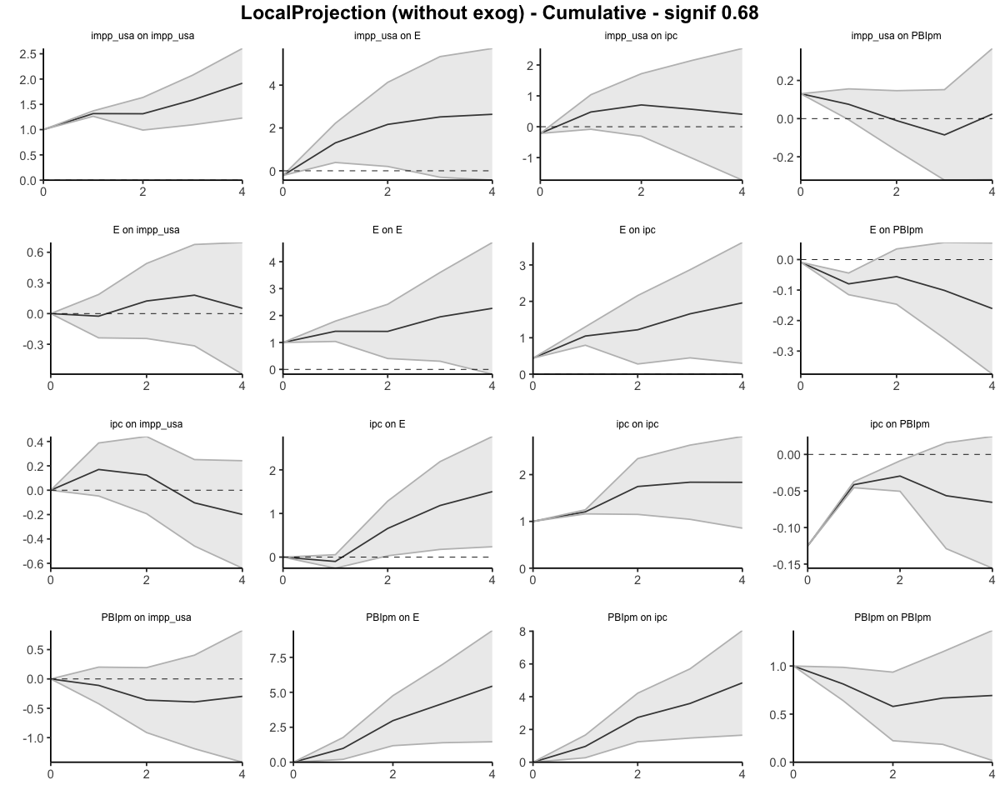

In [30]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("impp_usa", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

#### Todas endógenas - 1 lag

Bootstrap por bloques circular: 500 réplicas, bloques de 10 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4400         0.4400       1.0000
         1              1.0477         0.7400       1.4158
         2              1.2198         0.8642       1.4115
         3              1.6579         0.8494       1.9517
         4              1.9578         0.8630       2.2687
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4400             0.4400
                  0.6078             0.3000
                  0.1720             0.1242
                  0.4381            -0.0147
                  0.3000             0.0136


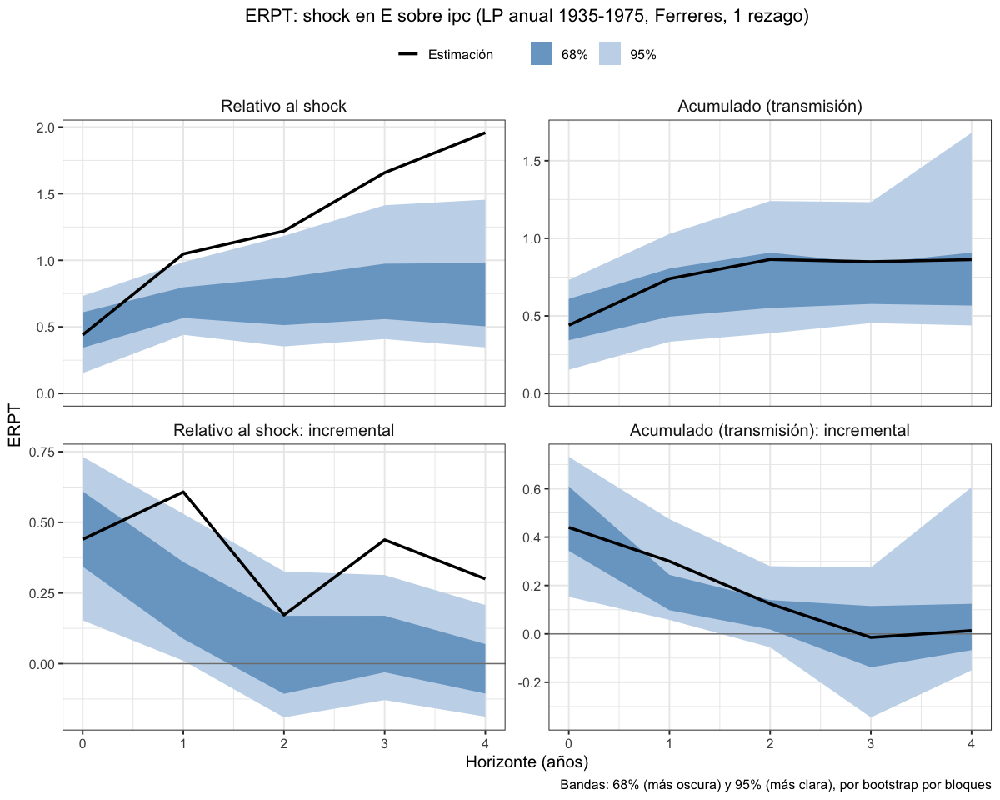

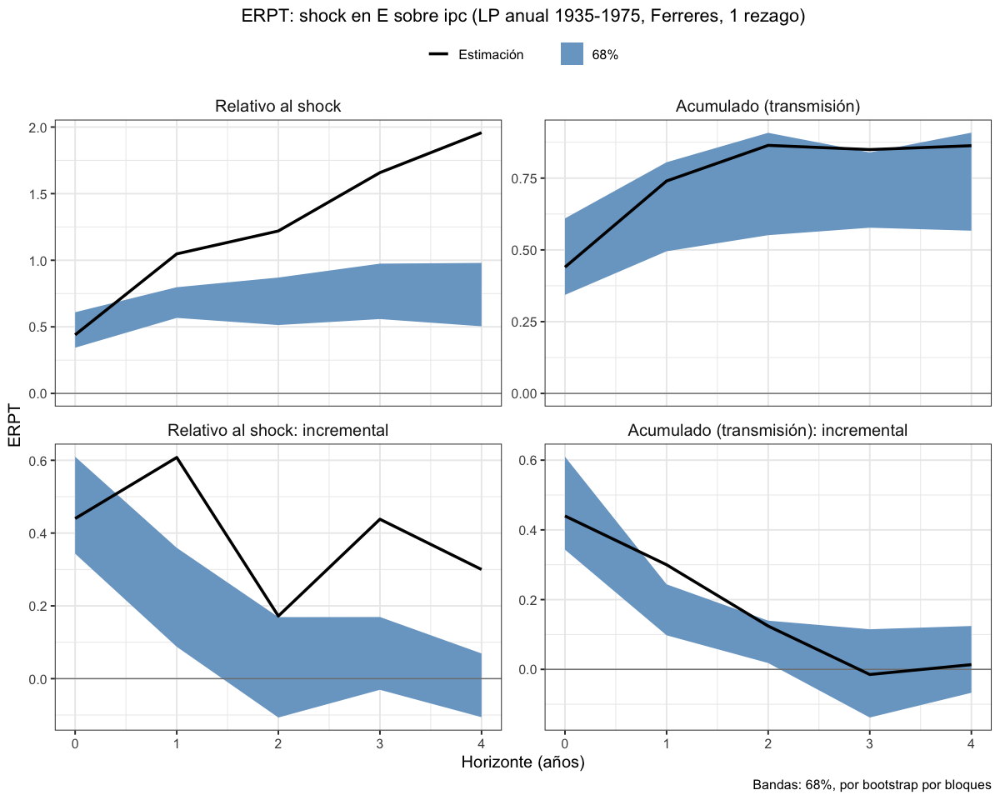

In [31]:
# Anual 1935–1975, Ferreres. Todas endógenas, 1 rezago
lp_erpt_anual_ferr_35_75_endog_p1 <- erpt_lp(df_ERPT_Arg_1935_1975, endog = c("impp_usa", "E", "ipc", "PBIpm"),
                                             fixed_lags = 1, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_ferr_35_75_endog_p1, "lp_erpt_anual_ferr_35_75_endog_p1.rds")
titulo_ferr_35_75 <- "ERPT: shock en E sobre ipc (LP anual 1935-1975, Ferreres, 1 rezago)"
graficar_erpt_lp(lp_erpt_anual_ferr_35_75_endog_p1, titulo = titulo_ferr_35_75,
                 archivo = "lp_erpt_anual_ferr_35_75_endog_p1")
graficar_erpt_lp(lp_erpt_anual_ferr_35_75_endog_p1, titulo = titulo_ferr_35_75, niveles = 0.68,
                 archivo = "lp_erpt_anual_ferr_35_75_endog_p1_68")

### 1935-1975. 1 exógena y el resto endógenas - Selected orders: 0 y 1 lag (0 lag no tiene sentido en modelos autorregresivos)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.00000000
12,ipc,E,1,-0.1087209,-0.25604331,0.03860147
13,ipc,E,2,0.7383890,0.27540806,1.20137003
14,ipc,E,3,0.5144255,0.14402498,0.88482608
15,ipc,E,4,0.3072773,0.06076668,0.55378789


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.00000000,0.000000
22,PBIpm,E,1,0.9904187,0.20893330,1.771904
23,PBIpm,E,2,1.9812073,0.97434434,2.988070
24,PBIpm,E,3,1.2249689,0.21084777,2.239090
25,PBIpm,E,4,1.2443057,0.06795254,2.420659


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4430817,0.4430817,0.4430817
2,E,ipc,1,0.6055656,0.3549525,0.8561788
3,E,ipc,2,0.1685483,-0.5182643,0.8553608
4,E,ipc,3,0.4358641,0.1668057,0.7049225
5,E,ipc,4,0.2962770,-0.1506995,0.7432535


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.000000
27,PBIpm,ipc,1,0.9660291,0.2729221,1.659136
28,PBIpm,ipc,2,1.7660185,0.9754600,2.556577
29,PBIpm,ipc,3,0.8559550,0.2254564,1.486454
30,PBIpm,ipc,4,1.2587604,0.1768588,2.340662


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.01215981,-0.01215981,-0.012159811
7,E,PBIpm,1,-0.07002344,-0.10506039,-0.034986494
8,E,PBIpm,2,0.02451332,-0.03012208,0.079148726
9,E,PBIpm,3,-0.04572391,-0.11217436,0.020726533
10,E,PBIpm,4,-0.05957547,-0.11675268,-0.002398254


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.134195264,-0.134195264,-0.134195264
17,ipc,PBIpm,1,0.085331799,0.082794189,0.087869409
18,ipc,PBIpm,2,0.013987297,-0.001055144,0.029029738
19,ipc,PBIpm,3,-0.027695213,-0.078151568,0.022761141
20,ipc,PBIpm,4,-0.009311368,-0.025186573,0.006563837


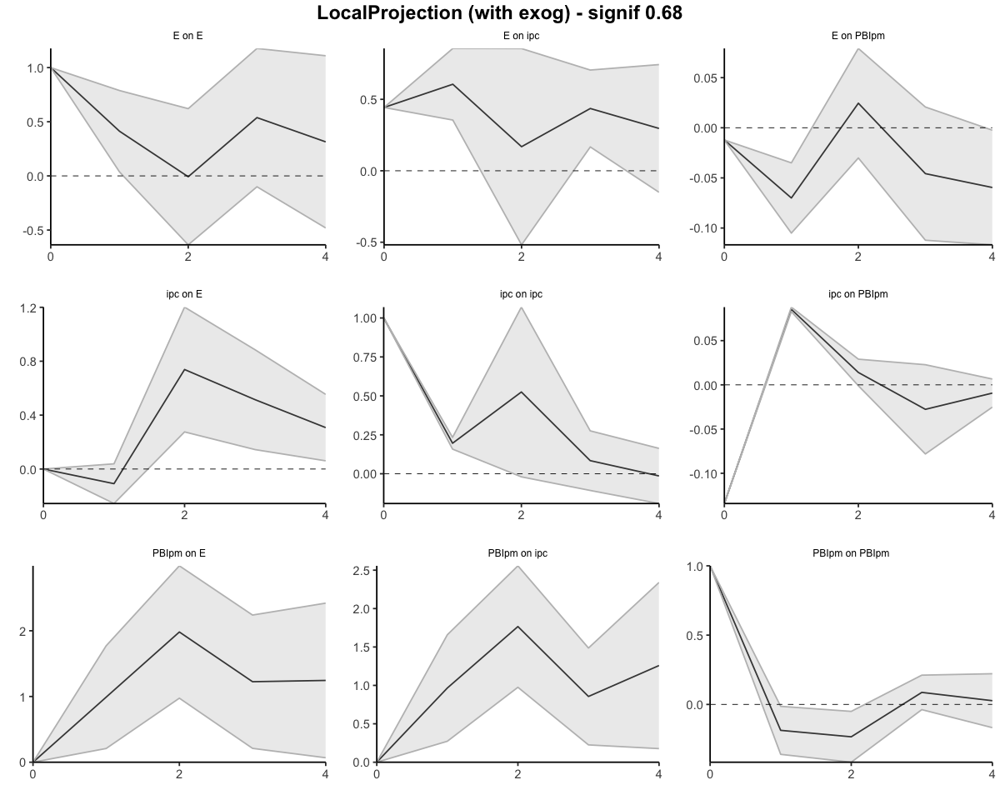

In [32]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("E", "ipc", "PBIpm"), exog=c("impp_usa"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,40,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.00000000
12,ipc,E,1,-0.1087209,-0.25604331,0.03860147
13,ipc,E,2,0.6296681,0.01936475,1.23997150
14,ipc,E,3,1.1440937,0.16338973,2.12479759
15,ipc,E,4,1.4513709,0.22415642,2.67858548


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.000000
22,PBIpm,E,1,0.9904187,0.2089333,1.771904
23,PBIpm,E,2,2.9716260,1.1832776,4.759974
24,PBIpm,E,3,4.1965949,1.3941254,6.999064
25,PBIpm,E,4,5.4409006,1.4620779,9.419723


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.4430817,0.4430817,0.4430817
2,E,ipc,1,1.0486473,0.7980341,1.2992605
3,E,ipc,2,1.2171956,0.2797698,2.1546213
4,E,ipc,3,1.6530597,0.4465756,2.8595438
5,E,ipc,4,1.9493367,0.2958761,3.6027973


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.000000
27,PBIpm,ipc,1,0.9660291,0.2729221,1.659136
28,PBIpm,ipc,2,2.7320476,1.2483821,4.215713
29,PBIpm,ipc,3,3.5880026,1.4738385,5.702167
30,PBIpm,ipc,4,4.8467629,1.6506973,8.042829


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.01215981,-0.01215981,-0.01215981
7,E,PBIpm,1,-0.08218325,-0.11722020,-0.04714630
8,E,PBIpm,2,-0.05766993,-0.14734228,0.03200242
9,E,PBIpm,3,-0.10339384,-0.25951664,0.05272896
10,E,PBIpm,4,-0.16296931,-0.37626932,0.05033070


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.13419526,-0.13419526,-0.134195264
17,ipc,PBIpm,1,-0.04886347,-0.05140108,-0.046325855
18,ipc,PBIpm,2,-0.03487617,-0.05245622,-0.017296117
19,ipc,PBIpm,3,-0.06257138,-0.13060779,0.005465024
20,ipc,PBIpm,4,-0.07188275,-0.15579436,0.012028861


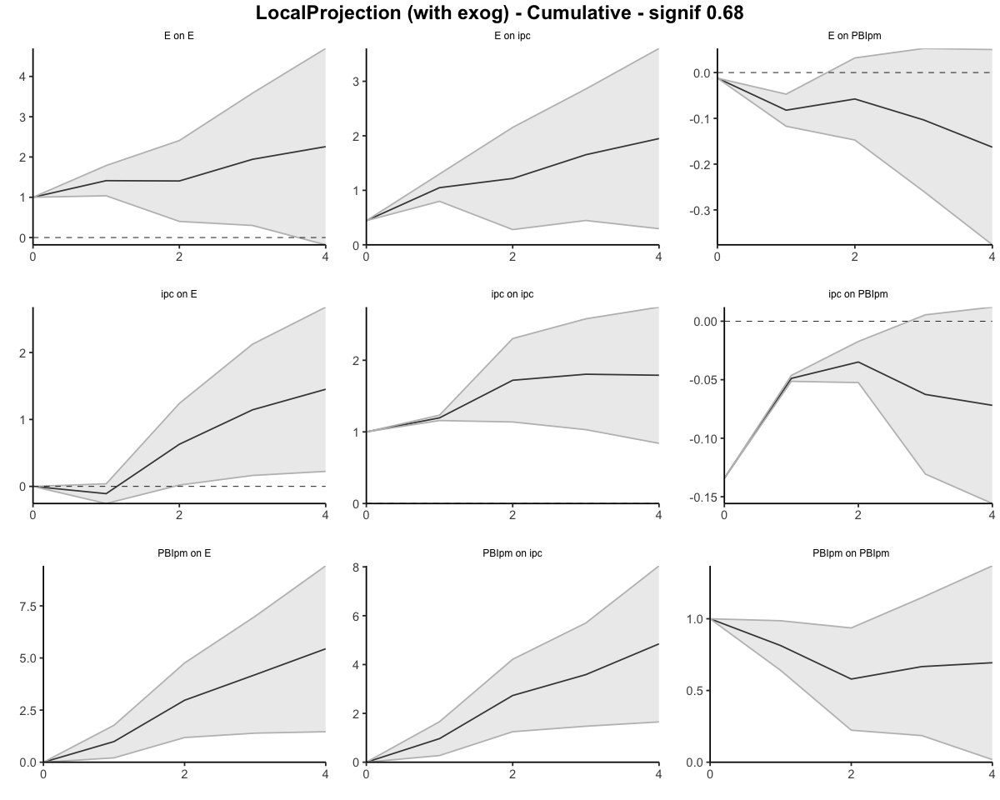

In [33]:
res <- run_lp_model(df_ERPT_Arg_1935_1975, endog=c("E", "ipc", "PBIpm"), exog=c("impp_usa"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

#### impp_usa exógena y el resto endógenas - 1 lag

Bootstrap por bloques circular: 500 réplicas, bloques de 10 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos, exógenas: impp_usa )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.4431         0.4431       1.0000
         1              1.0486         0.7423       1.4126
         2              1.2172         0.8664       1.4048
         3              1.6531         0.8507       1.9431
         4              1.9493         0.8635       2.2574
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.4431             0.4431
                  0.6056             0.2993
                  0.1685             0.1241
                  0.4359            -0.0157
                  0.2963             0.0128


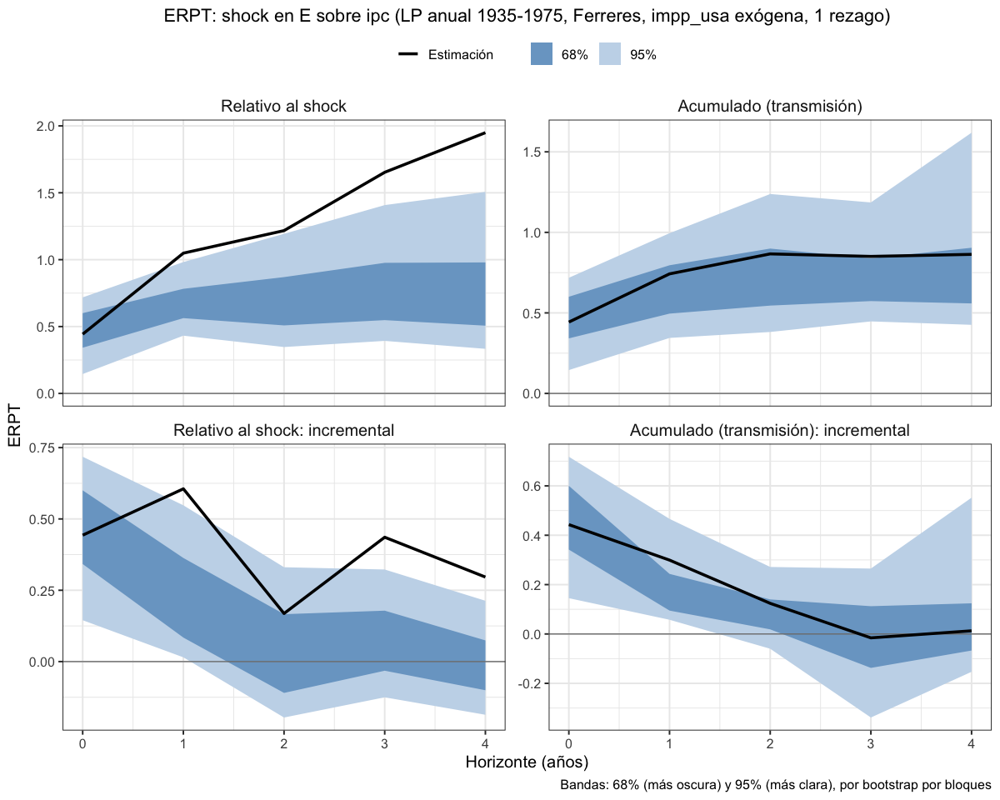

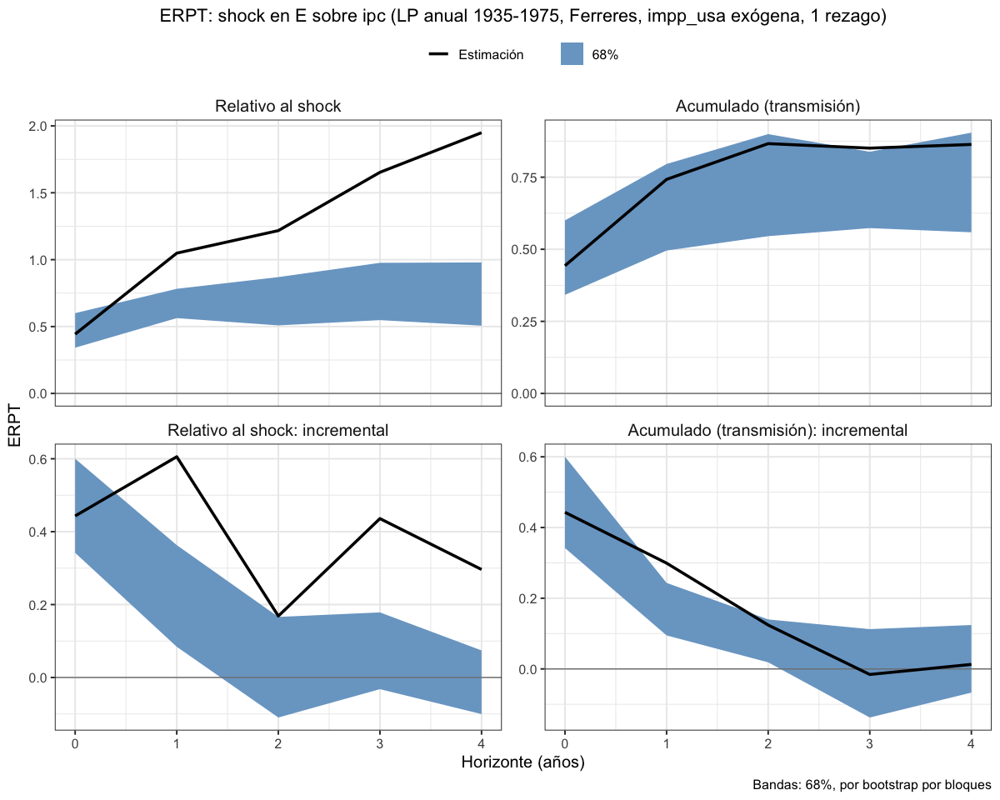

In [34]:
# Anual 1935–1975, Ferreres. impp_usa exógena y el resto endógenas, 1 rezago
lp_erpt_anual_ferr_35_75_exog_p1 <- erpt_lp(df_ERPT_Arg_1935_1975, endog = c("E", "ipc", "PBIpm"), exog = c("impp_usa"),
                                            fixed_lags = 1, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_ferr_35_75_exog_p1, "lp_erpt_anual_ferr_35_75_exog_p1.rds")
titulo_ferr_35_75_exog <- "ERPT: shock en E sobre ipc (LP anual 1935-1975, Ferreres, impp_usa exógena, 1 rezago)"
graficar_erpt_lp(lp_erpt_anual_ferr_35_75_exog_p1, titulo = titulo_ferr_35_75_exog,
                 archivo = "lp_erpt_anual_ferr_35_75_exog_p1")
graficar_erpt_lp(lp_erpt_anual_ferr_35_75_exog_p1, titulo = titulo_ferr_35_75_exog, niveles = 0.68,
                 archivo = "lp_erpt_anual_ferr_35_75_exog_p1_68")

### 1935-1982. Todas endógenas - Selected orders: 1 lag

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"impp_usa, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-0.6413533,-0.6413533,-0.6413533
2,impp_usa,E,1,1.3951357,0.6245586,2.1657127
3,impp_usa,E,2,2.5021363,1.4768186,3.5274541
4,impp_usa,E,3,1.2571806,0.7804711,1.7338900
5,impp_usa,E,4,0.8160963,0.5581625,1.0740300


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.00000000
37,ipc,E,1,-0.1555599,-0.2300432,-0.08107663
38,ipc,E,2,0.6483075,0.4239849,0.87263017
39,ipc,E,3,0.7005997,0.3787586,1.02244086
40,ipc,E,4,0.5796218,0.2736976,0.88554591


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.00000000,0.0000000
52,PBIpm,E,1,-0.2541406,-1.24905008,0.7407688
53,PBIpm,E,2,1.0623070,0.08117568,2.0434384
54,PBIpm,E,3,0.6607697,-0.49510437,1.8166437
55,PBIpm,E,4,0.4355465,-0.73583506,1.6069281


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
56,PBIpm,ipc,0,0.0000000,0.00000000,0.000000
57,PBIpm,ipc,1,0.8429776,0.12048695,1.565468
58,PBIpm,ipc,2,0.9320655,0.17466869,1.689462
59,PBIpm,ipc,3,0.5700561,-0.09485037,1.234962
60,PBIpm,ipc,4,0.6026109,-0.25437200,1.459594


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,E,PBIpm,0,-0.02647417,-0.026474173,-0.026474173
27,E,PBIpm,1,-0.05053161,-0.065799082,-0.035264142
28,E,PBIpm,2,0.02446872,-0.002872542,0.051809982
29,E,PBIpm,3,-0.02651685,-0.057562462,0.004528756
30,E,PBIpm,4,-0.01421084,-0.051935497,0.023513808


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,impp_usa,PBIpm,0,0.156927116,0.15692712,0.15692712
12,impp_usa,PBIpm,1,-0.089486126,-0.16894839,-0.01002387
13,impp_usa,PBIpm,2,-0.143782432,-0.19206207,-0.09550279
14,impp_usa,PBIpm,3,-0.032331532,-0.09085255,0.02618949
15,impp_usa,PBIpm,4,0.000688446,-0.07329972,0.07467661


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
41,ipc,PBIpm,0,-0.05320296,-0.05320296,-0.05320296
42,ipc,PBIpm,1,0.04451454,0.04130319,0.04772588
43,ipc,PBIpm,2,-0.04057695,-0.05802467,-0.02312923
44,ipc,PBIpm,3,-0.02007743,-0.05110748,0.01095263
45,ipc,PBIpm,4,-0.02960054,-0.04448571,-0.01471537


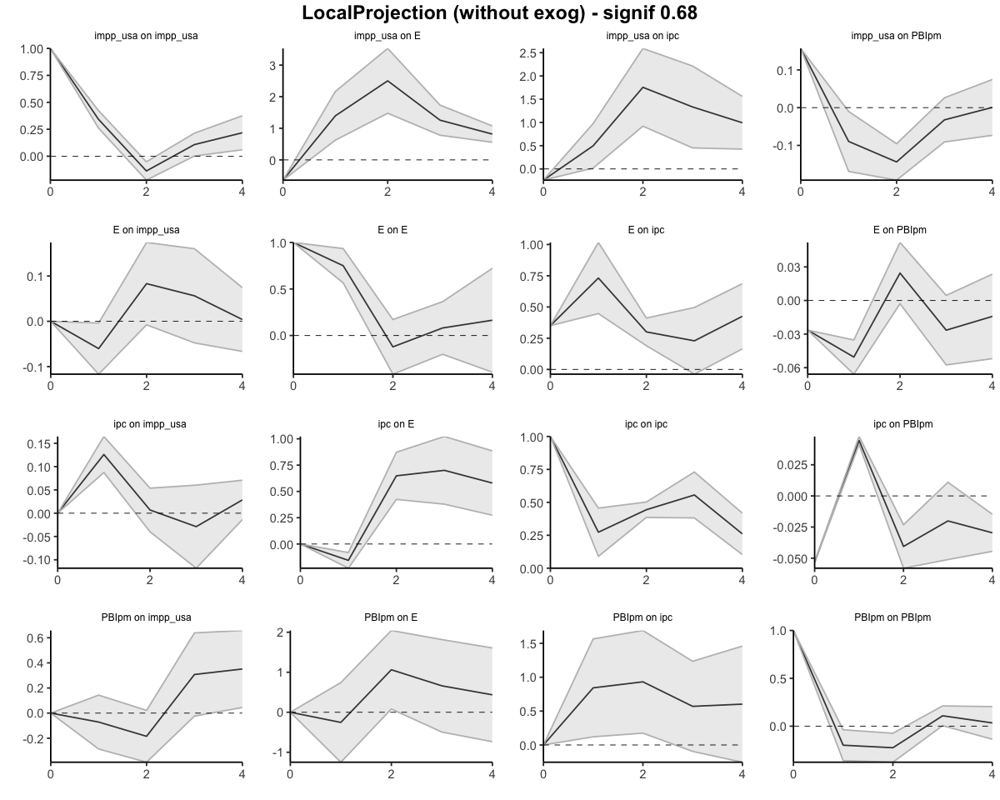

In [35]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("impp_usa", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"impp_usa, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-0.6413533,-0.64135328,-0.6413533
2,impp_usa,E,1,0.7537824,-0.01679466,1.5243594
3,impp_usa,E,2,3.2559187,1.46002396,5.0518135
4,impp_usa,E,3,4.5130993,2.24049506,6.7857035
5,impp_usa,E,4,5.3291956,2.79865757,7.8597336


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.0000000,0.00000000
37,ipc,E,1,-0.1555599,-0.2300432,-0.08107663
38,ipc,E,2,0.4927476,0.1939417,0.79155354
39,ipc,E,3,1.1933474,0.5727004,1.81399441
40,ipc,E,4,1.7729691,0.8463980,2.69954031


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.000000,0.0000000
52,PBIpm,E,1,-0.2541406,-1.249050,0.7407688
53,PBIpm,E,2,0.8081664,-1.167874,2.7842072
54,PBIpm,E,3,1.4689361,-1.662979,4.6008509
55,PBIpm,E,4,1.9044826,-2.398814,6.2077790


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
56,PBIpm,ipc,0,0.0000000,0.00000000,0.000000
57,PBIpm,ipc,1,0.8429776,0.12048695,1.565468
58,PBIpm,ipc,2,1.7750432,0.29515564,3.254931
59,PBIpm,ipc,3,2.3450992,0.20030527,4.489893
60,PBIpm,ipc,4,2.9477101,-0.05406673,5.949487


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,E,PBIpm,0,-0.02647417,-0.02647417,-0.026474173
27,E,PBIpm,1,-0.07700579,-0.09227326,-0.061738315
28,E,PBIpm,2,-0.05253707,-0.09514580,-0.009928333
29,E,PBIpm,3,-0.07905392,-0.15270826,-0.005399578
30,E,PBIpm,4,-0.09326476,-0.20464376,0.018114230


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,impp_usa,PBIpm,0,0.15692712,0.15692712,0.15692712
12,impp_usa,PBIpm,1,0.06744099,-0.01202127,0.14690325
13,impp_usa,PBIpm,2,-0.07634144,-0.20408334,0.05140046
14,impp_usa,PBIpm,3,-0.10867297,-0.29493590,0.07758995
15,impp_usa,PBIpm,4,-0.10798453,-0.36823562,0.15226656


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
41,ipc,PBIpm,0,-0.053202961,-0.05320296,-0.053202961
42,ipc,PBIpm,1,-0.008688425,-0.01189977,-0.005477082
43,ipc,PBIpm,2,-0.049265372,-0.06992443,-0.028606310
44,ipc,PBIpm,3,-0.069342798,-0.12103191,-0.017653685
45,ipc,PBIpm,4,-0.098943337,-0.16551762,-0.032369054


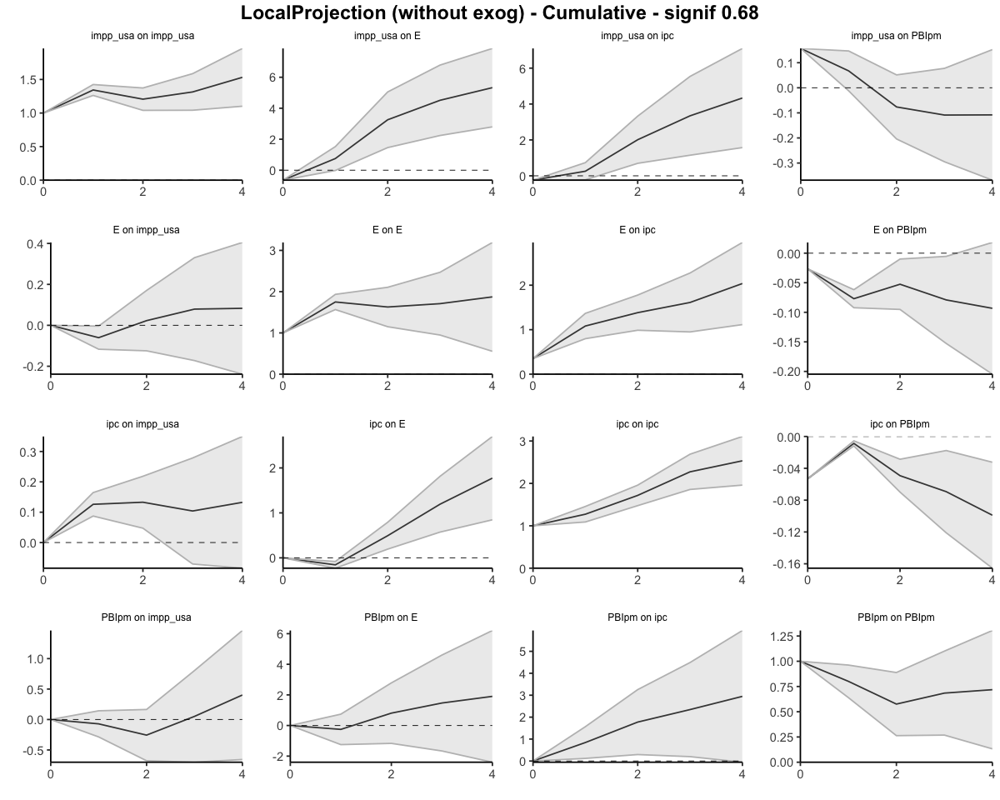

In [36]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("impp_usa", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

#### Todas endógenas - 1 lag

Bootstrap por bloques circular: 500 réplicas, bloques de 10 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.3505         0.3505       1.0000
         1              1.0824         0.6184       1.7501
         2              1.3829         0.8494       1.6281
         3              1.6119         0.9431       1.7092
         4              2.0374         1.0876       1.8734
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.3505             0.3505
                  0.7318             0.2679
                  0.3005             0.2309
                  0.2290             0.0937
                  0.4256             0.1445


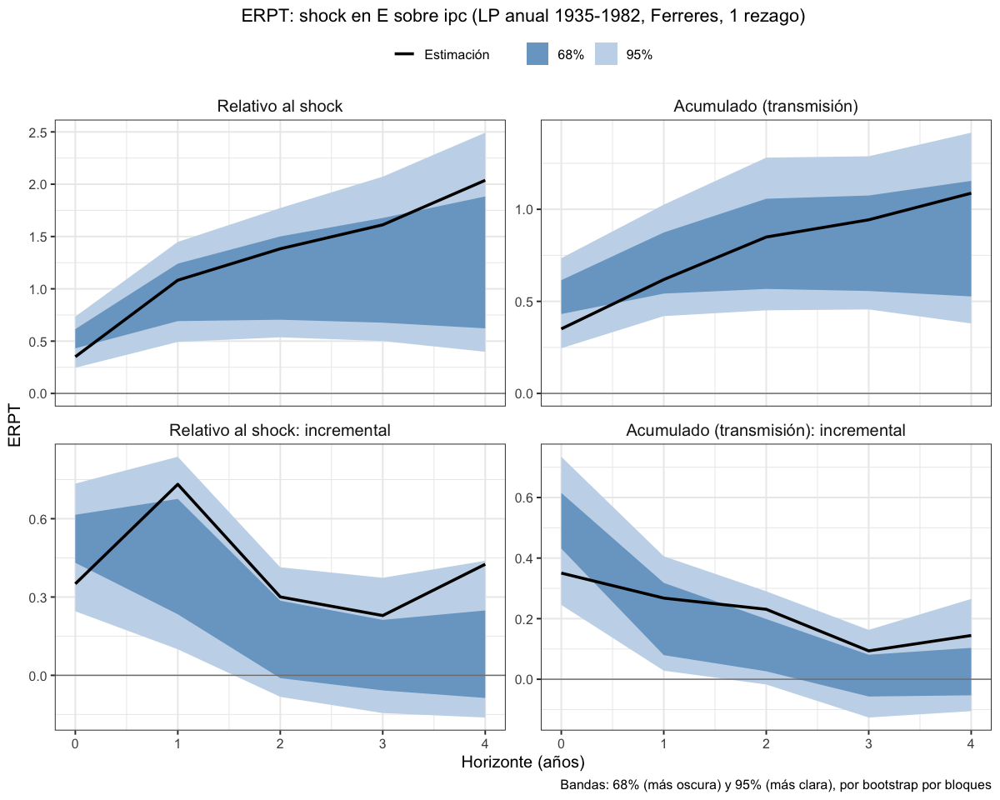

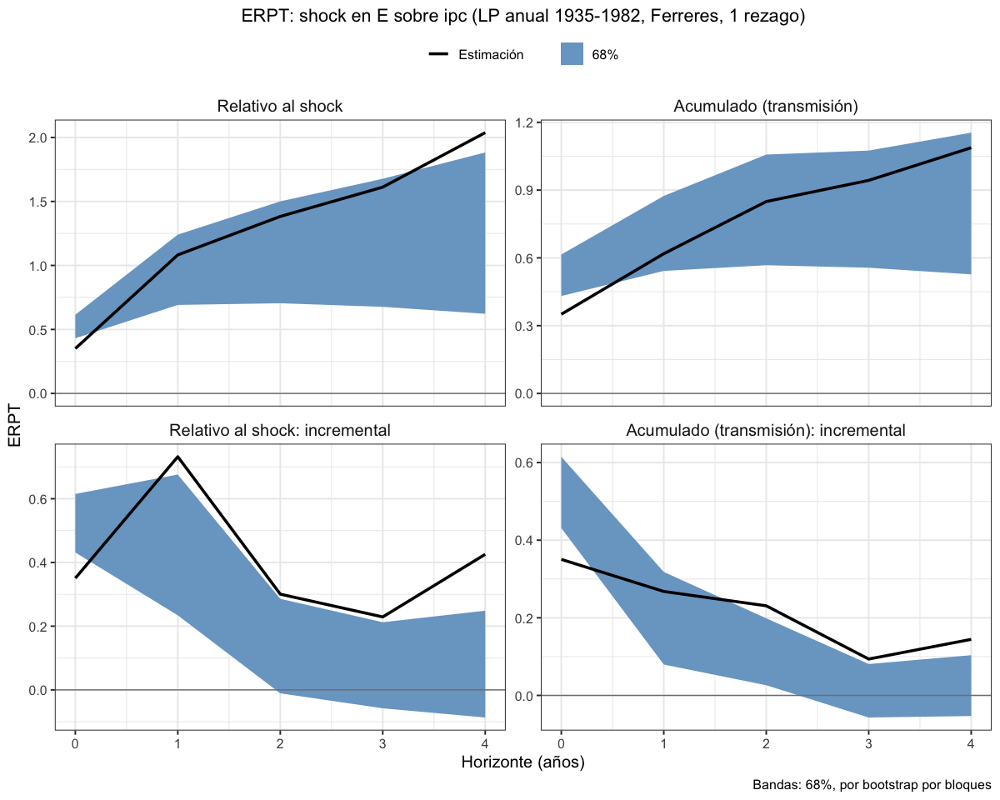

In [37]:
# Anual 1935–1982, Ferreres. Todas endógenas, 1 rezago
lp_erpt_anual_ferr_35_82_endog_p1 <- erpt_lp(df_ERPT_Arg_1935_1982, endog = c("impp_usa", "E", "ipc", "PBIpm"),
                                             fixed_lags = 1, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_ferr_35_82_endog_p1, "lp_erpt_anual_ferr_35_82_endog_p1.rds")
titulo_ferr_35_82 <- "ERPT: shock en E sobre ipc (LP anual 1935-1982, Ferreres, 1 rezago)"
graficar_erpt_lp(lp_erpt_anual_ferr_35_82_endog_p1, titulo = titulo_ferr_35_82,
                 archivo = "lp_erpt_anual_ferr_35_82_endog_p1")
graficar_erpt_lp(lp_erpt_anual_ferr_35_82_endog_p1, titulo = titulo_ferr_35_82, niveles = 0.68,
                 archivo = "lp_erpt_anual_ferr_35_82_endog_p1_68")

### 1935-1982. 1 exógena y el resto endógenas - Selected orders: 1 y 2 lags

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.00000000
12,ipc,E,1,-0.1553346,-0.2289361,-0.08173319
13,ipc,E,2,0.6473660,0.4239130,0.87081904
14,ipc,E,3,0.7000141,0.3791974,1.02083074
15,ipc,E,4,0.5792357,0.2743498,0.88412165


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.00000000,0.0000000
22,PBIpm,E,1,-0.2541406,-1.24905008,0.7407688
23,PBIpm,E,2,1.0623070,0.08117568,2.0434384
24,PBIpm,E,3,0.6607697,-0.49510437,1.8166437
25,PBIpm,E,4,0.4355465,-0.73583506,1.6069281


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.3514105,0.35141047,0.3514105
2,E,ipc,1,0.7260755,0.44640157,1.0057495
3,E,ipc,2,0.2942899,0.18893425,0.3996455
4,E,ipc,3,0.2254526,-0.03688205,0.4877873
5,E,ipc,4,0.4215208,0.16650507,0.6765366


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.00000000,0.000000
27,PBIpm,ipc,1,0.8429776,0.12048695,1.565468
28,PBIpm,ipc,2,0.9320655,0.17466869,1.689462
29,PBIpm,ipc,3,0.5700561,-0.09485037,1.234962
30,PBIpm,ipc,4,0.6026109,-0.25437200,1.459594


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.03360117,-0.0336011705,-0.03360117
7,E,PBIpm,1,-0.04908520,-0.0632135204,-0.03495689
8,E,PBIpm,2,0.02602942,-0.0002549258,0.05231377
9,E,PBIpm,3,-0.02730393,-0.0576457360,0.00303788
10,E,PBIpm,4,-0.01447661,-0.0510075134,0.02205429


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.05408928,-0.05408928,-0.05408928
17,ipc,PBIpm,1,0.04469077,0.04162236,0.04775918
18,ipc,PBIpm,2,-0.04037722,-0.05769076,-0.02306367
19,ipc,PBIpm,3,-0.02017377,-0.05111238,0.01076483
20,ipc,PBIpm,4,-0.02963061,-0.04436475,-0.01489646


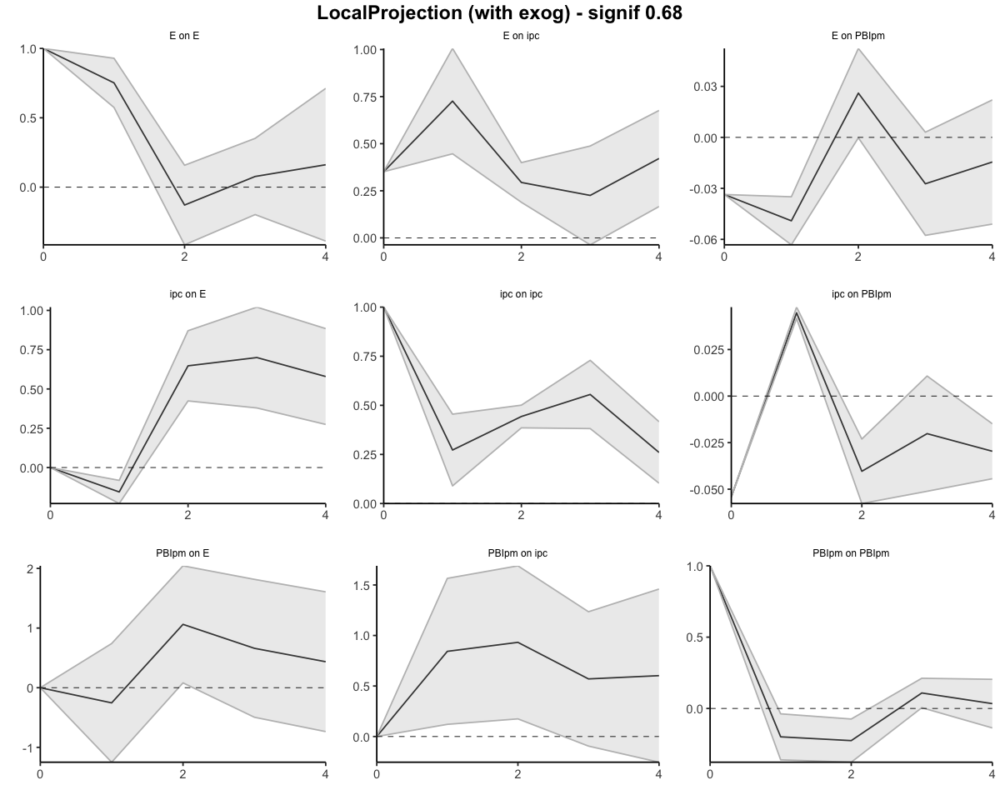

In [38]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("E", "ipc", "PBIpm"), exog=c("impp_usa"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.00000000
12,ipc,E,1,-0.1553346,-0.2289361,-0.08173319
13,ipc,E,2,0.4920313,0.1949769,0.78908585
14,ipc,E,3,1.1920454,0.5741743,1.80991658
15,ipc,E,4,1.7712812,0.8485241,2.69403824


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.000000,0.0000000
22,PBIpm,E,1,-0.2541406,-1.249050,0.7407688
23,PBIpm,E,2,0.8081664,-1.167874,2.7842072
24,PBIpm,E,3,1.4689361,-1.662979,4.6008509
25,PBIpm,E,4,1.9044826,-2.398814,6.2077790


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.3514105,0.3514105,0.3514105
2,E,ipc,1,1.0774860,0.7978120,1.3571600
3,E,ipc,2,1.3717759,0.9867463,1.7568055
4,E,ipc,3,1.5972285,0.9498642,2.2445927
5,E,ipc,4,2.0187493,1.1163693,2.9211293


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.00000000,0.000000
27,PBIpm,ipc,1,0.8429776,0.12048695,1.565468
28,PBIpm,ipc,2,1.7750432,0.29515564,3.254931
29,PBIpm,ipc,3,2.3450992,0.20030527,4.489893
30,PBIpm,ipc,4,2.9477101,-0.05406673,5.949487


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.03360117,-0.03360117,-0.033601170
7,E,PBIpm,1,-0.08268637,-0.09681469,-0.068558057
8,E,PBIpm,2,-0.05665695,-0.09706962,-0.016244288
9,E,PBIpm,3,-0.08396088,-0.15471535,-0.013206409
10,E,PBIpm,4,-0.09843749,-0.20572287,0.008847884


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.054089281,-0.05408928,-0.054089281
17,ipc,PBIpm,1,-0.009398509,-0.01246692,-0.006330096
18,ipc,PBIpm,2,-0.049775726,-0.07015768,-0.029393770
19,ipc,PBIpm,3,-0.069949499,-0.12127006,-0.018628935
20,ipc,PBIpm,4,-0.099580107,-0.16563482,-0.033525399


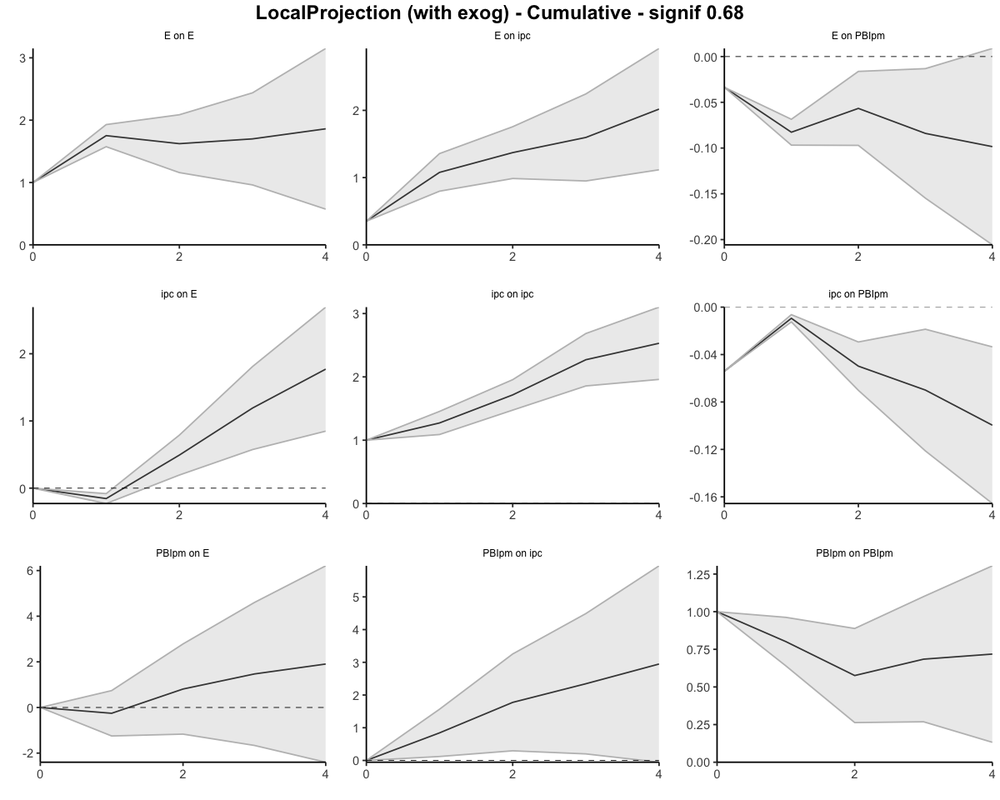

In [39]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("E", "ipc", "PBIpm"), exog=c("impp_usa"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

#### impp_usa exógena y el resto endógenas - 1 lag

Bootstrap por bloques circular: 500 réplicas, bloques de 10 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos, exógenas: impp_usa )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.3514         0.3514       1.0000
         1              1.0775         0.6151       1.7518
         2              1.3718         0.8453       1.6228
         3              1.5972         0.9397       1.6998
         4              2.0187         1.0845       1.8614
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.3514             0.3514
                  0.7261             0.2637
                  0.2943             0.2302
                  0.2255             0.0944
                  0.4215             0.1448


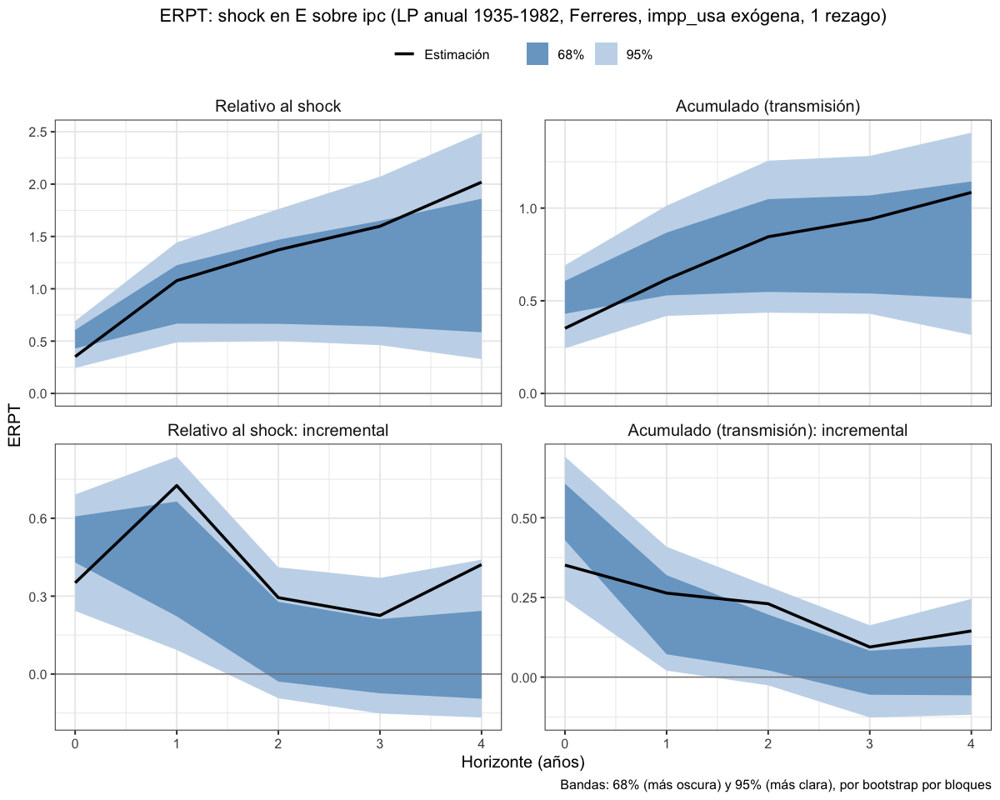

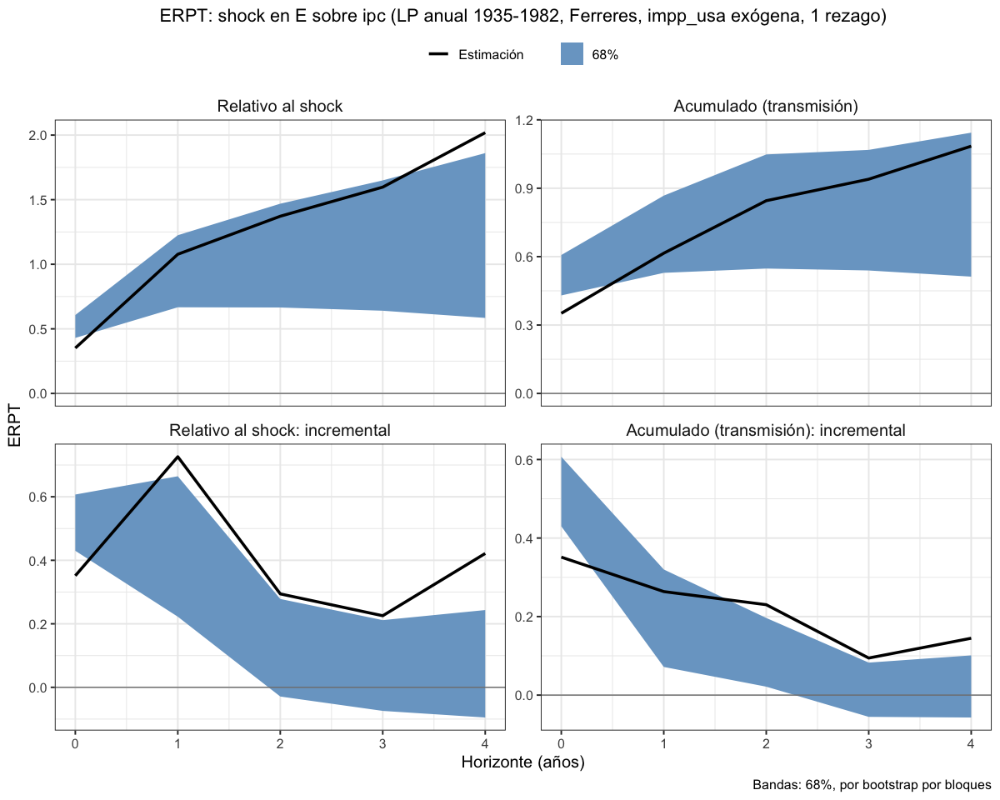

In [40]:
# Anual 1935–1982, Ferreres. impp_usa exógena y el resto endógenas, 1 rezago
lp_erpt_anual_ferr_35_82_exog_p1 <- erpt_lp(df_ERPT_Arg_1935_1982, endog = c("E", "ipc", "PBIpm"), exog = c("impp_usa"),
                                            fixed_lags = 1, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_ferr_35_82_exog_p1, "lp_erpt_anual_ferr_35_82_exog_p1.rds")
titulo_ferr_35_82_exog <- "ERPT: shock en E sobre ipc (LP anual 1935-1982, Ferreres, impp_usa exógena, 1 rezago)"
graficar_erpt_lp(lp_erpt_anual_ferr_35_82_exog_p1, titulo = titulo_ferr_35_82_exog,
                 archivo = "lp_erpt_anual_ferr_35_82_exog_p1")
graficar_erpt_lp(lp_erpt_anual_ferr_35_82_exog_p1, titulo = titulo_ferr_35_82_exog, niveles = 0.68,
                 archivo = "lp_erpt_anual_ferr_35_82_exog_p1_68")

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.0000000
12,ipc,E,1,-0.6003779,-0.76037888,-0.4403769
13,ipc,E,2,0.3506699,0.06130142,0.6400385
14,ipc,E,3,1.0080106,0.71207349,1.3039477
15,ipc,E,4,0.2534169,-0.13077837,0.6376122


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.00000000,0.0000000
22,PBIpm,E,1,-0.4669512,-1.18932996,0.2554275
23,PBIpm,E,2,1.1437973,0.15897145,2.1286231
24,PBIpm,E,3,0.6592988,-0.09386216,1.4124599
25,PBIpm,E,4,-0.5531014,-1.55433082,0.4481279


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.3123551,0.31235507,0.3123551
2,E,ipc,1,0.6837076,0.51523066,0.8521846
3,E,ipc,2,0.2788525,0.10499976,0.4527053
4,E,ipc,3,0.1153815,-0.16462902,0.3953920
5,E,ipc,4,0.4332326,0.05100938,0.8154558


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.000000
27,PBIpm,ipc,1,0.9027474,0.1542803,1.651214
28,PBIpm,ipc,2,0.6045317,-0.3947956,1.603859
29,PBIpm,ipc,3,0.7071052,-0.1932455,1.607456
30,PBIpm,ipc,4,0.3044148,-0.5965962,1.205426


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.009766106,-0.009766106,-0.009766106
7,E,PBIpm,1,-0.047176349,-0.071328879,-0.023023819
8,E,PBIpm,2,0.034907970,-0.023199526,0.093015467
9,E,PBIpm,3,-0.047137159,-0.091653312,-0.002621005
10,E,PBIpm,4,-0.028675631,-0.071028731,0.013677468


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.046192292,-0.04619229,-0.04619229
17,ipc,PBIpm,1,0.108687450,0.08344507,0.13392983
18,ipc,PBIpm,2,-0.009609280,-0.07619495,0.05697639
19,ipc,PBIpm,3,0.015846624,-0.03117189,0.06286514
20,ipc,PBIpm,4,-0.006676139,-0.04978212,0.03642984


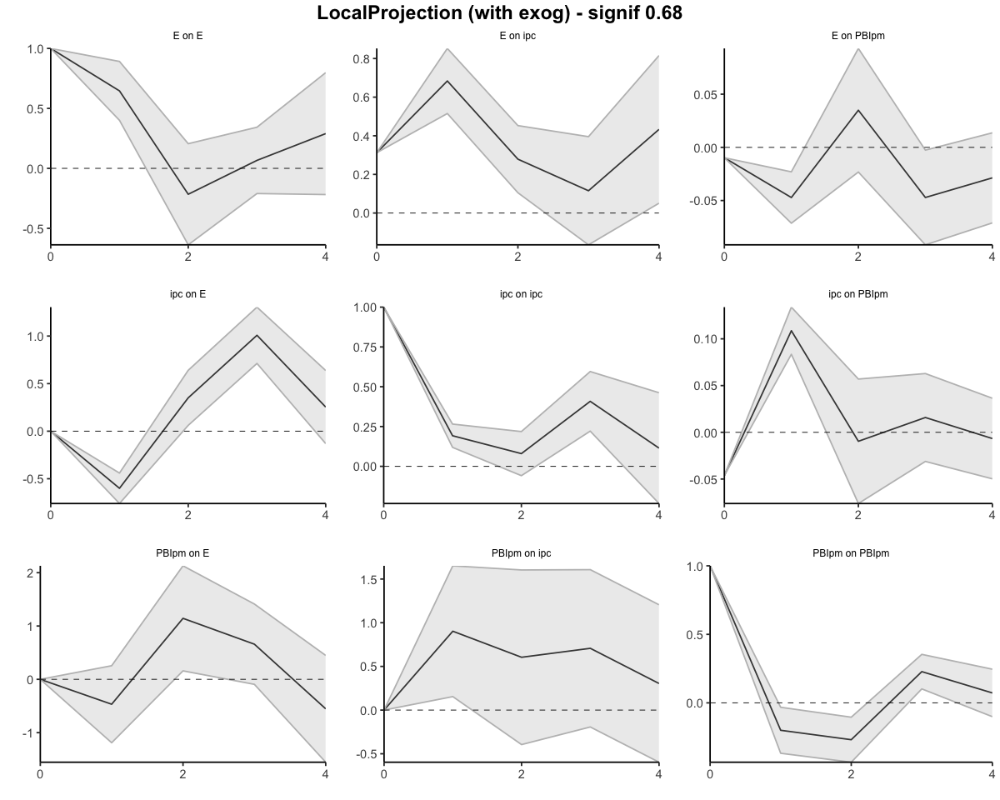

In [41]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("E", "ipc", "PBIpm"), exog=c("impp_usa"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,47,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.0000000
12,ipc,E,1,-0.6003779,-0.76037888,-0.4403769
13,ipc,E,2,-0.2497079,-0.69907746,0.1996616
14,ipc,E,3,0.7583027,0.01299603,1.5036093
15,ipc,E,4,1.0117196,-0.11778235,2.1412215


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.000000,0.0000000
22,PBIpm,E,1,-0.4669512,-1.189330,0.2554275
23,PBIpm,E,2,0.6768461,-1.030359,2.3840506
24,PBIpm,E,3,1.3361449,-1.124221,3.7965105
25,PBIpm,E,4,0.7830435,-2.678551,4.2446384


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.3123551,0.3123551,0.3123551
2,E,ipc,1,0.9960627,0.8275857,1.1645396
3,E,ipc,2,1.2749152,0.9325855,1.6172449
4,E,ipc,3,1.3902967,0.7679565,2.0126369
5,E,ipc,4,1.8235293,0.8189658,2.8280927


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.000000
27,PBIpm,ipc,1,0.9027474,0.1542803,1.651214
28,PBIpm,ipc,2,1.5072791,-0.2405153,3.255073
29,PBIpm,ipc,3,2.2143843,-0.4337608,4.862529
30,PBIpm,ipc,4,2.5187991,-1.0303570,6.067955


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.009766106,-0.009766106,-0.009766106
7,E,PBIpm,1,-0.056942455,-0.081094985,-0.032789925
8,E,PBIpm,2,-0.022034484,-0.104294511,0.060225542
9,E,PBIpm,3,-0.069171643,-0.195947822,0.057604537
10,E,PBIpm,4,-0.097847274,-0.266976553,0.071282005


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.04619229,-0.04619229,-0.04619229
17,ipc,PBIpm,1,0.06249516,0.03725278,0.08773753
18,ipc,PBIpm,2,0.05288588,-0.03894217,0.14471393
19,ipc,PBIpm,3,0.06873250,-0.07011406,0.20757907
20,ipc,PBIpm,4,0.06205636,-0.11989618,0.24400891


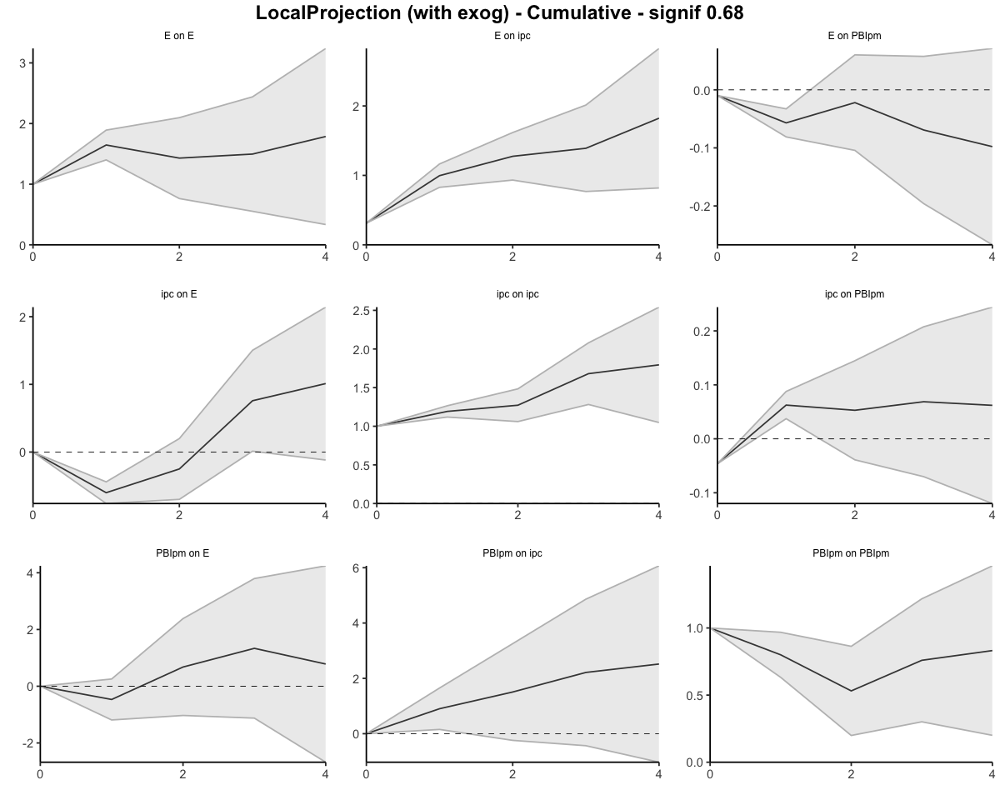

In [42]:
res <- run_lp_model(df_ERPT_Arg_1935_1982, endog=c("E", "ipc", "PBIpm"), exog=c("impp_usa"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

#### impp_usa exógena y el resto endógenas - 2 lags

Bootstrap por bloques circular: 500 réplicas, bloques de 12 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 2 rezagos, exógenas: impp_usa )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.3124         0.3124       1.0000
         1              0.9961         0.6051       1.6461
         2              1.2749         0.8915       1.4301
         3              1.3903         0.9290       1.4966
         4              1.8235         1.0208       1.7864
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.3124             0.3124
                  0.6837             0.2928
                  0.2789             0.2864
                  0.1154             0.0375
                  0.4332             0.0918


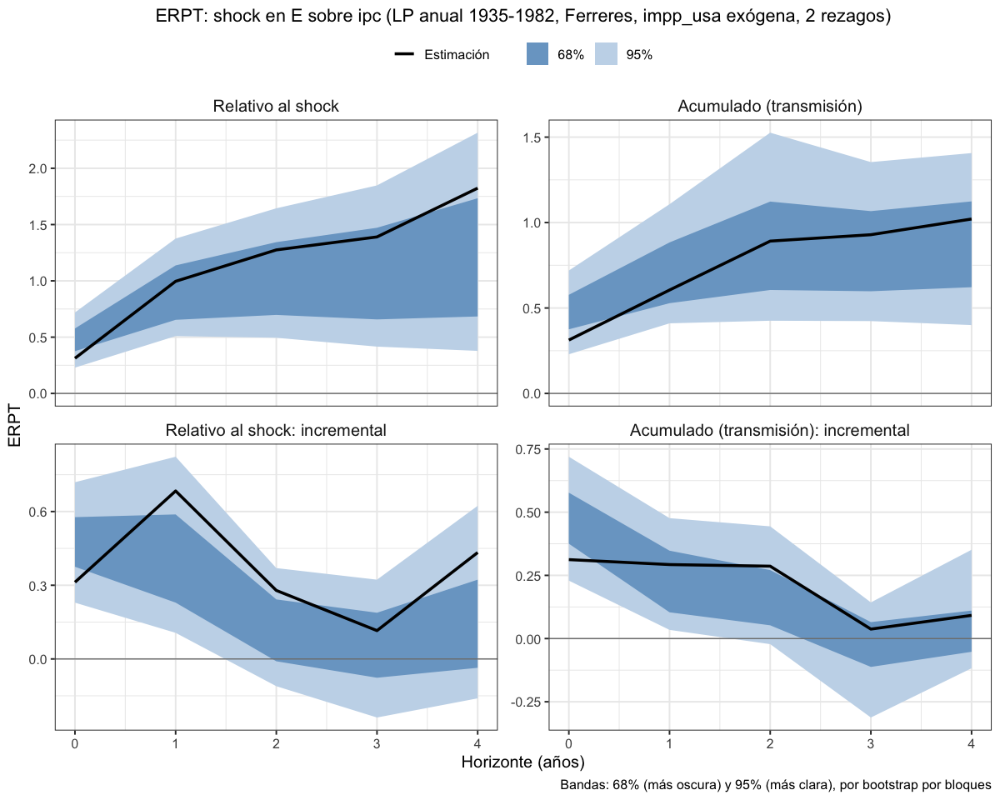

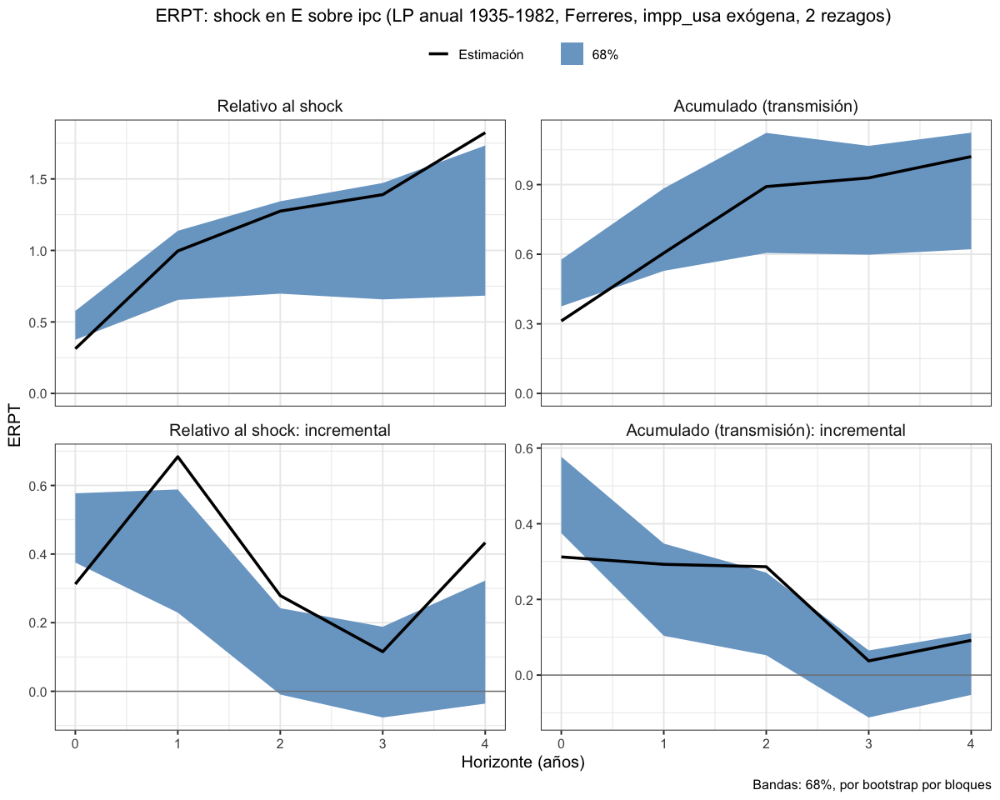

In [43]:
# Anual 1935–1982, Ferreres. impp_usa exógena y el resto endógenas, 2 rezagos
lp_erpt_anual_ferr_35_82_exog_p2 <- erpt_lp(df_ERPT_Arg_1935_1982, endog = c("E", "ipc", "PBIpm"), exog = c("impp_usa"),
                                            fixed_lags = 2, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_ferr_35_82_exog_p2, "lp_erpt_anual_ferr_35_82_exog_p2.rds")
titulo_ferr_35_82_exog_p2 <- "ERPT: shock en E sobre ipc (LP anual 1935-1982, Ferreres, impp_usa exógena, 2 rezagos)"
graficar_erpt_lp(lp_erpt_anual_ferr_35_82_exog_p2, titulo = titulo_ferr_35_82_exog_p2,
                 archivo = "lp_erpt_anual_ferr_35_82_exog_p2")
graficar_erpt_lp(lp_erpt_anual_ferr_35_82_exog_p2, titulo = titulo_ferr_35_82_exog_p2, niveles = 0.68,
                 archivo = "lp_erpt_anual_ferr_35_82_exog_p2_68")

### 1935-1987. Todas endógenas - Selected orders: 1 lag

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"impp_usa, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-0.5035104,-0.5035104,-0.5035104
2,impp_usa,E,1,1.2762057,0.1976794,2.3547321
3,impp_usa,E,2,1.8727509,1.0520818,2.6934199
4,impp_usa,E,3,1.3890638,0.2565209,2.5216067
5,impp_usa,E,4,1.6401084,0.5831853,2.6970316


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.0000000,0.00000000,0.00000000
37,ipc,E,1,-0.1396800,-0.22346660,-0.05589337
38,ipc,E,2,0.1719200,-0.06357525,0.40741521
39,ipc,E,3,0.2777921,-0.25789262,0.81347685
40,ipc,E,4,0.7271300,0.41755428,1.03670562


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.0000000,0.00000000
52,PBIpm,E,1,1.7842264,-0.1419487,3.71040154
53,PBIpm,E,2,0.4671785,-0.3614888,1.29584584
54,PBIpm,E,3,-1.7273714,-3.5535116,0.09876886
55,PBIpm,E,4,-0.8025488,-2.3567017,0.75160405


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
56,PBIpm,ipc,0,0.0000000,0.0000000,0.000000000
57,PBIpm,ipc,1,2.1796094,0.8423650,3.516853867
58,PBIpm,ipc,2,0.6203383,-0.0694319,1.310108581
59,PBIpm,ipc,3,-1.7624960,-3.5195547,-0.005437413
60,PBIpm,ipc,4,-0.6860680,-2.0823724,0.710236513


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,E,PBIpm,0,-0.029462316,-0.02946232,-0.029462316
27,E,PBIpm,1,-0.028609275,-0.04072462,-0.016493933
28,E,PBIpm,2,0.002597925,-0.02365738,0.028853230
29,E,PBIpm,3,-0.029192419,-0.06282319,0.004438353
30,E,PBIpm,4,-0.013934345,-0.04604576,0.018177073


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,impp_usa,PBIpm,0,0.15794432,0.15794432,0.15794432
12,impp_usa,PBIpm,1,-0.12059370,-0.20778915,-0.03339826
13,impp_usa,PBIpm,2,-0.12257942,-0.18387033,-0.06128851
14,impp_usa,PBIpm,3,-0.02688086,-0.08919503,0.03543330
15,impp_usa,PBIpm,4,-0.01261442,-0.09088345,0.06565461


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
41,ipc,PBIpm,0,-0.041714084,-0.04171408,-0.041714084
42,ipc,PBIpm,1,0.029363311,0.02452810,0.034198525
43,ipc,PBIpm,2,-0.026855389,-0.04135623,-0.012354550
44,ipc,PBIpm,3,0.005389569,-0.01995162,0.030730763
45,ipc,PBIpm,4,-0.023377520,-0.04290033,-0.003854708


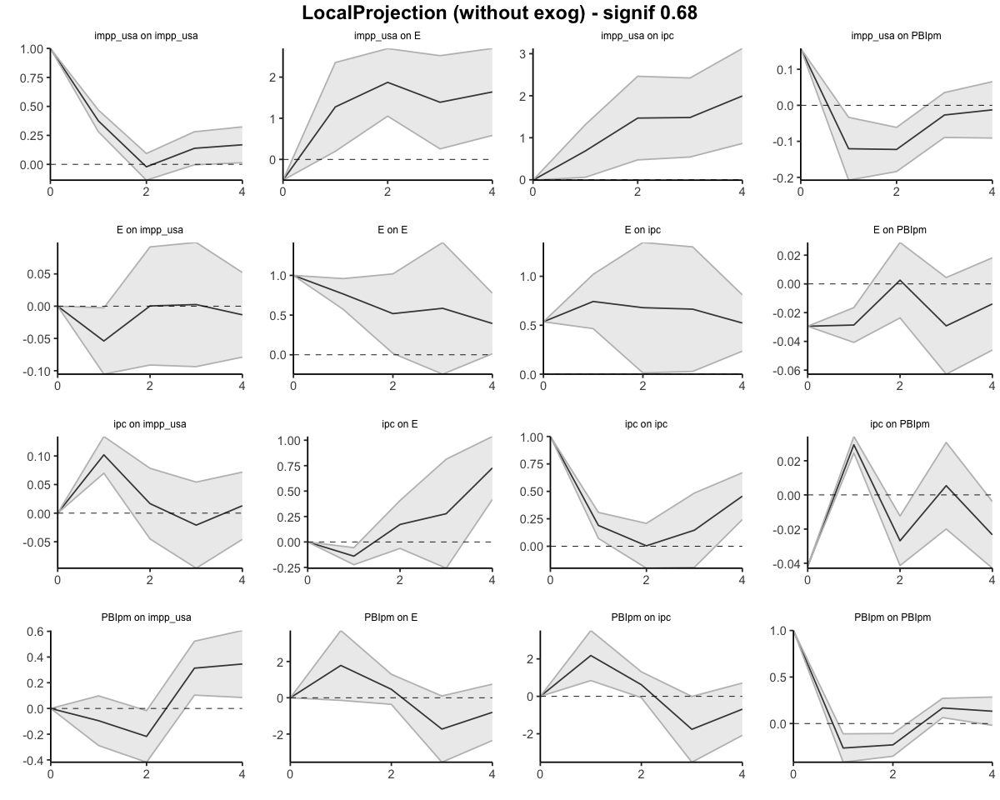

In [44]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("impp_usa", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"impp_usa, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-0.5035104,-0.5035104,-0.5035104
2,impp_usa,E,1,0.7726953,-0.3058310,1.8512216
3,impp_usa,E,2,2.6454462,0.7462508,4.5446416
4,impp_usa,E,3,4.0345100,1.0027717,7.0662483
5,impp_usa,E,4,5.6746184,1.5859570,9.7632799


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.0000000,0.00000000
37,ipc,E,1,-0.13967999,-0.2234666,-0.05589337
38,ipc,E,2,0.03223999,-0.2870419,0.35152184
39,ipc,E,3,0.31003211,-0.5449345,1.16499869
40,ipc,E,4,1.03716206,-0.1273802,2.20170432


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.0000000,0.000000
52,PBIpm,E,1,1.7842264,-0.1419487,3.710402
53,PBIpm,E,2,2.2514049,-0.5034376,5.006247
54,PBIpm,E,3,0.5240335,-4.0569492,5.105016
55,PBIpm,E,4,-0.2785153,-6.4136509,5.856620


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
56,PBIpm,ipc,0,0.0000000,0.0000000,0.000000
57,PBIpm,ipc,1,2.1796094,0.8423650,3.516854
58,PBIpm,ipc,2,2.7999478,0.7729331,4.826962
59,PBIpm,ipc,3,1.0374517,-2.7466216,4.821525
60,PBIpm,ipc,4,0.3513838,-4.8289940,5.531762


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,E,PBIpm,0,-0.02946232,-0.02946232,-0.029462316
27,E,PBIpm,1,-0.05807159,-0.07018693,-0.045956249
28,E,PBIpm,2,-0.05547367,-0.09384431,-0.017103019
29,E,PBIpm,3,-0.08466609,-0.15666750,-0.012664666
30,E,PBIpm,4,-0.09860043,-0.20271327,0.005512407


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,impp_usa,PBIpm,0,0.15794432,0.15794432,0.15794432
12,impp_usa,PBIpm,1,0.03735061,-0.04984484,0.12454606
13,impp_usa,PBIpm,2,-0.08522881,-0.23371516,0.06325755
14,impp_usa,PBIpm,3,-0.11210967,-0.32291019,0.09869085
15,impp_usa,PBIpm,4,-0.12472409,-0.41379364,0.16434545


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
41,ipc,PBIpm,0,-0.04171408,-0.04171408,-0.041714084
42,ipc,PBIpm,1,-0.01235077,-0.01718599,-0.007515559
43,ipc,PBIpm,2,-0.03920616,-0.05854221,-0.019870109
44,ipc,PBIpm,3,-0.03381659,-0.07849384,0.010860654
45,ipc,PBIpm,4,-0.05719411,-0.12139417,0.007005946


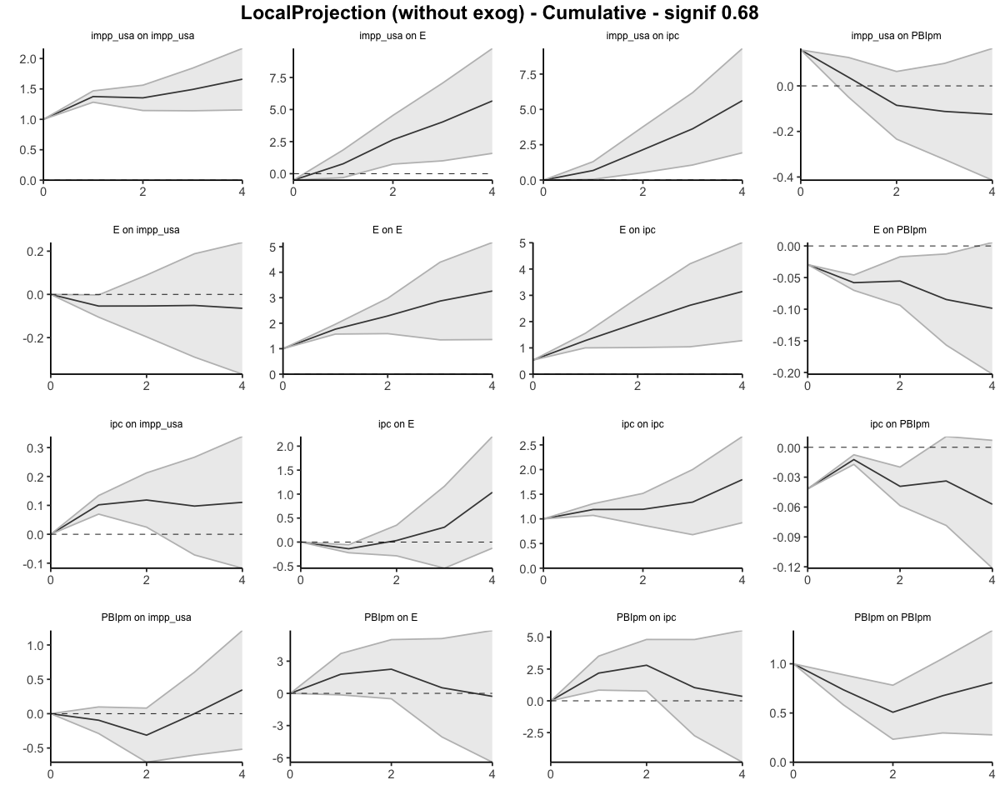

In [45]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("impp_usa", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

#### Todas endógenas - 1 lag

Bootstrap por bloques circular: 500 réplicas, bloques de 10 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.5355         0.5355       1.0000
         1              1.2781         0.7237       1.7660
         2              1.9575         0.8569       2.2844
         3              2.6218         0.9136       2.8696
         4              3.1443         0.9634       3.2638
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.5355             0.5355
                  0.7427             0.1883
                  0.6794             0.1332
                  0.6643             0.0567
                  0.5226             0.0498


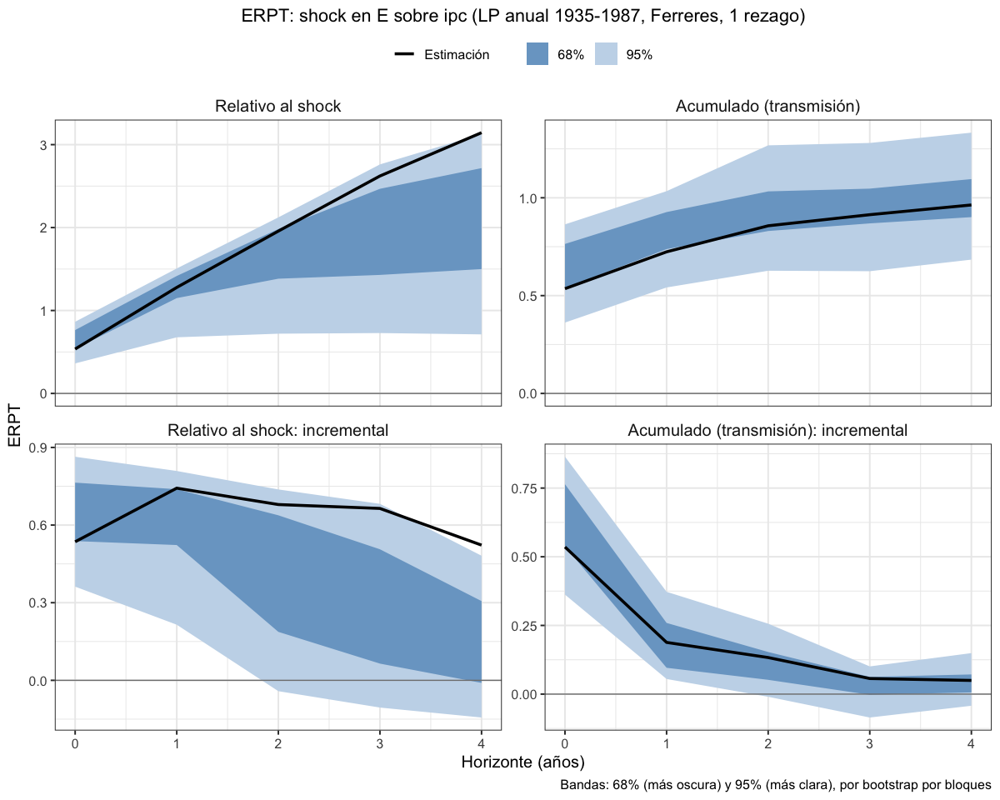

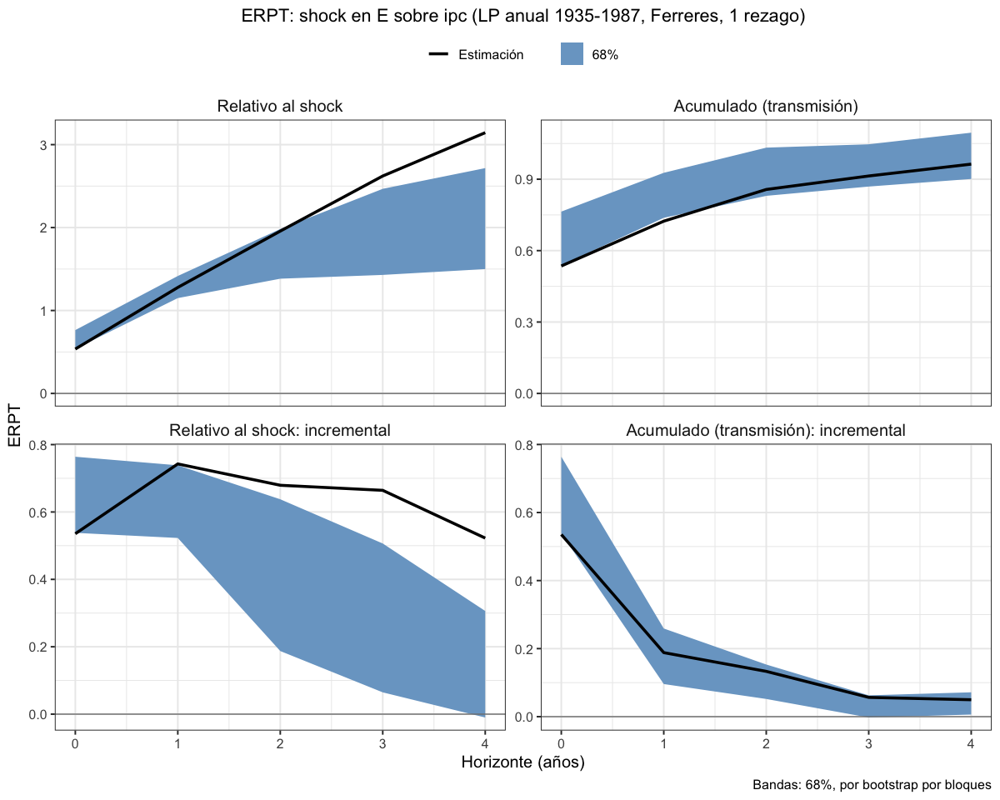

In [46]:
# Anual 1935–1987, Ferreres. Todas endógenas, 1 rezago
lp_erpt_anual_ferr_35_87_endog_p1 <- erpt_lp(df_ERPT_Arg_1935_1987, endog = c("impp_usa", "E", "ipc", "PBIpm"),
                                             fixed_lags = 1, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_ferr_35_87_endog_p1, "lp_erpt_anual_ferr_35_87_endog_p1.rds")
titulo_ferr_35_87 <- "ERPT: shock en E sobre ipc (LP anual 1935-1987, Ferreres, 1 rezago)"
graficar_erpt_lp(lp_erpt_anual_ferr_35_87_endog_p1, titulo = titulo_ferr_35_87,
                 archivo = "lp_erpt_anual_ferr_35_87_endog_p1")
graficar_erpt_lp(lp_erpt_anual_ferr_35_87_endog_p1, titulo = titulo_ferr_35_87, niveles = 0.68,
                 archivo = "lp_erpt_anual_ferr_35_87_endog_p1_68")

### 1935-1987. 1 exógena y el resto endógenas - Selected orders: 1 lag

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.00000000
12,ipc,E,1,-0.1229831,-0.22479497,-0.02117113
13,ipc,E,2,0.1762919,-0.06695809,0.41954184
14,ipc,E,3,0.2616272,-0.29114667,0.81440114
15,ipc,E,4,0.7196196,0.39550008,1.04373920


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.00000000
22,PBIpm,E,1,1.7842264,-0.1419487,3.71040154
23,PBIpm,E,2,0.4671785,-0.3614888,1.29584584
24,PBIpm,E,3,-1.7273714,-3.5535116,0.09876886
25,PBIpm,E,4,-0.8025488,-2.3567017,0.75160405


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.5289700,0.52896997,0.5289700
2,E,ipc,1,0.7330774,0.46174963,1.0044052
3,E,ipc,2,0.6769450,0.01463347,1.3392566
4,E,ipc,3,0.6701018,0.04274122,1.2974623
5,E,ipc,4,0.5222276,0.24164397,0.8028112


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.000000000
27,PBIpm,ipc,1,2.1796094,0.8423650,3.516853867
28,PBIpm,ipc,2,0.6203383,-0.0694319,1.310108581
29,PBIpm,ipc,3,-1.7624960,-3.5195547,-0.005437413
30,PBIpm,ipc,4,-0.6860680,-2.0823724,0.710236513


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.033028018,-0.03302802,-0.033028018
7,E,PBIpm,1,-0.027790736,-0.03928970,-0.016291770
8,E,PBIpm,2,0.003651177,-0.02204139,0.029343747
9,E,PBIpm,3,-0.029870332,-0.06293964,0.003198971
10,E,PBIpm,4,-0.014291592,-0.04569211,0.017108925


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.032356003,-0.03235600,-0.032356003
17,ipc,PBIpm,1,0.026901615,0.02063957,0.033163660
18,ipc,PBIpm,2,-0.028998991,-0.04464270,-0.013355277
19,ipc,PBIpm,3,0.006957718,-0.01935153,0.033266971
20,ipc,PBIpm,4,-0.022135805,-0.04308333,-0.001188276


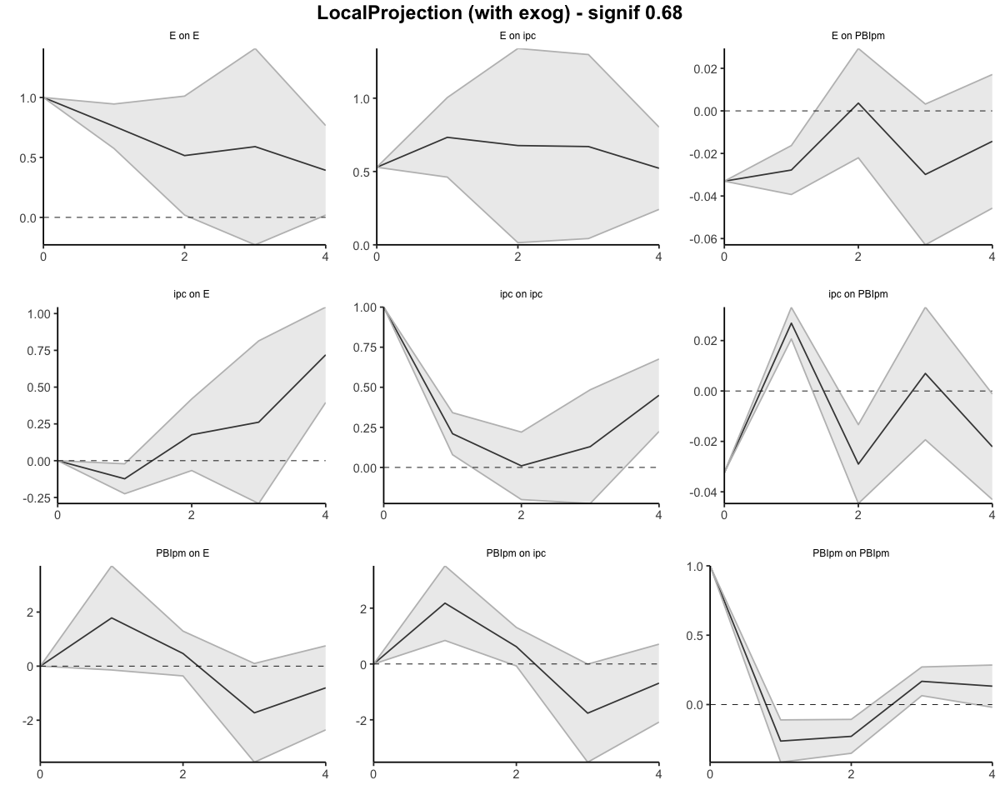

In [47]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("E", "ipc", "PBIpm"), exog=c("impp_usa"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,52,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.00000000
12,ipc,E,1,-0.12298305,-0.2247950,-0.02117113
13,ipc,E,2,0.05330882,-0.2917531,0.39837071
14,ipc,E,3,0.31493606,-0.5828997,1.21277185
15,ipc,E,4,1.03455569,-0.1873997,2.25651105


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.000000
22,PBIpm,E,1,1.7842264,-0.1419487,3.710402
23,PBIpm,E,2,2.2514049,-0.5034376,5.006247
24,PBIpm,E,3,0.5240335,-4.0569492,5.105016
25,PBIpm,E,4,-0.2785153,-6.4136509,5.856620


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.528970,0.5289700,0.528970
2,E,ipc,1,1.262047,0.9907196,1.533375
3,E,ipc,2,1.938992,1.0053531,2.872632
4,E,ipc,3,2.609094,1.0480943,4.170094
5,E,ipc,4,3.131322,1.2897383,4.972905


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.000000
27,PBIpm,ipc,1,2.1796094,0.8423650,3.516854
28,PBIpm,ipc,2,2.7999478,0.7729331,4.826962
29,PBIpm,ipc,3,1.0374517,-2.7466216,4.821525
30,PBIpm,ipc,4,0.3513838,-4.8289940,5.531762


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.03302802,-0.03302802,-0.0330280182
7,E,PBIpm,1,-0.06081875,-0.07231772,-0.0493197879
8,E,PBIpm,2,-0.05716758,-0.09435911,-0.0199760409
9,E,PBIpm,3,-0.08703791,-0.15729875,-0.0167770694
10,E,PBIpm,4,-0.10132950,-0.20299086,0.0003318557


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.032356003,-0.03235600,-0.032356003
17,ipc,PBIpm,1,-0.005454388,-0.01171643,0.000807657
18,ipc,PBIpm,2,-0.034453378,-0.05635914,-0.012547620
19,ipc,PBIpm,3,-0.027495660,-0.07571067,0.020719350
20,ipc,PBIpm,4,-0.049631464,-0.11879400,0.019531074


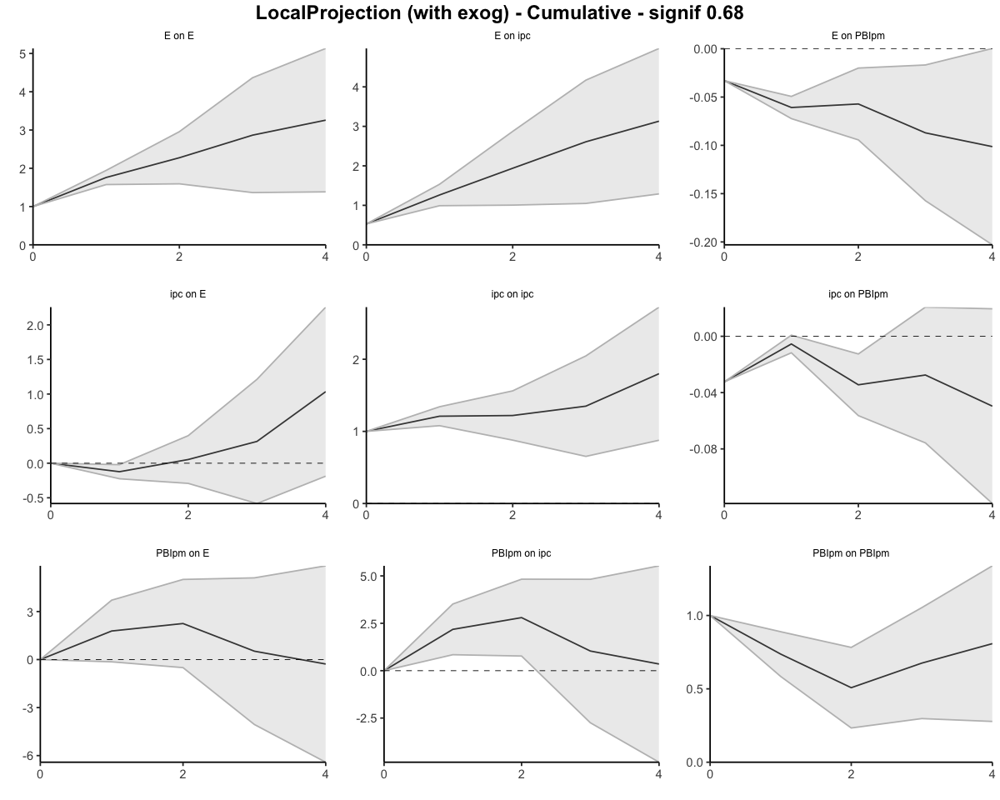

In [48]:
res <- run_lp_model(df_ERPT_Arg_1935_1987, endog=c("E", "ipc", "PBIpm"), exog=c("impp_usa"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

#### impp_usa exógena y el resto endógenas - 1 lag

Bootstrap por bloques circular: 500 réplicas, bloques de 10 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos, exógenas: impp_usa )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.5290         0.5290       1.0000
         1              1.2620         0.7170       1.7601
         2              1.9390         0.8521       2.2755
         3              2.6091         0.9105       2.8656
         4              3.1313         0.9611       3.2581
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.5290             0.5290
                  0.7331             0.1881
                  0.6769             0.1351
                  0.6701             0.0584
                  0.5222             0.0506


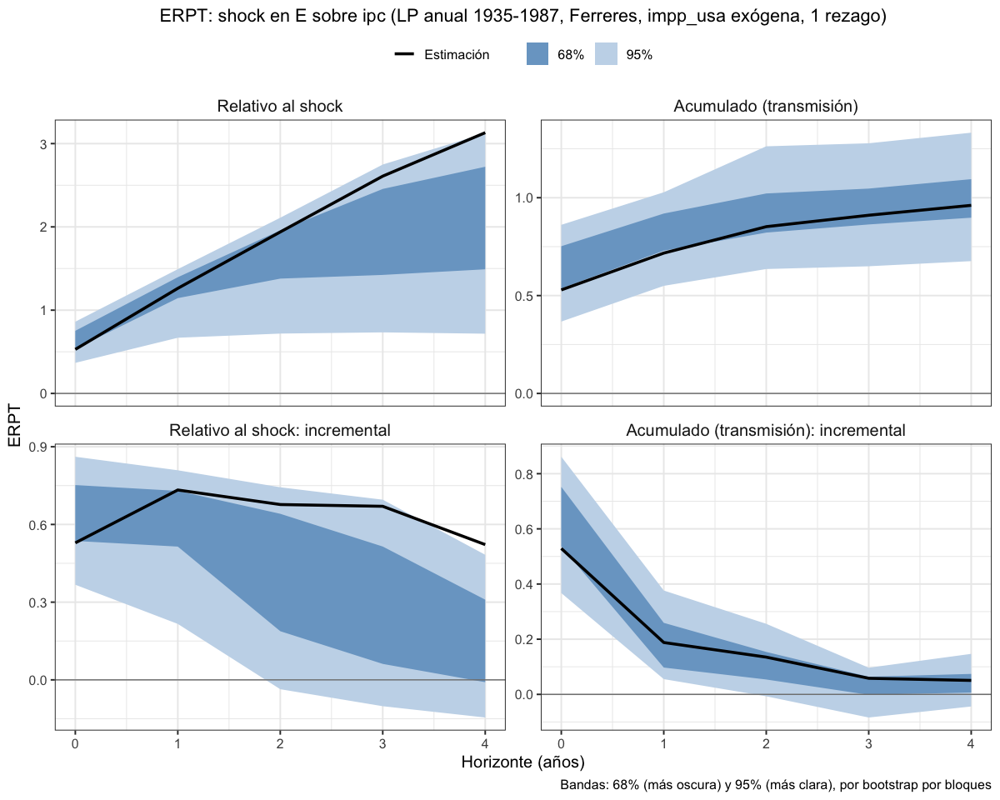

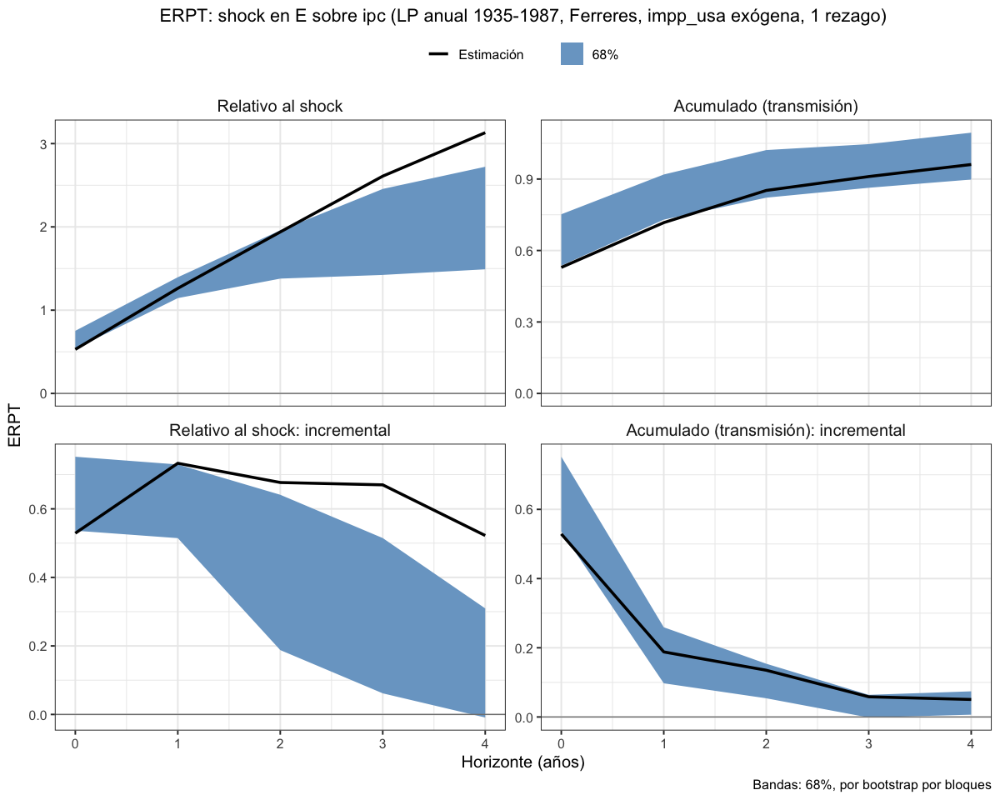

In [49]:
# Anual 1935–1987, Ferreres. impp_usa exógena y el resto endógenas, 1 rezago
lp_erpt_anual_ferr_35_87_exog_p1 <- erpt_lp(df_ERPT_Arg_1935_1987, endog = c("E", "ipc", "PBIpm"), exog = c("impp_usa"),
                                            fixed_lags = 1, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_ferr_35_87_exog_p1, "lp_erpt_anual_ferr_35_87_exog_p1.rds")
titulo_ferr_35_87_exog <- "ERPT: shock en E sobre ipc (LP anual 1935-1987, Ferreres, impp_usa exógena, 1 rezago)"
graficar_erpt_lp(lp_erpt_anual_ferr_35_87_exog_p1, titulo = titulo_ferr_35_87_exog,
                 archivo = "lp_erpt_anual_ferr_35_87_exog_p1")
graficar_erpt_lp(lp_erpt_anual_ferr_35_87_exog_p1, titulo = titulo_ferr_35_87_exog, niveles = 0.68,
                 archivo = "lp_erpt_anual_ferr_35_87_exog_p1_68")

### 1935-1990. Todas endógenas - Selected orders: 1 lag

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"impp_usa, E, ipc, PBIpm",4


LocalProjection (without exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-0.2791114,-0.27911144,-0.2791114
2,impp_usa,E,1,1.4176904,0.31573952,2.5196413
3,impp_usa,E,2,2.0641548,1.04081817,3.0874914
4,impp_usa,E,3,1.0196685,-0.62728623,2.6666233
5,impp_usa,E,4,1.1481945,0.06707402,2.2293149


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.00000000,0.0000000
37,ipc,E,1,0.07242113,-0.08327228,0.2281145
38,ipc,E,2,0.21153967,-0.05676316,0.4798425
39,ipc,E,3,0.41338895,-0.06609731,0.8928752
40,ipc,E,4,1.06697975,0.80166545,1.3322941


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.0000000,0.0000000,0.0000000
52,PBIpm,E,1,1.3152606,-0.7226729,3.3531941
53,PBIpm,E,2,1.5695668,0.2372193,2.9019143
54,PBIpm,E,3,0.9048643,-1.6865376,3.4962661
55,PBIpm,E,4,-0.8449485,-2.5281028,0.8382058


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
56,PBIpm,ipc,0,0.0000000,0.0000000,0.000000
57,PBIpm,ipc,1,1.8860347,0.6716266,3.100443
58,PBIpm,ipc,2,1.5482256,0.4530981,2.643353
59,PBIpm,ipc,3,0.7322938,-1.3881180,2.852706
60,PBIpm,ipc,4,0.1833375,-1.5952962,1.961971


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,E,PBIpm,0,-0.03183823,-0.03183823,-0.031838229
27,E,PBIpm,1,-0.02372604,-0.03691392,-0.010538166
28,E,PBIpm,2,-0.00643347,-0.03449380,0.021626857
29,E,PBIpm,3,-0.02803337,-0.06417835,0.008111612
30,E,PBIpm,4,-0.02234296,-0.05319804,0.008512129


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,impp_usa,PBIpm,0,0.1498857532,0.14988575,0.14988575
12,impp_usa,PBIpm,1,-0.1238923867,-0.21125131,-0.03653347
13,impp_usa,PBIpm,2,-0.1258855247,-0.19123741,-0.06053364
14,impp_usa,PBIpm,3,-0.0143986373,-0.09102452,0.06222724
15,impp_usa,PBIpm,4,-0.0006227967,-0.09032538,0.08907979


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
41,ipc,PBIpm,0,-0.0379347706,-0.03793477,-0.03793477
42,ipc,PBIpm,1,0.0224365966,0.01664721,0.02822599
43,ipc,PBIpm,2,-0.0290001160,-0.04390813,-0.01409210
44,ipc,PBIpm,3,0.0003205336,-0.02468458,0.02532565
45,ipc,PBIpm,4,-0.0338374544,-0.04898054,-0.01869437


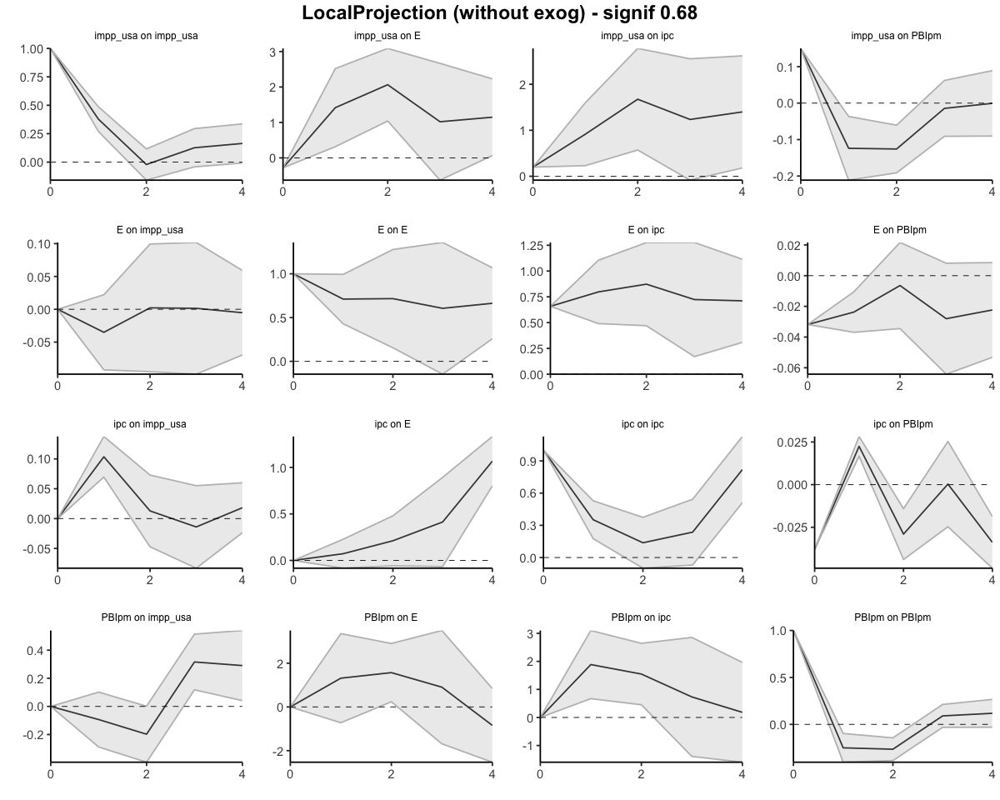

In [50]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("impp_usa", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,NA,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"impp_usa, E, ipc, PBIpm",4


LocalProjection (without exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,impp_usa,E,0,-0.2791114,-0.27911144,-0.2791114
2,impp_usa,E,1,1.1385790,0.03662808,2.2405298
3,impp_usa,E,2,3.2027337,1.07744624,5.3280212
4,impp_usa,E,3,4.2224023,0.45016001,7.9946445
5,impp_usa,E,4,5.3705967,0.51723403,10.2239594


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
36,ipc,E,0,0.00000000,0.00000000,0.0000000
37,ipc,E,1,0.07242113,-0.08327228,0.2281145
38,ipc,E,2,0.28396080,-0.14003544,0.7079570
39,ipc,E,3,0.69734975,-0.20613275,1.6008322
40,ipc,E,4,1.76432950,0.59553269,2.9331263


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
51,PBIpm,E,0,0.000000,0.0000000,0.000000
52,PBIpm,E,1,1.315261,-0.7226729,3.353194
53,PBIpm,E,2,2.884827,-0.4854536,6.255108
54,PBIpm,E,3,3.789692,-2.1719912,9.751375
55,PBIpm,E,4,2.944743,-4.7000940,10.589580


... (5 outputs left out)

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
56,PBIpm,ipc,0,0.000000,0.0000000,0.000000
57,PBIpm,ipc,1,1.886035,0.6716266,3.100443
58,PBIpm,ipc,2,3.434260,1.1247247,5.743796
59,PBIpm,ipc,3,4.166554,-0.2633933,8.596501
60,PBIpm,ipc,4,4.349892,-1.8586895,10.558473


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,E,PBIpm,0,-0.03183823,-0.03183823,-0.031838229
27,E,PBIpm,1,-0.05556427,-0.06875215,-0.042376396
28,E,PBIpm,2,-0.06199774,-0.10324595,-0.020749538
29,E,PBIpm,3,-0.09003111,-0.16742429,-0.012637927
30,E,PBIpm,4,-0.11237407,-0.22062233,-0.004125797


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,impp_usa,PBIpm,0,0.14988575,0.14988575,0.14988575
12,impp_usa,PBIpm,1,0.02599337,-0.06136555,0.11335229
13,impp_usa,PBIpm,2,-0.09989216,-0.25260296,0.05281864
14,impp_usa,PBIpm,3,-0.11429080,-0.34362748,0.11504589
15,impp_usa,PBIpm,4,-0.11491359,-0.43395286,0.20412568


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
41,ipc,PBIpm,0,-0.03793477,-0.03793477,-0.037934771
42,ipc,PBIpm,1,-0.01549817,-0.02128756,-0.009708784
43,ipc,PBIpm,2,-0.04449829,-0.06519569,-0.023800888
44,ipc,PBIpm,3,-0.04417776,-0.08988027,0.001524759
45,ipc,PBIpm,4,-0.07801521,-0.13886082,-0.017169606


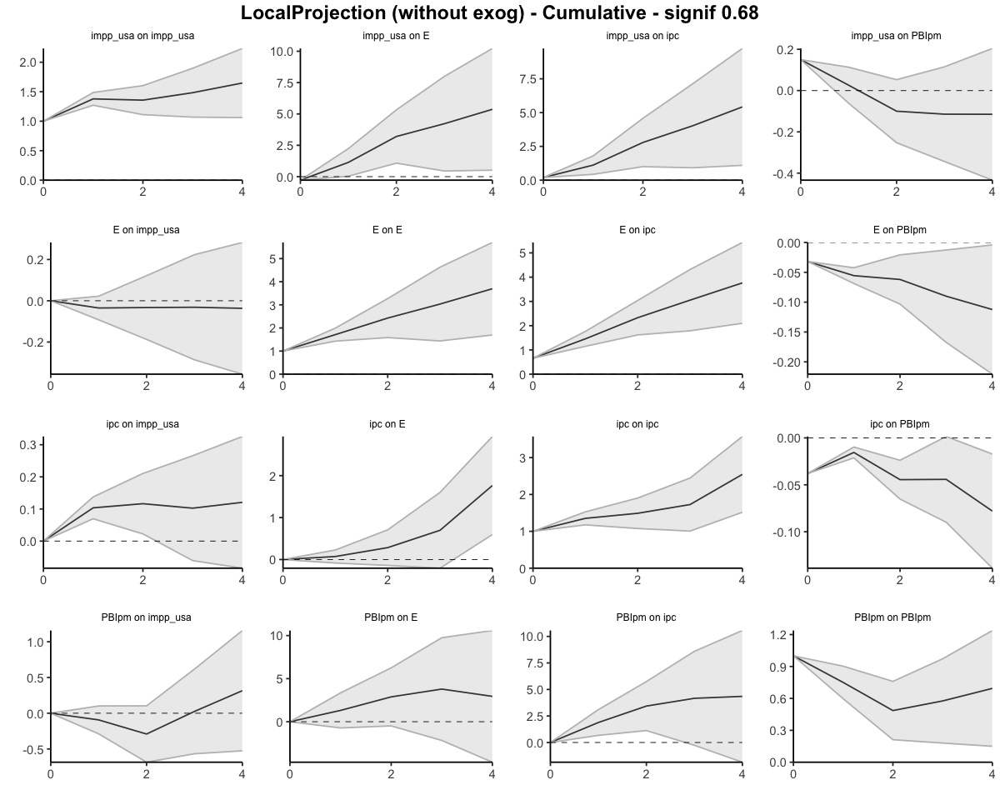

In [51]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("impp_usa", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative=TRUE)

#### Todas endógenas - 1 lag

Bootstrap por bloques circular: 500 réplicas, bloques de 10 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.6578         0.6578       1.0000
         1              1.4555         0.8505       1.7113
         2              2.3282         0.9590       2.4278
         3              3.0518         1.0060       3.0337
         4              3.7631         1.0179       3.6969
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.6578             0.6578
                  0.7977             0.1927
                  0.8728             0.1085
                  0.7235             0.0470
                  0.7113             0.0119


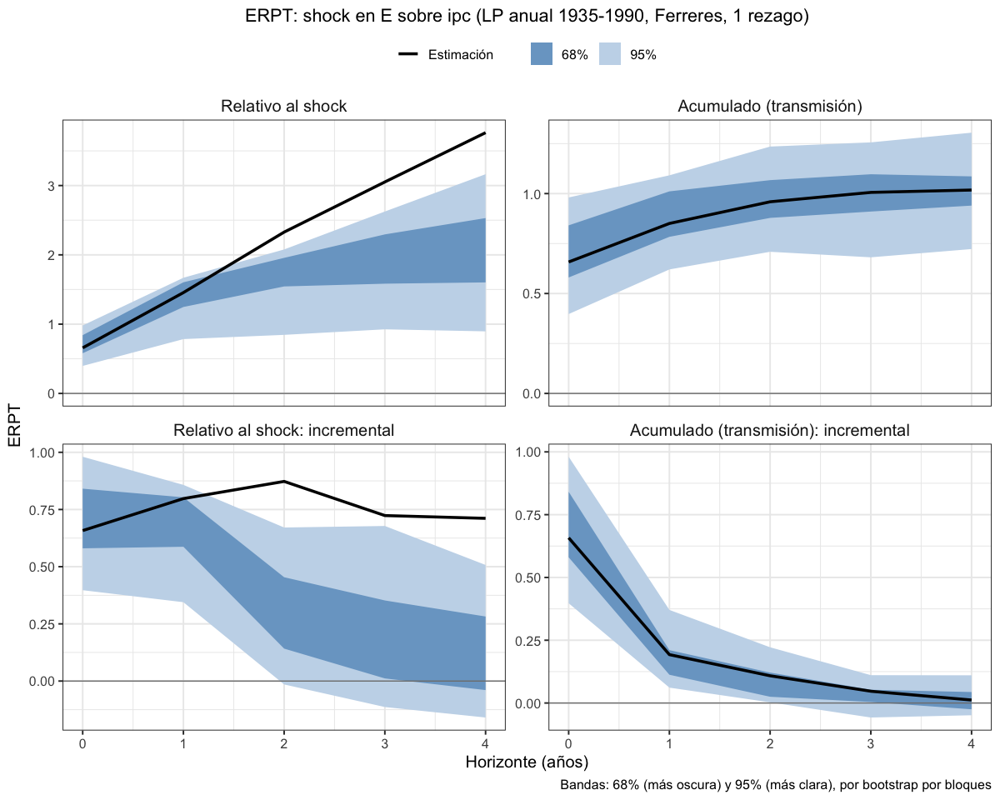

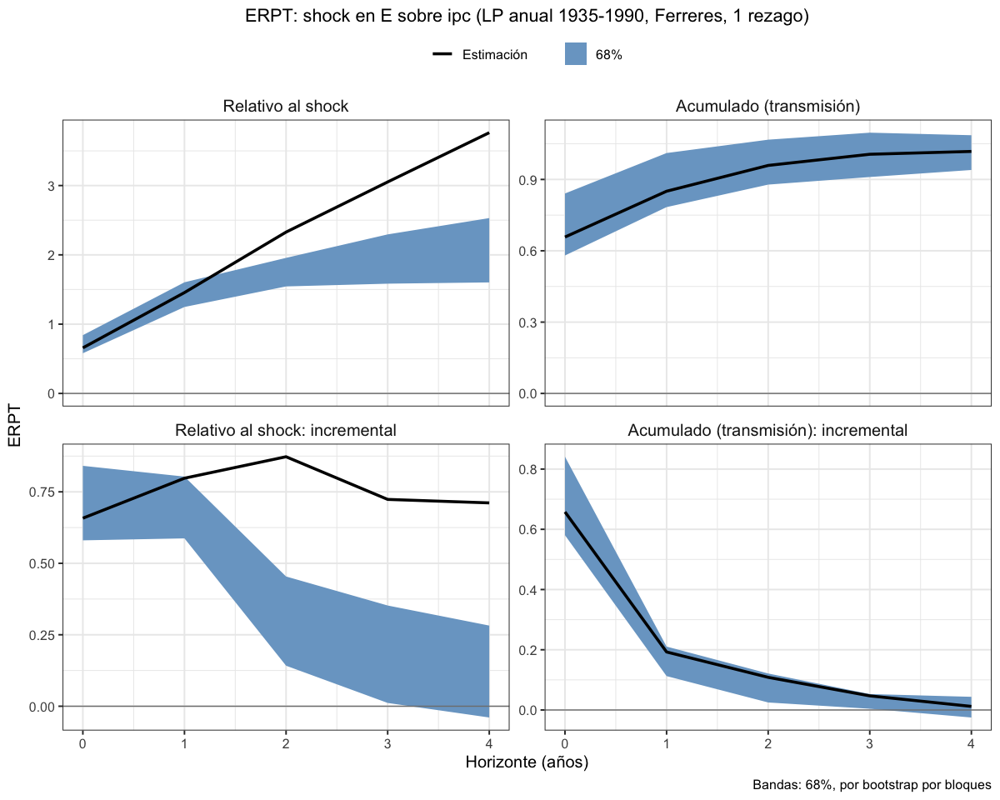

In [52]:
# Anual 1935–1990, Ferreres. Todas endógenas, 1 rezago
lp_erpt_anual_ferr_35_90_endog_p1 <- erpt_lp(df_ERPT_Arg_1935_1990, endog = c("impp_usa", "E", "ipc", "PBIpm"),
                                             fixed_lags = 1, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_ferr_35_90_endog_p1, "lp_erpt_anual_ferr_35_90_endog_p1.rds")
titulo_ferr_35_90 <- "ERPT: shock en E sobre ipc (LP anual 1935-1990, Ferreres, 1 rezago)"
graficar_erpt_lp(lp_erpt_anual_ferr_35_90_endog_p1, titulo = titulo_ferr_35_90,
                 archivo = "lp_erpt_anual_ferr_35_90_endog_p1")
graficar_erpt_lp(lp_erpt_anual_ferr_35_90_endog_p1, titulo = titulo_ferr_35_90, niveles = 0.68,
                 archivo = "lp_erpt_anual_ferr_35_90_endog_p1_68")

### 1935-1990. 1 exógena y el resto endógenas - Selected orders: 1, 4 y 5 lags 
(como ninguno es RB, corro también 2 lags, que es RB y lo corrí en el VAR)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.00000000,0.0000000
12,ipc,E,1,0.08764741,-0.09163840,0.2669332
13,ipc,E,2,0.22970997,-0.05401696,0.5134369
14,ipc,E,3,0.42386423,-0.08562173,0.9333502
15,ipc,E,4,1.05719810,0.77239854,1.3419977


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.0000000
22,PBIpm,E,1,1.3152606,-0.7226729,3.3531941
23,PBIpm,E,2,1.5695668,0.2372193,2.9019143
24,PBIpm,E,3,0.9048643,-1.6865376,3.4962661
25,PBIpm,E,4,-0.8449485,-2.5281028,0.8382058


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6556007,0.6556007,0.6556007
2,E,ipc,1,0.7951968,0.4894225,1.1009711
3,E,ipc,2,0.8710765,0.4696329,1.2725201
4,E,ipc,3,0.7223480,0.1712813,1.2734146
5,E,ipc,4,0.7093601,0.3086997,1.1100205


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.8860347,0.6716266,3.100443
28,PBIpm,ipc,2,1.5482256,0.4530981,2.643353
29,PBIpm,ipc,3,0.7322938,-1.3881180,2.852706
30,PBIpm,ipc,4,0.1833375,-1.5952962,1.961971


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.032650258,-0.03265026,-0.032650258
7,E,PBIpm,1,-0.023551689,-0.03658976,-0.010513616
8,E,PBIpm,2,-0.006132799,-0.03405188,0.021786284
9,E,PBIpm,3,-0.028115093,-0.06409574,0.007865558
10,E,PBIpm,4,-0.022374134,-0.05306328,0.008315014


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.026358141,-0.02635814,-0.02635814
17,ipc,PBIpm,1,0.019544267,0.01198307,0.02710546
18,ipc,PBIpm,2,-0.032061738,-0.04837143,-0.01575205
19,ipc,PBIpm,3,0.001367893,-0.02505000,0.02778578
20,ipc,PBIpm,4,-0.032471584,-0.04932888,-0.01561428


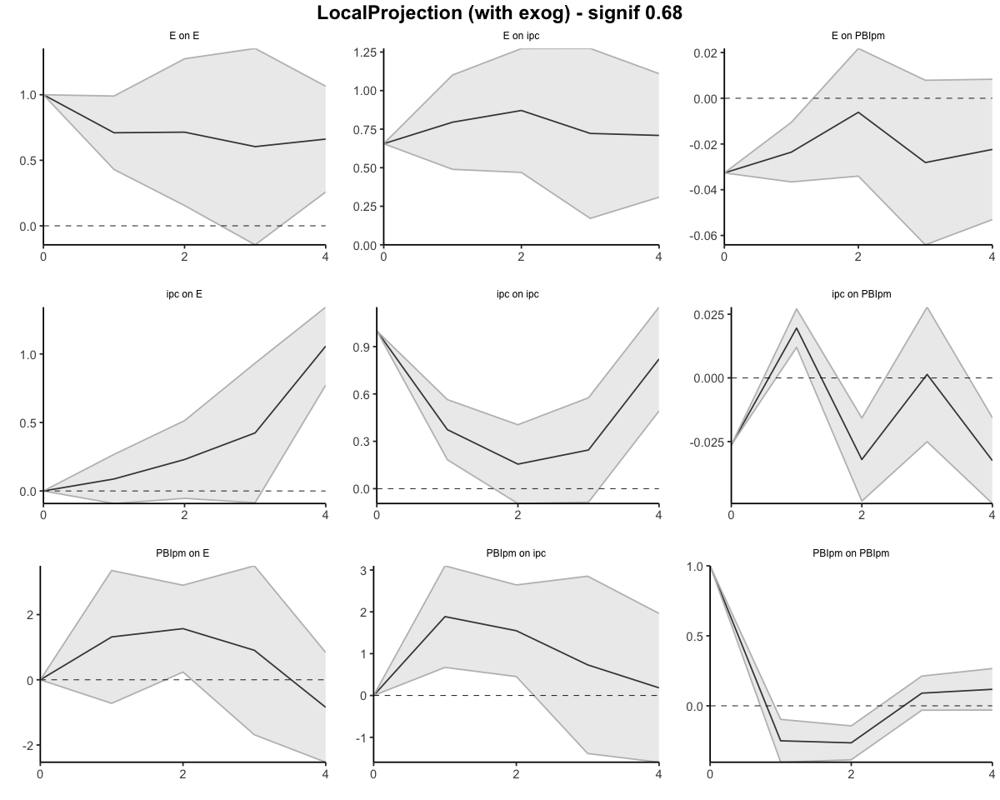

In [53]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIpm"), exog=c("impp_usa"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
1,NA,NaN,NA,1,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.0000000
12,ipc,E,1,0.08764741,-0.0916384,0.2669332
13,ipc,E,2,0.31735738,-0.1456554,0.7803701
14,ipc,E,3,0.74122160,-0.2312771,1.7137203
15,ipc,E,4,1.79841970,0.5411214,3.0557180


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.000000,0.0000000,0.000000
22,PBIpm,E,1,1.315261,-0.7226729,3.353194
23,PBIpm,E,2,2.884827,-0.4854536,6.255108
24,PBIpm,E,3,3.789692,-2.1719912,9.751375
25,PBIpm,E,4,2.944743,-4.7000940,10.589580


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6556007,0.6556007,0.6556007
2,E,ipc,1,1.4507975,1.1450232,1.7565718
3,E,ipc,2,2.3218740,1.6146560,3.0290919
4,E,ipc,3,3.0442219,1.7859373,4.3025066
5,E,ipc,4,3.7535820,2.0946370,5.4125270


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.0000000,0.000000
27,PBIpm,ipc,1,1.886035,0.6716266,3.100443
28,PBIpm,ipc,2,3.434260,1.1247247,5.743796
29,PBIpm,ipc,3,4.166554,-0.2633933,8.596501
30,PBIpm,ipc,4,4.349892,-1.8586895,10.558473


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.03265026,-0.03265026,-0.032650258
7,E,PBIpm,1,-0.05620195,-0.06924002,-0.043163875
8,E,PBIpm,2,-0.06233475,-0.10329190,-0.021377591
9,E,PBIpm,3,-0.09044984,-0.16738764,-0.013512033
10,E,PBIpm,4,-0.11282397,-0.22045093,-0.005197019


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.026358141,-0.02635814,-0.026358141
17,ipc,PBIpm,1,-0.006813874,-0.01437507,0.000747322
18,ipc,PBIpm,2,-0.038875612,-0.06274650,-0.015004727
19,ipc,PBIpm,3,-0.037507719,-0.08779649,0.012781055
20,ipc,PBIpm,4,-0.069979303,-0.13712538,-0.002833229


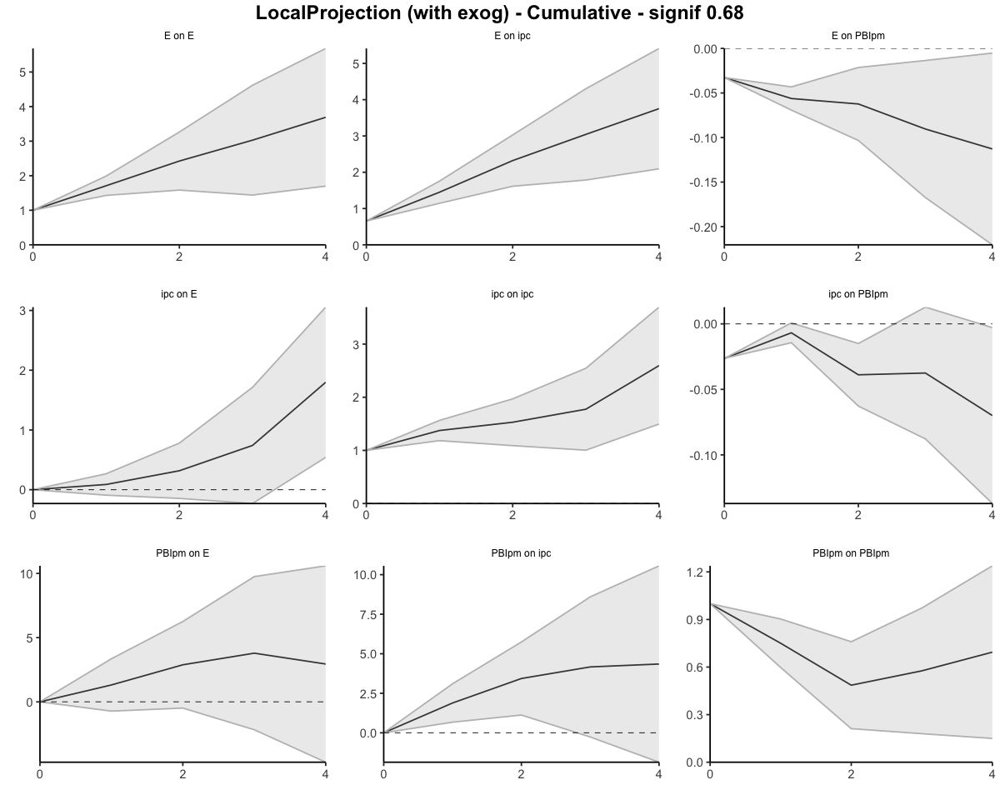

In [54]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIpm"), exog=c("impp_usa"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

#### impp_usa exógena y el resto endógenas - 1 lag

Bootstrap por bloques circular: 500 réplicas, bloques de 10 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 1 rezagos, exógenas: impp_usa )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.6556         0.6556       1.0000
         1              1.4508         0.8484       1.7100
         2              2.3219         0.9576       2.4246
         3              3.0442         1.0051       3.0287
         4              3.7536         1.0171       3.6904
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.6556             0.6556
                  0.7952             0.1928
                  0.8711             0.1092
                  0.7223             0.0475
                  0.7094             0.0120


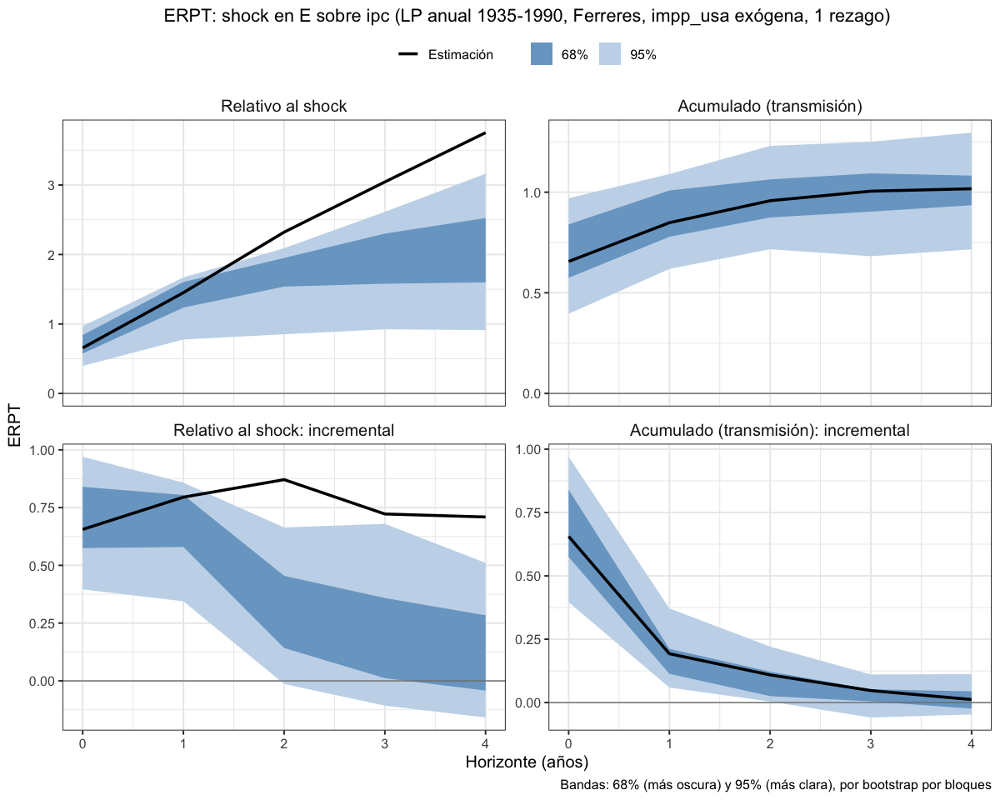

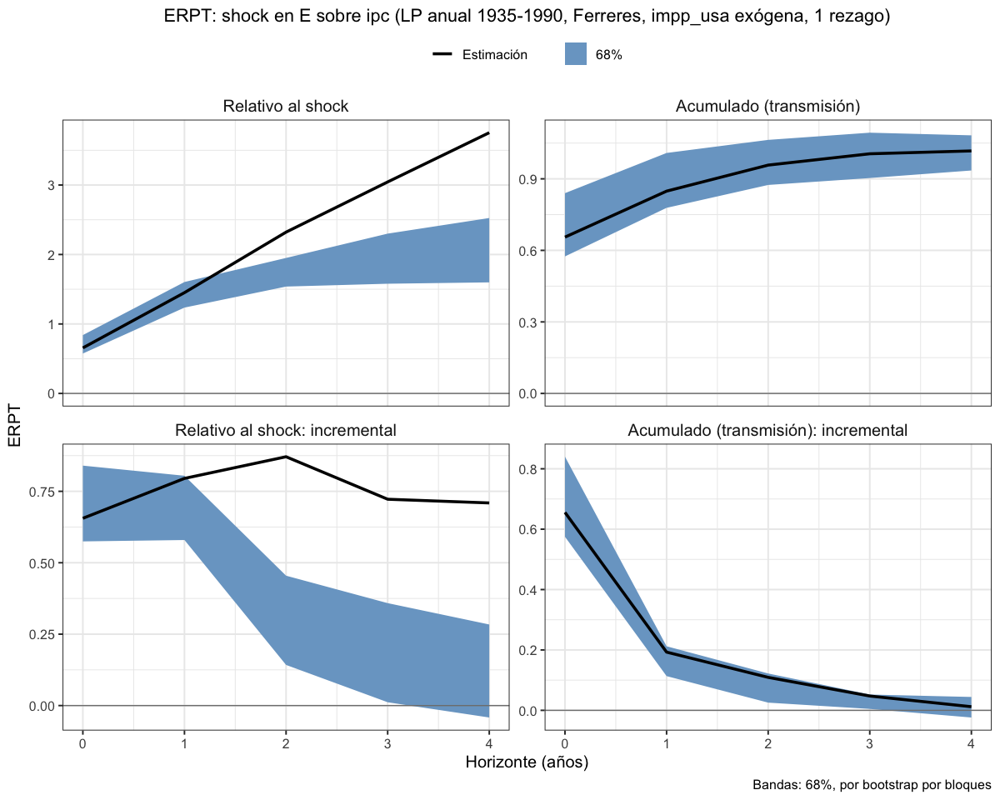

In [55]:
# Anual 1935–1990, Ferreres. impp_usa exógena y el resto endógenas, 1 rezago
lp_erpt_anual_ferr_35_90_exog_p1 <- erpt_lp(df_ERPT_Arg_1935_1990, endog = c("E", "ipc", "PBIpm"), exog = c("impp_usa"),
                                            fixed_lags = 1, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_ferr_35_90_exog_p1, "lp_erpt_anual_ferr_35_90_exog_p1.rds")
titulo_ferr_35_90_exog_p1 <- "ERPT: shock en E sobre ipc (LP anual 1935-1990, Ferreres, impp_usa exógena, 1 rezago)"
graficar_erpt_lp(lp_erpt_anual_ferr_35_90_exog_p1, titulo = titulo_ferr_35_90_exog_p1,
                 archivo = "lp_erpt_anual_ferr_35_90_exog_p1")
graficar_erpt_lp(lp_erpt_anual_ferr_35_90_exog_p1, titulo = titulo_ferr_35_90_exog_p1, niveles = 0.68,
                 archivo = "lp_erpt_anual_ferr_35_90_exog_p1_68")

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.0000000000
12,ipc,E,1,-0.2282154,-0.4993305,0.0428997473
13,ipc,E,2,-0.3994385,-0.7986817,-0.0001952175
14,ipc,E,3,-1.3605425,-1.9046938,-0.8163910718
15,ipc,E,4,-0.2979188,-0.5851321,-0.0107055408


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.0000000
22,PBIpm,E,1,1.3990077,-0.5395256,3.3375410
23,PBIpm,E,2,0.3959156,-0.5164469,1.3082780
24,PBIpm,E,3,-1.4972928,-3.2657308,0.2711452
25,PBIpm,E,4,-2.2411829,-3.5871938,-0.8951720


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.67193091,0.6719309,0.6719309
2,E,ipc,1,0.77431149,0.2889981,1.2596248
3,E,ipc,2,0.73878165,0.2355876,1.2419757
4,E,ipc,3,0.06327624,-0.6650892,0.7916417
5,E,ipc,4,0.11604629,-0.3571461,0.5892387


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.0000000
27,PBIpm,ipc,1,2.2335355,0.7783541,3.6887168
28,PBIpm,ipc,2,0.4944634,-0.5016599,1.4905867
29,PBIpm,ipc,3,-1.4569748,-2.7790850,-0.1348647
30,PBIpm,ipc,4,-1.4585003,-2.7534178,-0.1635827


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.03088325,-0.03088325,-0.0308832529
7,E,PBIpm,1,-0.01982097,-0.03916476,-0.0004771726
8,E,PBIpm,2,0.01016745,-0.01884947,0.0391843782
9,E,PBIpm,3,-0.01201215,-0.05173424,0.0277099355
10,E,PBIpm,4,-0.01864467,-0.05083672,0.0135473760


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.041143316,-0.041143316,-0.04114332
17,ipc,PBIpm,1,0.041257670,0.028235454,0.05427989
18,ipc,PBIpm,2,-0.005030147,-0.021494576,0.01143428
19,ipc,PBIpm,3,0.059819323,0.026512157,0.09312649
20,ipc,PBIpm,4,0.011856252,-0.007589515,0.03130202


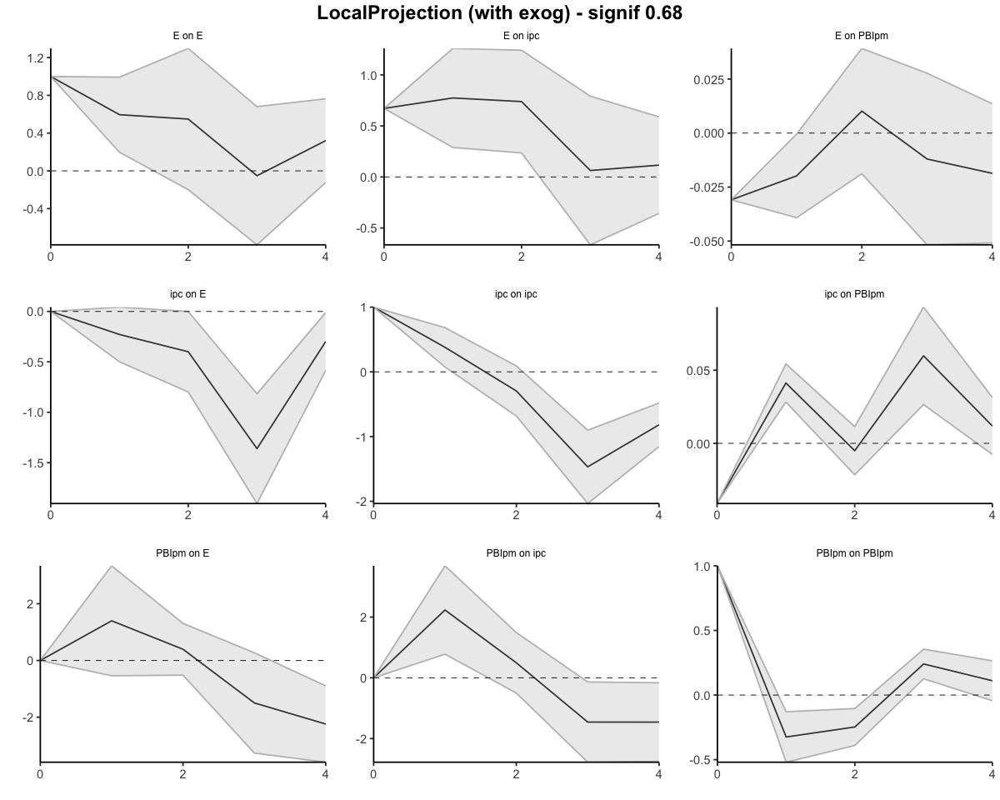

In [56]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIpm"), exog=c("impp_usa"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
2,NA,NaN,NA,2,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.00000000
12,ipc,E,1,-0.2282154,-0.4993305,0.04289975
13,ipc,E,2,-0.6276539,-1.2980123,0.04270453
14,ipc,E,3,-1.9881963,-3.2027061,-0.77368654
15,ipc,E,4,-2.2861151,-3.7878382,-0.78439208


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.000000
22,PBIpm,E,1,1.3990077,-0.5395256,3.337541
23,PBIpm,E,2,1.7949233,-1.0559725,4.645819
24,PBIpm,E,3,0.2976305,-4.3217033,4.916964
25,PBIpm,E,4,-1.9435524,-7.9088971,4.021792


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6719309,0.6719309,0.6719309
2,E,ipc,1,1.4462424,0.9609290,1.9315557
3,E,ipc,2,2.1850240,1.1965166,3.1735315
4,E,ipc,3,2.2483003,0.5314275,3.9651731
5,E,ipc,4,2.3643466,0.1742814,4.5544118


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.000000
27,PBIpm,ipc,1,2.2335355,0.7783541,3.688717
28,PBIpm,ipc,2,2.7279988,0.2766942,5.179304
29,PBIpm,ipc,3,1.2710240,-2.5023908,5.044439
30,PBIpm,ipc,4,-0.1874763,-5.2558087,4.880856


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.03088325,-0.03088325,-0.030883253
7,E,PBIpm,1,-0.05070422,-0.07004801,-0.031360426
8,E,PBIpm,2,-0.04053677,-0.08889749,0.007823953
9,E,PBIpm,3,-0.05254892,-0.14063173,0.035533888
10,E,PBIpm,4,-0.07119359,-0.19146845,0.049081264


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.0411433156,-0.04114332,-0.04114332
17,ipc,PBIpm,1,0.0001143546,-0.01290786,0.01313657
18,ipc,PBIpm,2,-0.0049157922,-0.03440244,0.02457085
19,ipc,PBIpm,3,0.0549035306,-0.00789028,0.11769734
20,ipc,PBIpm,4,0.0667597822,-0.01547979,0.14899936


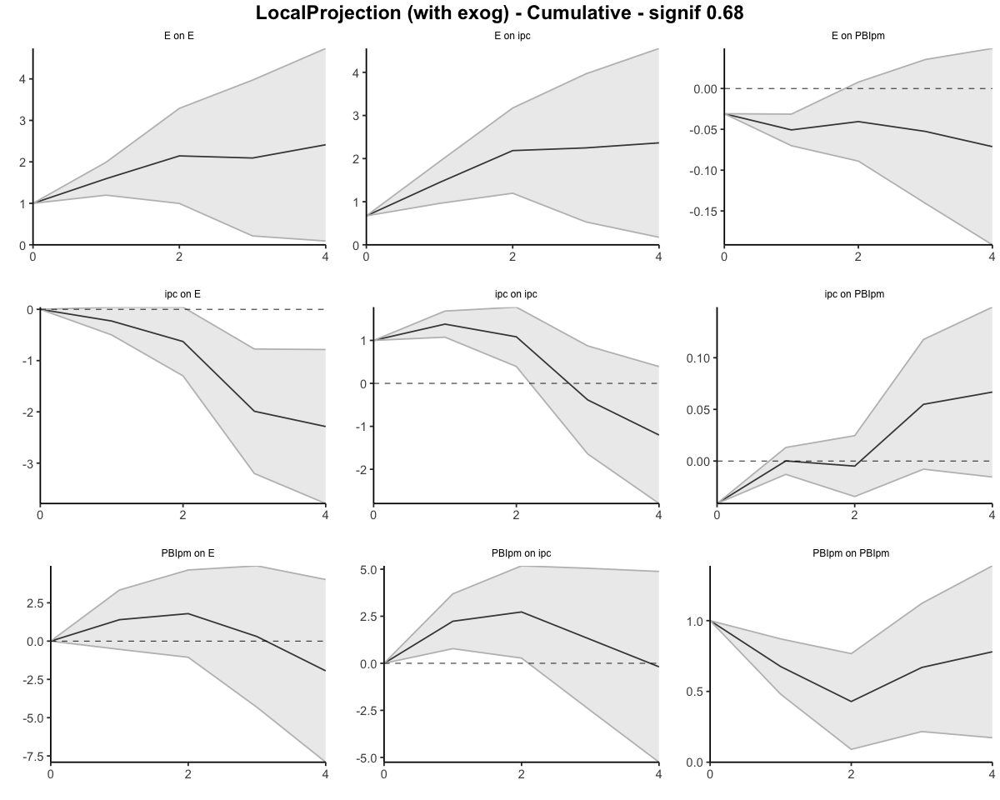

In [57]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIpm"), exog=c("impp_usa"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

#### impp_usa exógena y el resto endógenas - 2 lags

Bootstrap por bloques circular: 500 réplicas, bloques de 12 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 2 rezagos, exógenas: impp_usa )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.6719         0.6719       1.0000
         1              1.4462         0.9066       1.5952
         2              2.1850         1.0191       2.1442
         3              2.2483         1.0743       2.0928
         4              2.3643         0.9797       2.4133
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.6719             0.6719
                  0.7743             0.2347
                  0.7388             0.1124
                  0.0633             0.0552
                  0.1160            -0.0946


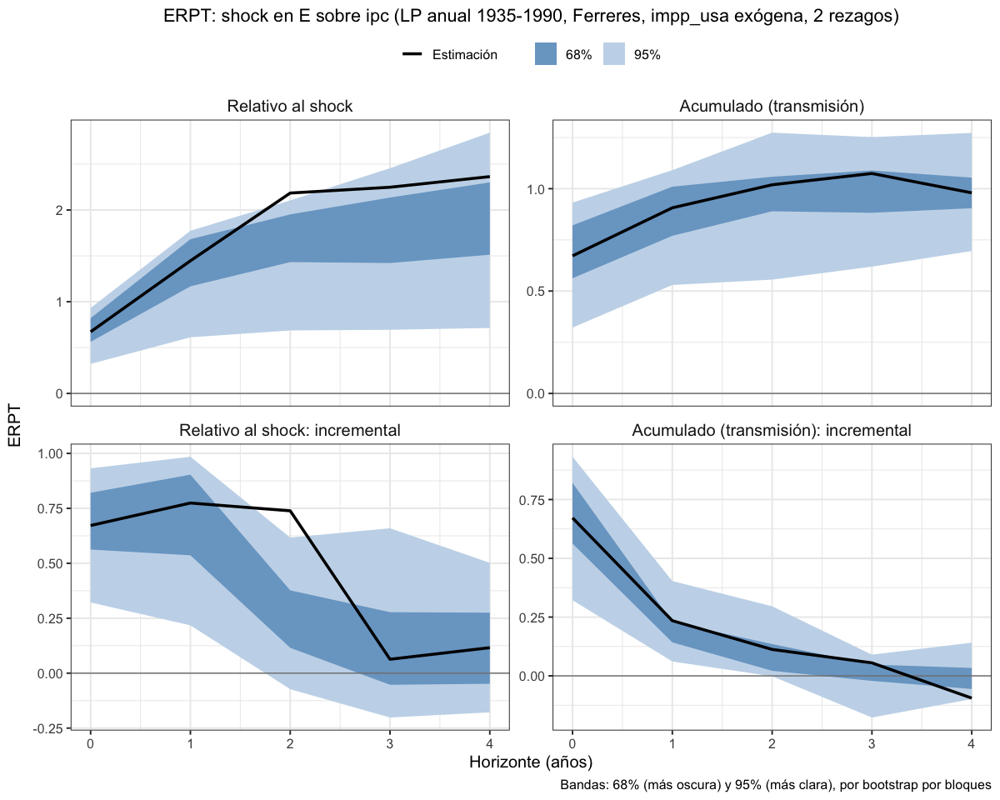

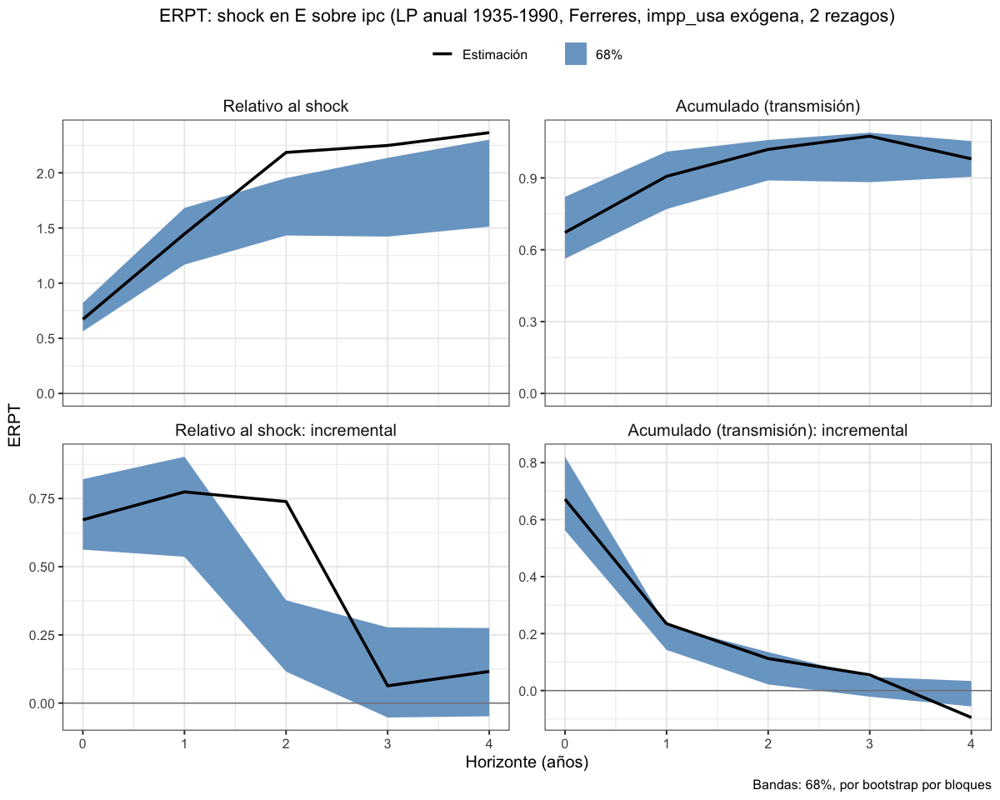

In [58]:
# Anual 1935–1990, Ferreres. impp_usa exógena y el resto endógenas, 2 rezagos
lp_erpt_anual_ferr_35_90_exog_p2 <- erpt_lp(df_ERPT_Arg_1935_1990, endog = c("E", "ipc", "PBIpm"), exog = c("impp_usa"),
                                            fixed_lags = 2, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_ferr_35_90_exog_p2, "lp_erpt_anual_ferr_35_90_exog_p2.rds")
titulo_ferr_35_90_exog_p2 <- "ERPT: shock en E sobre ipc (LP anual 1935-1990, Ferreres, impp_usa exógena, 2 rezagos)"
graficar_erpt_lp(lp_erpt_anual_ferr_35_90_exog_p2, titulo = titulo_ferr_35_90_exog_p2,
                 archivo = "lp_erpt_anual_ferr_35_90_exog_p2")
graficar_erpt_lp(lp_erpt_anual_ferr_35_90_exog_p2, titulo = titulo_ferr_35_90_exog_p2, niveles = 0.68,
                 archivo = "lp_erpt_anual_ferr_35_90_exog_p2_68")

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
4,NA,NaN,NA,4,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.00000000,0.0000000,0.0000000
12,ipc,E,1,-0.42353476,-0.7042226,-0.1428469
13,ipc,E,2,-0.11256063,-0.6501232,0.4250019
14,ipc,E,3,-0.82486627,-1.1503076,-0.4994249
15,ipc,E,4,0.07785663,-0.1050108,0.2607241


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.00000000,0.000000,0.00000000
22,PBIpm,E,1,1.24687038,-0.623292,3.11703281
23,PBIpm,E,2,-0.05108923,-1.482832,1.38065404
24,PBIpm,E,3,-1.05578037,-2.140239,0.02867777
25,PBIpm,E,4,-1.26588743,-2.514225,-0.01755023


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.61228300,0.6122830,0.6122830
2,E,ipc,1,0.69605707,0.3315924,1.0605218
3,E,ipc,2,0.24274427,-0.4097520,0.8952405
4,E,ipc,3,-0.01741828,-0.5811359,0.5462993
5,E,ipc,4,0.25282369,-0.3144834,0.8201308


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.0000000
27,PBIpm,ipc,1,2.6052445,1.5522440,3.6582449
28,PBIpm,ipc,2,0.8041942,-0.6073702,2.2157586
29,PBIpm,ipc,3,-1.5895655,-2.4390776,-0.7400534
30,PBIpm,ipc,4,-1.2185241,-2.5429422,0.1058940


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.01878003,-0.01878003,-0.018780034
7,E,PBIpm,1,-0.01803842,-0.04083418,0.004757349
8,E,PBIpm,2,0.01682340,-0.01103228,0.044679092
9,E,PBIpm,3,-0.01899964,-0.05177855,0.013779269
10,E,PBIpm,4,-0.01958223,-0.04744210,0.008277633


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.06015670,-0.0601567040,-0.06015670
17,ipc,PBIpm,1,0.07469404,0.0650383830,0.08434969
18,ipc,PBIpm,2,-0.03916764,-0.0562341393,-0.02210114
19,ipc,PBIpm,3,0.02329584,0.0052522039,0.04133947
20,ipc,PBIpm,4,0.01602758,-0.0002144921,0.03226964


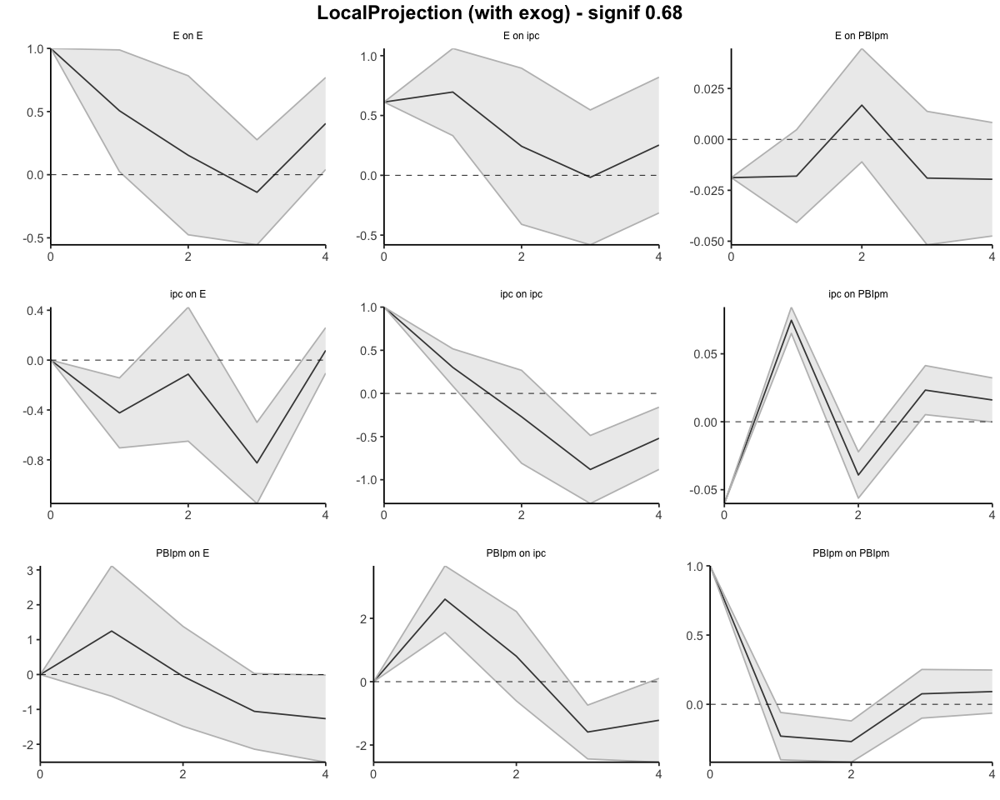

In [59]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIpm"), exog=c("impp_usa"), fixed_lags = 4, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
4,NA,NaN,NA,4,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.00000000
12,ipc,E,1,-0.4235348,-0.7042226,-0.14284691
13,ipc,E,2,-0.5360954,-1.3543458,0.28215500
14,ipc,E,3,-1.3609617,-2.5046534,-0.21726991
15,ipc,E,4,-1.2831050,-2.6096642,0.04345415


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.000000,0.000000
22,PBIpm,E,1,1.2468704,-0.623292,3.117033
23,PBIpm,E,2,1.1957812,-2.106125,4.497687
24,PBIpm,E,3,0.1400008,-4.246363,4.526365
25,PBIpm,E,4,-1.1258866,-6.760588,4.508814


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.612283,0.61228300,0.612283
2,E,ipc,1,1.308340,0.94387536,1.672805
3,E,ipc,2,1.551084,0.53412340,2.568045
4,E,ipc,3,1.533666,-0.04701248,3.114345
5,E,ipc,4,1.786490,-0.36149589,3.934475


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.000000
27,PBIpm,ipc,1,2.6052445,1.5522440,3.658245
28,PBIpm,ipc,2,3.4094386,0.9448738,5.874004
29,PBIpm,ipc,3,1.8198732,-1.4942038,5.133950
30,PBIpm,ipc,4,0.6013491,-4.0371460,5.239844


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.01878003,-0.01878003,-0.01878003
7,E,PBIpm,1,-0.03681845,-0.05961421,-0.01402268
8,E,PBIpm,2,-0.01999504,-0.07064650,0.03065641
9,E,PBIpm,3,-0.03899469,-0.12242505,0.04443568
10,E,PBIpm,4,-0.05857692,-0.16986715,0.05271331


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.060156704,-0.060156704,-0.060156704
17,ipc,PBIpm,1,0.014537334,0.004881679,0.024192989
18,ipc,PBIpm,2,-0.024630306,-0.051352460,0.002091848
19,ipc,PBIpm,3,-0.001334471,-0.046100256,0.043431315
20,ipc,PBIpm,4,0.014693105,-0.046314749,0.075700959


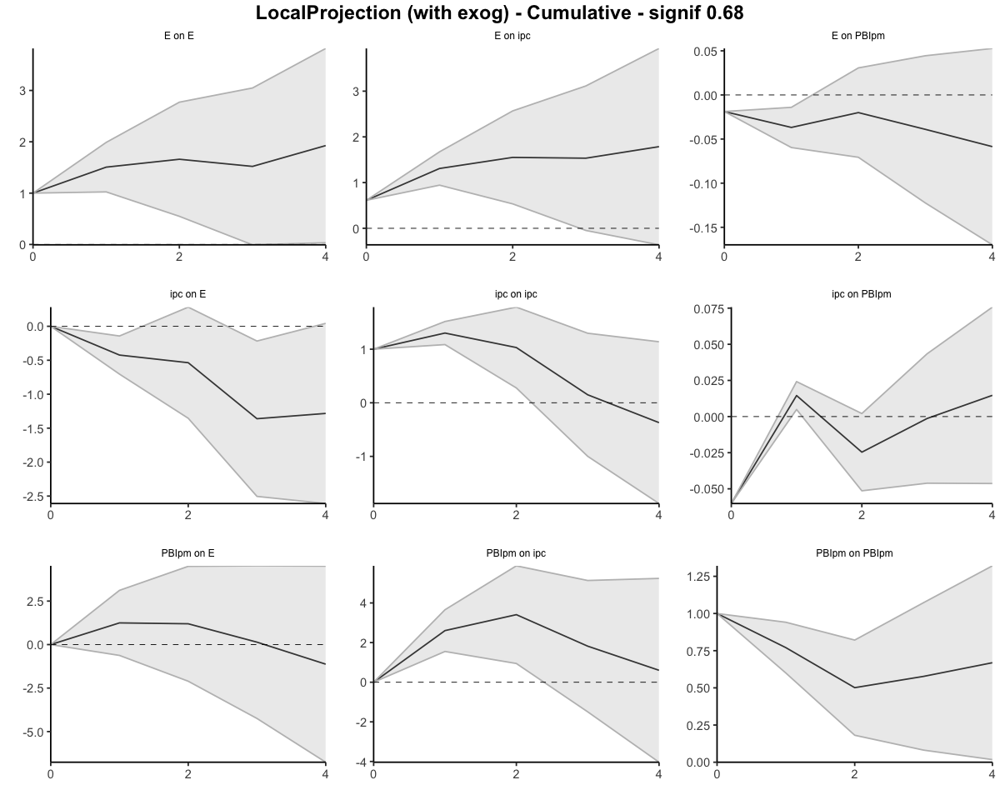

In [60]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIpm"), exog=c("impp_usa"), fixed_lags = 4, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

#### impp_usa exógena y el resto endógenas - 4 lags

Bootstrap por bloques circular: 500 réplicas, bloques de 16 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 4 rezagos, exógenas: impp_usa )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.6123         0.6123       1.0000
         1              1.3083         0.8686       1.5063
         2              1.5511         0.9343       1.6601
         3              1.5337         1.0084       1.5208
         4              1.7865         0.9273       1.9265
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.6123             0.6123
                  0.6961             0.2563
                  0.2427             0.0658
                 -0.0174             0.0741
                  0.2528            -0.0811


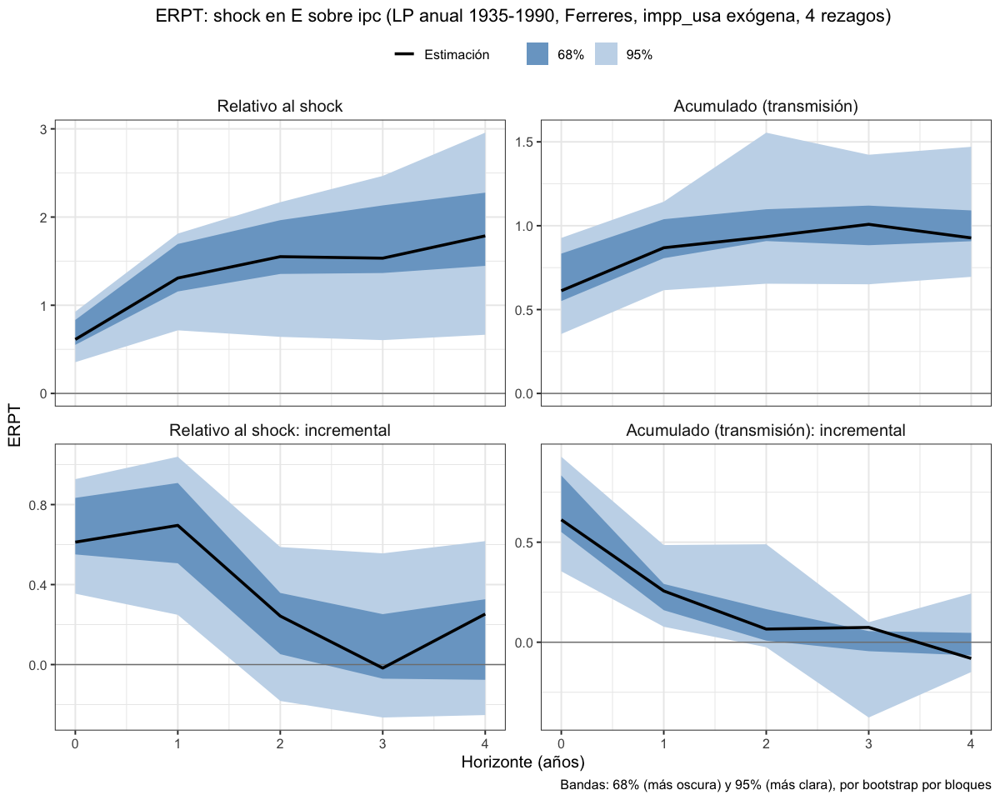

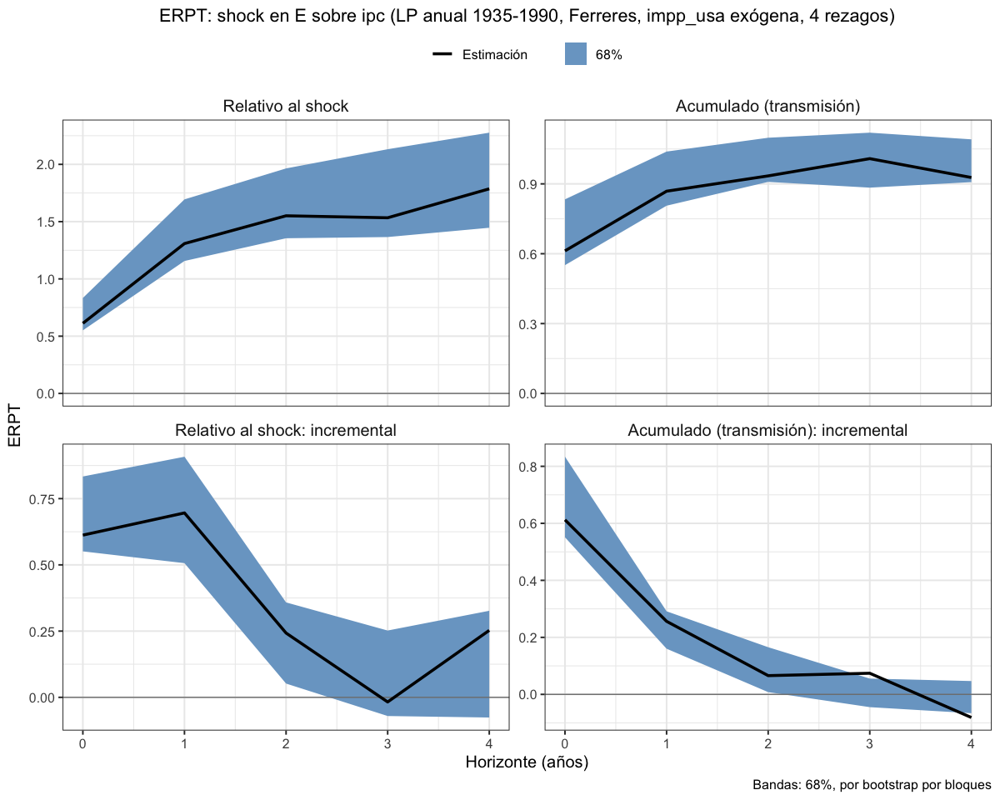

In [61]:
# Anual 1935–1990, Ferreres. impp_usa exógena y el resto endógenas, 4 rezagos
lp_erpt_anual_ferr_35_90_exog_p4 <- erpt_lp(df_ERPT_Arg_1935_1990, endog = c("E", "ipc", "PBIpm"), exog = c("impp_usa"),
                                            fixed_lags = 4, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_ferr_35_90_exog_p4, "lp_erpt_anual_ferr_35_90_exog_p4.rds")
titulo_ferr_35_90_exog_p4 <- "ERPT: shock en E sobre ipc (LP anual 1935-1990, Ferreres, impp_usa exógena, 4 rezagos)"
graficar_erpt_lp(lp_erpt_anual_ferr_35_90_exog_p4, titulo = titulo_ferr_35_90_exog_p4,
                 archivo = "lp_erpt_anual_ferr_35_90_exog_p4")
graficar_erpt_lp(lp_erpt_anual_ferr_35_90_exog_p4, titulo = titulo_ferr_35_90_exog_p4, niveles = 0.68,
                 archivo = "lp_erpt_anual_ferr_35_90_exog_p4_68")

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
5,NA,NaN,NA,5,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIpm",3


LocalProjection (with exog) - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.00000000,0.0000000
12,ipc,E,1,-0.3899478,-0.61254747,-0.1673481
13,ipc,E,2,0.2229159,-0.03621802,0.4820498
14,ipc,E,3,-0.8688841,-1.24350625,-0.4942620
15,ipc,E,4,-0.1135039,-0.31195854,0.0849507


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.0000000,0.0000000,0.0000000
22,PBIpm,E,1,2.8982012,1.5122389,4.2841635
23,PBIpm,E,2,1.5769089,0.6328664,2.5209514
24,PBIpm,E,3,-1.5574538,-2.4685252,-0.6463824
25,PBIpm,E,4,-0.3537994,-1.5164191,0.8088203


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.63258048,0.6325805,0.6325805
2,E,ipc,1,0.59025974,0.3334432,0.8470763
3,E,ipc,2,0.16264865,-0.4027509,0.7280482
4,E,ipc,3,-0.03135969,-1.3894936,1.3267742
5,E,ipc,4,0.36697325,-0.0542711,0.7882176


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.0000000,0.0000000,0.0000000
27,PBIpm,ipc,1,3.5614083,2.6705347,4.4522818
28,PBIpm,ipc,2,2.0961988,0.3780492,3.8143484
29,PBIpm,ipc,3,-0.9335028,-2.5073797,0.6403740
30,PBIpm,ipc,4,-0.3837278,-1.3458725,0.5784169


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.008059757,-0.008059757,-0.008059757
7,E,PBIpm,1,-0.008036678,-0.033801679,0.017728324
8,E,PBIpm,2,0.011907961,-0.023905938,0.047721860
9,E,PBIpm,3,-0.018886176,-0.057214927,0.019442575
10,E,PBIpm,4,-0.012573707,-0.068771544,0.043624130


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.060222880,-0.06022288,-0.06022288
17,ipc,PBIpm,1,0.084063887,0.07345019,0.09467758
18,ipc,PBIpm,2,-0.039599733,-0.06111814,-0.01808133
19,ipc,PBIpm,3,0.005686136,-0.01242364,0.02379591
20,ipc,PBIpm,4,0.076052692,0.03666392,0.11544146


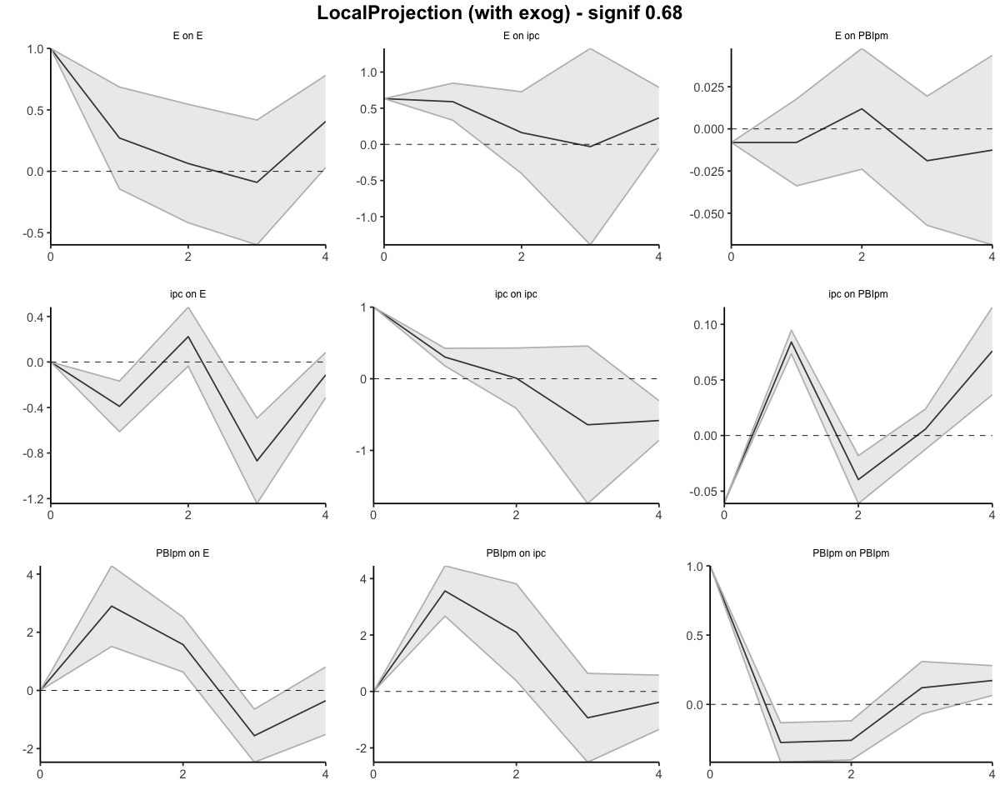

In [62]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIpm"), exog=c("impp_usa"), fixed_lags = 5, newey_lags = 10, signif = 0.68, horizons = 4)

Run configurations:

lags_endog_lin,lags_endog_nl,lags_criterion,max_lags,lags_exog,trend,shock_type,confint,hor,use_nw,nw_prewhite,nw_lag,adjust_se,use_twosls,model_type,starts,ends,column_names,endog
<dbl>,<lgl>,<dbl>,<lgl>,<dbl>,<dbl>,<dbl>,<chr>,<dbl>,<lgl>,<lgl>,<dbl>,<lgl>,<lgl>,<dbl>,<dbl>,<int>,<chr>,<int>
5,NA,NaN,NA,5,0,1,0.68,4,TRUE,TRUE,10,FALSE,FALSE,0,1,55,"E, ipc, PBIpm",3


LocalProjection (with exog) - Cumulative - signif 0.68

,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
11,ipc,E,0,0.0000000,0.0000000,0.00000000
12,ipc,E,1,-0.3899478,-0.6125475,-0.16734805
13,ipc,E,2,-0.1670319,-0.6487655,0.31470175
14,ipc,E,3,-1.0359160,-1.8922717,-0.17956028
15,ipc,E,4,-1.1494199,-2.2042303,-0.09460958


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
21,PBIpm,E,0,0.000000,0.0000000,0.000000
22,PBIpm,E,1,2.898201,1.5122389,4.284163
23,PBIpm,E,2,4.475110,2.1451053,6.805115
24,PBIpm,E,3,2.917656,-0.3234199,6.158732
25,PBIpm,E,4,2.563857,-1.8398390,6.967553


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
1,E,ipc,0,0.6325805,0.6325805,0.6325805
2,E,ipc,1,1.2228402,0.9660237,1.4796568
3,E,ipc,2,1.3854889,0.5632727,2.2077050
4,E,ipc,3,1.3541292,-0.8262209,3.5344792
5,E,ipc,4,1.7211024,-0.8804919,4.3226968


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
26,PBIpm,ipc,0,0.000000,0.0000000,0.000000
27,PBIpm,ipc,1,3.561408,2.6705347,4.452282
28,PBIpm,ipc,2,5.657607,3.0485840,8.266630
29,PBIpm,ipc,3,4.724104,0.5412043,8.907004
30,PBIpm,ipc,4,4.340376,-0.8046683,9.485421


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
6,E,PBIpm,0,-0.008059757,-0.008059757,-0.008059757
7,E,PBIpm,1,-0.016096435,-0.041861437,0.009668566
8,E,PBIpm,2,-0.004188474,-0.065767375,0.057390426
9,E,PBIpm,3,-0.023074650,-0.122982302,0.076833002
10,E,PBIpm,4,-0.035648358,-0.191753846,0.120457131


,impulse,response,horizon,irf_value,lower_bound,upper_bound
,<chr>,<chr>,<int>,<dbl>,<dbl>,<dbl>
16,ipc,PBIpm,0,-0.06022288,-0.06022288,-0.06022288
17,ipc,PBIpm,1,0.02384101,0.01322731,0.03445470
18,ipc,PBIpm,2,-0.01575873,-0.04789083,0.01637338
19,ipc,PBIpm,3,-0.01007259,-0.06031447,0.04016929
20,ipc,PBIpm,4,0.06598010,-0.02365055,0.15561075


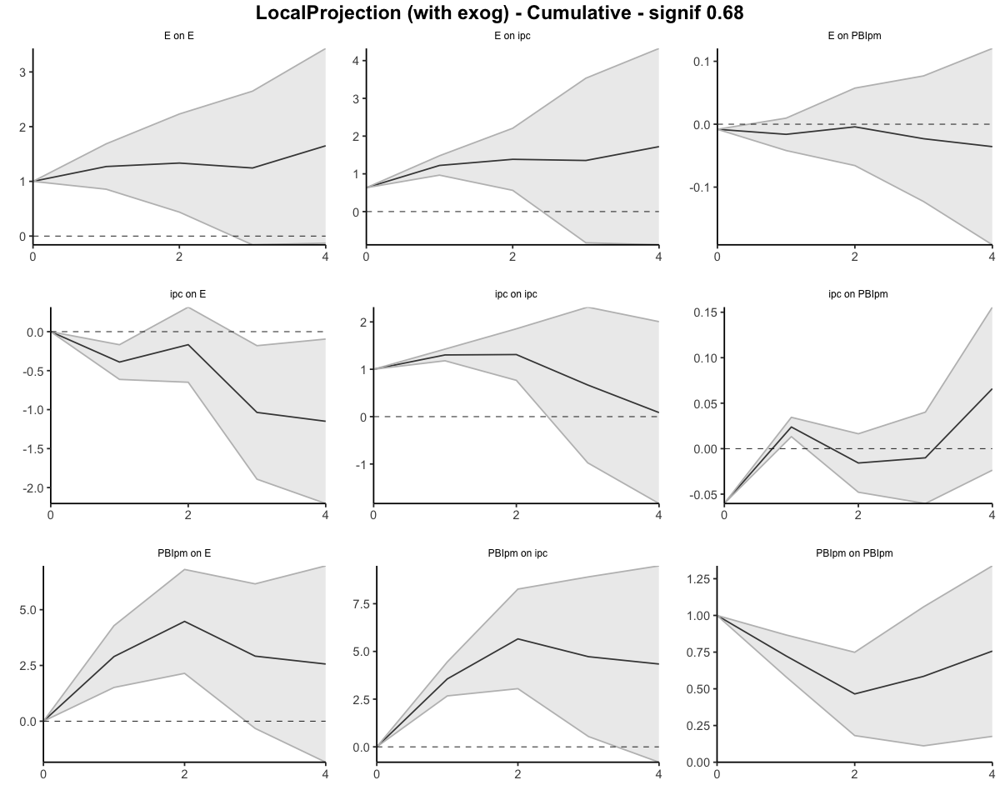

In [63]:
res <- run_lp_model(df_ERPT_Arg_1935_1990, endog=c("E", "ipc", "PBIpm"), exog=c("impp_usa"), fixed_lags = 5, newey_lags = 10, signif = 0.68, horizons = 4, cumulative=TRUE)

#### impp_usa exógena y el resto endógenas - 5 lags

Bootstrap por bloques circular: 500 réplicas, bloques de 18 años...



  |======================================================================| 100%
ERPT de un shock unitario en E sobre ipc ( LP, 5 rezagos, exógenas: impp_usa )

Lineal
 horizonte erpt_relativo_shock erpt_acumulado persistencia
         0              0.6326         0.6326       1.0000
         1              1.2228         0.9619       1.2713
         2              1.3855         1.0380       1.3348
         3              1.3541         1.0881       1.2445
         4              1.7211         1.0427       1.6506
 erpt_relativo_shock_inc erpt_acumulado_inc
                  0.6326             0.6326
                  0.5903             0.3293
                  0.1626             0.0761
                 -0.0314             0.0501
                  0.3670            -0.0453


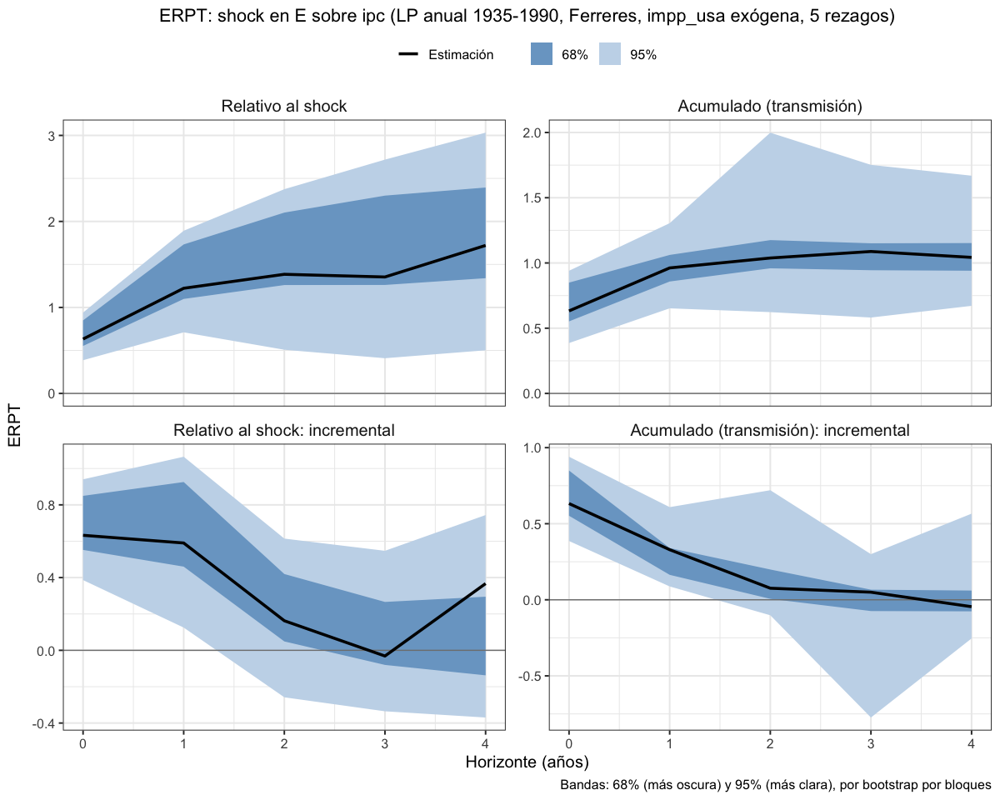

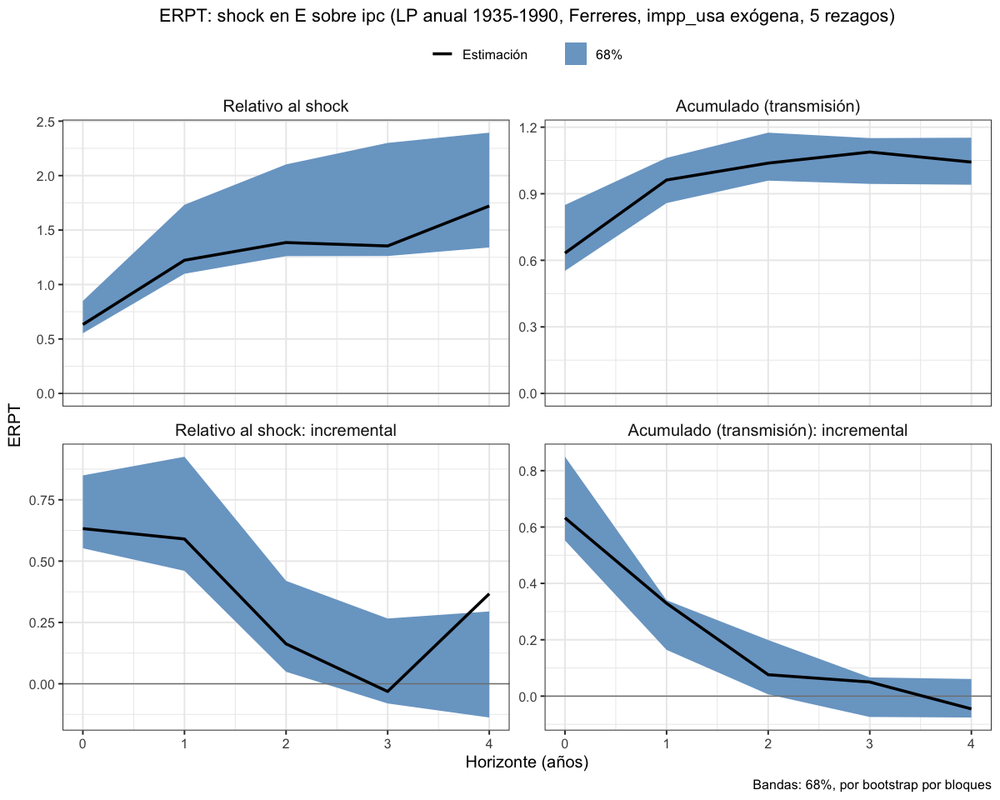

In [64]:
# Anual 1935–1990, Ferreres. impp_usa exógena y el resto endógenas, 5 rezagos
lp_erpt_anual_ferr_35_90_exog_p5 <- erpt_lp(df_ERPT_Arg_1935_1990, endog = c("E", "ipc", "PBIpm"), exog = c("impp_usa"),
                                            fixed_lags = 5, horizons = 4, reps = 500, unidad = "años")
saveRDS(lp_erpt_anual_ferr_35_90_exog_p5, "lp_erpt_anual_ferr_35_90_exog_p5.rds")
titulo_ferr_35_90_exog_p5 <- "ERPT: shock en E sobre ipc (LP anual 1935-1990, Ferreres, impp_usa exógena, 5 rezagos)"
graficar_erpt_lp(lp_erpt_anual_ferr_35_90_exog_p5, titulo = titulo_ferr_35_90_exog_p5,
                 archivo = "lp_erpt_anual_ferr_35_90_exog_p5")
graficar_erpt_lp(lp_erpt_anual_ferr_35_90_exog_p5, titulo = titulo_ferr_35_90_exog_p5, niveles = 0.68,
                 archivo = "lp_erpt_anual_ferr_35_90_exog_p5_68")

### 1950-2023. Todas endógenas (DESDE acá no están actualizados)

In [65]:
#res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("Psoja_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

In [66]:
#res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("Psoja_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative = TRUE)

In [67]:
#res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("Pmaíz_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

In [68]:
#res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("Pmaíz_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative = TRUE)

In [69]:
#res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("Pmaíz_USA", "E", "ipc", "PBIpm"), fixed_lags = 2, horizons=4, signif = 0.68, newey_lags = 10)

In [70]:
#res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("Pmaíz_USA", "E", "ipc", "PBIpm"), fixed_lags = 2, horizons=4, signif = 0.68, newey_lags = 10, cumulative = TRUE)

In [71]:
#res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10)

In [72]:
#res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 1, horizons=4, signif = 0.68, newey_lags = 10, cumulative = TRUE)

In [73]:
#res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 2, horizons=4, signif = 0.68, newey_lags = 10)

In [74]:
#res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("Ptrigo_USA", "E", "ipc", "PBIpm"), fixed_lags = 2, horizons=4, signif = 0.68, newey_lags = 10, cumulative = TRUE)

### 1950-2023. 1 exógena y el resto endógenas

In [75]:
#res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Psoja_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

In [76]:
#res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Psoja_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative = TRUE)

In [77]:
#res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Psoja_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4)

In [78]:
#res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Psoja_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4, cumulative = TRUE)

In [79]:
#res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Pmaíz_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

In [80]:
#res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Pmaíz_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative = TRUE)

In [81]:
#res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Pmaíz_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4)

In [82]:
#res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Pmaíz_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4, cumulative = TRUE)

In [83]:
#res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Ptrigo_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4)

In [84]:
#res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Ptrigo_USA"), fixed_lags = 1, newey_lags = 10, signif = 0.68, horizons = 4, cumulative = TRUE)

In [85]:
#res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Ptrigo_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4)

In [86]:
#res <- run_lp_model(df_ERPT_Arg_1950_2023, endog=c("E", "ipc", "PBIpm"), exog=c("Ptrigo_USA"), fixed_lags = 2, newey_lags = 10, signif = 0.68, horizons = 4, cumulative = TRUE)